# Part A: CIFAR-10 Image Generation

## Investigation Overview

I compare a convolutional variational autoencoder (VAE) and a convolutional generative adversarial network (GAN) on CIFAR-10, then develop the stronger family through controlled experiments. The final model must generate 1,000 unfiltered RGB images while retaining variation and recognisable class structure.

The investigation follows four stages:

1. Review the generation problem, both model families and suitable evaluation methods.
2. Inspect CIFAR-10 and decide whether cleaning, feature engineering or augmentation is justified.
3. Establish comparable VAE and GAN baselines, then improve the selected family one factor at a time.
4. Evaluate the selected model using distribution, class-level, visual and diversity evidence before verifying its saved weights.

The official test partition is excluded from model development. All model choices use the validation partition, fixed latent inputs and unfiltered samples; test-set performance is calculated only after selection is frozen.


# 1. Background Research

## 1.1 CIFAR-10 Generation Problem

CIFAR-10 contains 60,000 colour images with a resolution of `32 x 32`, divided evenly among ten object classes. Keras provides 50,000 training images and 10,000 test images. The classes contain both vehicles and animals, with variation in pose, scale, colour and background.

The low resolution has two opposing effects:

- It keeps training computationally manageable.
- It removes fine object details, making semantically similar classes such as cat, dog and deer difficult to distinguish.

A useful generator must do more than reproduce the average colour distribution. It should produce plausible local structure, maintain variation between samples and cover all ten classes without relying on filtered or hand-selected outputs.

The original CIFAR report describes the collection and label-verification process. Later studies identified near-duplicates and possible label errors in common image benchmarks. I audit exact duplicates, label validity and structural quality without automatically relabelling or removing images. Near-duplicate detection and manual relabelling depend on subjective thresholds and would change the assigned dataset.

**Sources:** [Krizhevsky (2009), CIFAR report](https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf); [Barz and Denzler (2020), CIFAR near-duplicates](https://arxiv.org/abs/1902.00423); [Northcutt, Athalye and Mueller (2021), benchmark label errors](https://datasets-benchmarks-proceedings.neurips.cc/paper/2021/hash/f2217062e9a397a1dca429e7d70bc6ca-Abstract-round1.html).


## 1.2 Variational Autoencoders

### 1.2.1 Framework

A VAE contains an encoder and decoder:

- The encoder maps an image `x` to the parameters of an approximate latent distribution, normally `z_mean` and `z_log_var`.
- The reparameterisation step samples `epsilon ~ N(0, I)` and computes `z = z_mean + exp(0.5 * z_log_var) * epsilon`.
- The decoder maps `z` back to an image.

The stochastic latent representation is the main difference from a deterministic autoencoder. Regularising the latent distribution towards a known prior allows new images to be generated by sampling `z ~ N(0, I)` rather than encoding an existing image first.

For CIFAR-10, convolutional layers are appropriate because they preserve local spatial relationships while reducing or increasing image resolution.

**Source:** [Kingma and Welling, Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114).

### 1.2.2 Loss Function

The VAE objective combines reconstruction and latent regularisation:

$$
L_{VAE} = L_{reconstruction} + \beta L_{KL}
$$

- **Reconstruction loss** measures how closely the decoded image matches its input.
- **KL-divergence loss** encourages the approximate posterior to remain close to the standard normal prior.
- `beta` controls the balance. A larger value can produce a more regular latent space but may sacrifice reconstruction detail.

These terms must be inspected separately. A low total loss alone does not establish that samples drawn from the prior are realistic, while an extremely small KL term can indicate that the decoder is ignoring latent information.

The baseline uses the unweighted taught objective (`beta = 1`). Changing the KL weight before observing a problem would add a tuning decision without evidence.


### 1.2.3 Strengths and Limitations

| Aspect | Expected strength | Limitation for this task |
|---|---|---|
| Training | One differentiable objective usually gives interpretable reconstruction and KL curves | Stable optimisation does not guarantee realistic prior samples |
| Latent space | Regularisation supports random sampling and interpolation | Excessive regularisation can remove image-specific information |
| Coverage | The probabilistic objective can represent broad variation | Pixel reconstruction can average multiple plausible details |
| Image appearance | Reconstructions normally preserve broad colour and shape | Samples can appear smooth or blurry on complex colour images |
| Evaluation | Reconstruction and latent behaviour can be inspected directly | Reconstruction quality is not comparable to GAN sample quality by itself |

The VAE is therefore a credible baseline rather than an intentionally weak model. It provides a stable contrast to adversarial training and may reveal whether latent coverage is obtained at the cost of fine visual detail.

## 1.3 Generative Adversarial Networks

### 1.3.1 Framework

A GAN trains two networks in competition:

- The generator `G(z)` converts random noise into an image.
- The discriminator `D(x)` predicts whether an image is real or generated.
- The discriminator learns from both training images and generated images.
- The generator learns through the discriminator's response and attempts to make generated images look real.

The original GAN framework can use multilayer perceptrons, but CIFAR-10 is spatial image data. I use a modest convolutional implementation so the baseline is credible without already including every later stabilisation method. Any later architectural change must still be identified explicitly and compared with this parent model. The later conditional model uses a projection-conditioned source score: a learned class vector is compared directly with image features, allowing the discriminator to model image-label compatibility instead of adding only a class-specific bias.

**Sources:** [Goodfellow et al. (2014), Generative Adversarial Nets](https://papers.neurips.cc/paper_files/paper/2014/hash/f033ed80deb0234979a61f95710dbe25-Abstract.html); [Radford, Metz and Chintala (2016), DCGAN](https://arxiv.org/abs/1511.06434); [Miyato and Koyama (2018), Projection Discriminator](https://openreview.net/forum?id=ByS1VpgRZ).


### 1.3.2 Adversarial Loss

The discriminator's binary objective is:

$$
L_D = -E_{x \sim p_{data}}[\log D(x)]
      -E_{z \sim p_z}[\log(1-D(G(z)))]
$$

The generator uses the common non-saturating objective:

$$
L_G = -E_{z \sim p_z}[\log D(G(z))]
$$

The non-saturating form gives the generator a stronger learning signal when the discriminator initially rejects generated images confidently.

GAN losses are optimisation diagnostics, not direct image-quality scores. A low generator loss can occur because the discriminator is weak, and a discriminator accuracy near 50% can mean either a balanced game or two networks that have both failed. Generated samples and distributional evidence must be inspected alongside the losses.


### 1.3.3 Training Difficulties

| Difficulty | Observable evidence | Candidate response if observed |
|---|---|---|
| Discriminator overconfidence | Near-perfect real/fake accuracy, rising generator loss and stalled fixed samples | One-sided label smoothing or discriminator learning-rate review |
| Generator/discriminator imbalance | One network improves while the other receives little useful signal | Review separate learning rates using a controlled change |
| Mode collapse | Different latent inputs produce highly similar images or limited class coverage | Investigate diversity and training balance before adding complexity |
| Checkerboard artefacts | Repeated grid-like texture at the upsampling scale | Compare transposed convolution with resize-convolution |
| Non-convergence | Oscillating diagnostics with no sustained sample improvement | Review architecture, learning rates and update schedule |
| Discriminator overfitting | Strong training discrimination without corresponding generated improvement | Consider a controlled, non-leaking augmentation method |

These are candidate responses, not preselected experiments. I test an intervention only when the parent model shows the corresponding weakness.

**Sources:** [Odena, Dumoulin and Olah (2016), checkerboard artefacts](https://distill.pub/2016/deconv-checkerboard/); [Heusel et al. (2017), two time-scale updates](https://proceedings.neurips.cc/paper/2017/hash/8a1d694707eb0fefe65871369074926d-Abstract.html); [Salimans et al. (2016), GAN training techniques](https://papers.nips.cc/paper_files/paper/2016/hash/8a3363abe792db2d8761d6403605aeb7-Abstract.html).


## 1.4 VAE-versus-GAN Comparison

| Question | VAE | GAN | Comparison basis |
|---|---|---|---|
| What is learned? | Encoder, regularised latent distribution and decoder | Generator distribution through a discriminator | Generate new images from each model's prior |
| Training signal | Reconstruction plus KL divergence | Adversarial real/fake feedback | Keep diagnostics framework-specific |
| Expected appearance | Stable broad structure, potentially smoother details | Potentially sharper structure, potentially unstable | Fixed unfiltered grids plus distributional evaluation |
| Diversity risk | Excessive averaging or posterior collapse | Mode collapse | Diversity and coverage evidence |
| Direct loss comparison | Meaningful within VAE runs | Meaningful within GAN runs | Never compare VAE and GAN loss magnitudes |

I implement both because the two objectives expose a genuine design decision for CIFAR-10. The result is not a universal ranking; it applies only to the architectures, training exposure, seed, dataset split and evaluation pipeline used here.

To keep the family comparison interpretable:

- Both models train on the same stratified 45,000-image subset of the official training partition; the remaining 5,000 training records form validation evidence.
- Both models use complete dataset epochs. Training exposure and optimiser-update counts are reported explicitly.
- Generated sample counts, real reference images, preprocessing and evaluation network remain fixed.
- The selected family must be supported by more than a lower FID value.


## 1.5 Evaluation of Generative Models

### 1.5.1 Why GAN/VAE Evaluation Is Difficult

A generated-image model can fail in different ways:

- Images may be sharp but cover only a few modes.
- Images may be diverse but unrealistic.
- Aggregate statistics may look reasonable while individual samples are nonsense.
- A conditional model may produce plausible images that do not match the requested class.
- A model may repeat or memorise training examples.

No single scalar separates all these cases. Each selected method has one role, and disagreements are examined instead of hidden inside a weighted score.


### 1.5.2 Frechet Inception Distance

| Consideration | Decision for this investigation |
|---|---|
| What it measures | Distance between Gaussian approximations to real and generated Inception-feature distributions; lower is better |
| What it misses | It does not identify individual failures, class correctness or exact memorisation, and one score cannot fully separate fidelity from coverage |
| CIFAR-10 suitability | Useful for controlled comparison, but `32 x 32` images must be enlarged for an ImageNet-trained network |
| Sample requirement | Use several thousand unfiltered real and generated images with identical counts for every model |
| Preprocessing sensitivity | Resizing, antialiasing, pixel range and image encoding must remain identical |
| Computational cost | One frozen feature-extraction pass per image set plus covariance and matrix-square-root calculation |
| How it can mislead | Finite-sample FID is biased and values from different implementations or sample counts are not directly comparable |
| Use decision | **Primary quantitative comparison**, interpreted only inside the fixed notebook pipeline |

The ImageNet-pretrained InceptionV3 network is frozen and used only to extract evaluation features. It does not update or provide gradients to the VAE, generator or discriminator, so no external data enters model training.

**Sources:** [Heusel et al. (2017), FID](https://proceedings.neurips.cc/paper/2017/hash/8a1d694707eb0fefe65871369074926d-Abstract.html); [Chong and Forsyth (2020), finite-sample bias](https://arxiv.org/abs/1911.07023); [Parmar, Zhang and Zhu (2022), preprocessing sensitivity](https://arxiv.org/abs/2104.11222).

### 1.5.3 Kernel Inception Distance

| Consideration | Decision for this investigation |
|---|---|
| What it measures | An unbiased finite-sample estimate of squared maximum mean discrepancy between real and generated Inception features using a polynomial kernel; lower is better |
| What it misses | It still does not directly measure class correctness, human recognisability or memorisation |
| CIFAR-10 suitability | Uses the same domain-mismatched Inception representation as FID |
| Sample requirement | Can be estimated from repeated subsets and reported with variation |
| Preprocessing sensitivity | Inherits the feature extractor and resizing sensitivity of the FID pipeline |
| Computational cost | Repeated kernel calculations add evaluation time |
| How it can mislead | Kernel and subset choices affect the result; a small disagreement with FID is not automatically decisive |
| Use decision | **Selected comparison metric** for the unconditional GAN versus cGAN experiment |

KID is used once for the GAN-versus-cGAN comparison. It provides repeated-subset estimates alongside FID without turning every later experiment into a collection of overlapping metrics.

**Source:** [Binkowski et al. (2018), Kernel Inception Distance](https://arxiv.org/abs/1801.01401).


### 1.5.4 Inception Score

| Consideration | Decision for this investigation |
|---|---|
| What it measures | Confidence of an Inception classifier on each generated image and diversity of predicted labels |
| What it misses | It does not compare generated images with the real CIFAR-10 distribution |
| CIFAR-10 suitability | ImageNet classes and features are not aligned directly with small CIFAR-10 objects |
| Sample requirement | The score and split-based variation depend on sample count and implementation |
| Preprocessing sensitivity | Images require the same enlargement and Inception preprocessing issues as FID |
| Computational cost | Requires generated-image feature predictions but no real-image features |
| How it can mislead | A model can score well using a limited set of highly classifiable prototypes across predicted classes while missing within-class variation |
| Use decision | **Rejected as a core metric** because FID already uses Inception features while also comparing with real images |

**Source:** [Barratt and Sharma (2018), limitations of Inception Score](https://arxiv.org/abs/1801.01973).

### 1.5.5 Generative Precision and Recall

| Consideration | Decision for this investigation |
|---|---|
| What it measures | Precision estimates generated-sample fidelity; recall estimates coverage of the real-data distribution |
| What it misses | Results depend on the chosen feature space and neighbourhood/support estimator |
| CIFAR-10 suitability | Useful when two models have similar FID but visibly different sharpness or coverage |
| Sample requirement | Requires equal, sufficiently large real and generated feature sets for stable neighbourhood estimates |
| Preprocessing sensitivity | Depends on the selected feature extractor and its image preprocessing |
| Computational cost | Nearest-neighbour or manifold calculations are more expensive and complex than one FID score |
| How it can mislead | Sparse samples, outliers or an unsuitable neighbourhood size can distort support estimates |
| Use decision | **Conditionally use** for finalists if FID alone cannot explain the fidelity-diversity trade-off |

Precision/recall is reserved for an unresolved fidelity-coverage question. It is not combined with density/coverage and several overlapping variants.

**Sources:** [Sajjadi et al. (2018)](https://proceedings.neurips.cc/paper/2018/hash/f7696a9b362ac5a51c3dc8f098b73923-Abstract.html); [Kynkaanniemi et al. (2019)](https://proceedings.neurips.cc/paper/2019/hash/0234c510bc6d908b28c70ff313743079-Abstract.html).


### 1.5.6 Visual Inspection

| Consideration | Decision for this investigation |
|---|---|
| What it measures | Whether a visual rater identifies coherent and recognisable object structure |
| What it misses | One rating pass is subjective and does not measure full distribution coverage |
| CIFAR-10 suitability | Directly addresses the brief's clear/marginal/nonsense suggestion and the difficulty of `32 x 32` images |
| Sample requirement | Use a random, unfiltered sample of approximately 100 final images; use equal counts per class only if the final model is conditional |
| Preprocessing sensitivity | Display every image at the same scale without selective enhancement |
| Computational cost | Requires manual rating and careful record keeping rather than GPU computation |
| How it can mislead | Cherry-picked images, revealed target labels or changing standards can inflate the result |
| Use decision | **Use as final supporting evidence**, with raw ratings retained and easier/harder classes discussed |

The rating definitions and sample-selection procedure will be fixed before the images are rated. The final record will identify how the rating was performed, and automated metrics will remain separate from visual recognisability.

### 1.5.7 Diversity and Mode-Collapse Diagnostics

| Method considered | Useful evidence | Limitation | Decision |
|---|---|---|---|
| Fixed-noise grids | Shows whether the same latent points improve, stagnate or collapse during training | A small grid can miss rare failures | Use for every model at fixed intervals |
| Latent interpolation | Reveals abrupt transitions and whether nearby latent points decode smoothly | Smoothness does not establish realism | Use for finalists |
| Exact duplicate count | Finds direct repetition after image quantisation | Near-duplicates and prototype collapse may remain | Use on final evaluation/export samples |
| MS-SSIM | Measures structural similarity between image pairs | Diversity can be increased by unrealistic noise | Research only; not selected initially |
| LPIPS distance | Uses perceptual features for pairwise difference | Domain mismatch and pair-sampling choices affect interpretation | Research only; use only if simple diversity checks conflict |
| Density and coverage | Separates local fidelity from real-distribution coverage | Overlaps conceptually with generative precision/recall and adds another neighbourhood choice | Not used alongside precision/recall |
| Nearest training neighbour | Can expose an obvious copied image | Cannot prove absence of memorisation | Small optional audit, not a core score |
| Class-match classifier | Tests requested-class control | Classifier errors and unrealistic shortcuts can inflate or reduce the score | Use only if a conditional model is implemented and evaluator reliability is established |
| Same-noise class grid | Holds the latent vector fixed while changing the requested class | Relevant only to a conditional model and does not measure realism by itself | Use if conditional generation is implemented |

A high diversity value is not automatically desirable: a generator producing random noise can be diverse but useless. Diversity evidence must be interpreted together with fidelity and visual judgement.

### 1.5.8 Training-Stability Diagnostics

| Diagnostic | Evidence inspected | Interpretation limit |
|---|---|---|
| VAE reconstruction and KL curves | Whether reconstruction improves and whether the latent term remains active | That the smallest total loss produces the best new samples |
| GAN generator/discriminator loss | Persistent saturation, divergence or imbalance | That lower GAN loss means better images |
| Real/fake discriminator accuracy | Early overconfidence or a consistently weak discriminator | That 50% accuracy proves convergence |
| Fixed-noise progression | Visible structure, repeated outputs and artefacts over time | That one favourable grid represents the full distribution |
| Gradient/finite-value checks | Broken training paths, NaN or infinite updates | That finite gradients prove a good model |
| FID checkpoints | Whether distribution evidence improves with additional training | That every small fluctuation is meaningful |
| Augmentation integrity | Whether a later augmentation is applied consistently to real and generated discriminator inputs without appearing in unaugmented outputs | That augmentation is beneficial merely because training remains stable |

Training duration is justified using update counts, fixed-sample progression and evaluation trends. If training is extended, both the parent and controlled intervention receive a comparable extension so duration does not become a hidden advantage.

Checkpoints are saved at fixed intervals rather than when a grid happens to look attractive. The selected checkpoint must follow the stated evaluation evidence, and its random image grids remain unfiltered. This limits visual cherry-picking while retaining earlier and failed states for comparison.

Augmentation integrity would apply only if augmentation were tested later. No such experiment was run: the baseline evidence led first to conditioning, class supervision and training duration, so adding augmentation would have introduced a second unresolved mechanism.

**Source:** [Zhao et al. (2020), Differentiable Augmentation](https://proceedings.neurips.cc/paper/2020/hash/55479c55ebd1efd3ff125f1337100388-Abstract.html).


### 1.5.9 Methods Selected and Their Use

| Evidence | Why it was kept | Where it is used |
|---|---|---|
| FID | Main real/generated distribution comparison | Sections 6-12, using one fixed feature pipeline |
| Blinded clear/marginal/nonsense rating | Direct visual recognisability | Section 12.2, on 100 balanced unfiltered images |
| Per-class analysis | Reveals easier and harder classes hidden by overall scores | Sections 7-12.3 |
| Fixed-noise grids | Tracks visible change without changing the latent inputs | Every trained model in Sections 4-11 |
| Training diagnostics | Checks optimisation behaviour rather than ranking image quality | Every epoch is saved and checked for finite values; detailed curves are shown when they affect a decision |
| Exact duplicate and training-match checks | Tests direct repetition and exact copying | Section 12.4 on the final 1,000 images |
| Latent interpolation | Checks local continuity | Section 12.5 on the selected model |
| KID | Repeated-subset check of the main model-family change | Section 7.6, GAN versus cGAN only |
| Parameters and training time | Measures the cost of added capacity or exposure | Baseline comparison and every intervention decision |
| Generative precision/recall | Would separate fidelity and coverage if the selected evidence remained ambiguous | Not executed; Section 14.2 records why another related feature metric was not added |

Model selection uses the measures for their stated roles rather than combining them into one weighted score.


## 1.6 Proposed Investigation

### Decisions made before modelling

- Keep the official CIFAR-10 test split outside optimisation and model selection. Before modelling, use it only for the listed structural, balance and exact-hash integrity checks; do not display test images or calculate model performance from it.
- Divide the 50,000 official training records into a stratified 45,000-image model-training set and a 5,000-image validation set. Every class therefore contributes 4,500 training and 500 validation images.
- Implement both a convolutional VAE and a convolutional GAN before choosing the model family for improvement.
- Use the validation set for reconstruction checks, FID references, class-evaluator checks and all model-selection decisions.
- Keep generated evaluation batches unfiltered and use fixed latent inputs for checkpoint comparisons.
- Begin without augmentation and retain RGB information. Either change would require a separate controlled question.
- Use FID with visual and training evidence throughout; use KID specifically to check the GAN-versus-cGAN comparison.
- Save scheduled samples and `.weights.h5` checkpoints, then rebuild and reload the selected generator before export.

### Decisions deferred until evidence exists

- The winning model family and later interventions are not selected before the baselines run.
- Training is extended only when the checkpoint sequence is still improving at the original endpoint.
- A conditional model is judged on both distribution quality and requested-class behaviour; neither measure can replace the other.

### Controlled-experiment rule

For each experiment, I record the observed weakness, proposed mechanism, one main changed factor, controls, decision evidence and possible cost before training. Failed experiments remain in the notebook because they still answer the stated question.

# 2. Dataset Investigation

## 2.1 Loading the Official Split

I load CIFAR-10 through the exact Keras interface stated in the assignment. The supplied training and test partitions are retained. Labels are flattened from `(n, 1)` to `(n,)` only to simplify counting and later batching; their values are unchanged.

A single seed is passed to Python, NumPy and TensorFlow, and deterministic TensorFlow operations are enabled. The later clean-kernel rerun will verify whether the complete notebook reproduces in this environment.

In [1]:
import hashlib
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy import linalg
from tensorflow import keras

SEED = 42
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("NumPy:", np.__version__)
print("Available GPU:", tf.config.list_physical_devices("GPU"))

class_names = np.array([
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
])

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train = y_train.reshape(-1).astype("int32")
y_test = y_test.reshape(-1).astype("int32")

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)


Python: 3.8.20
TensorFlow: 2.10.0
Keras: 2.10.0
NumPy: 1.24.4
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Test images: (10000, 32, 32, 3)
Test labels: (10000,)


## 2.2 Structural Inspection

Before visual analysis, I verify the assumptions required by both model families:

- Every record must be a `32 x 32 x 3` colour image.
- Pixels should use the expected unsigned 8-bit representation before normalisation.
- Training and test labels must be valid integers from 0 to 9.
- The official split sizes must remain unchanged.

These assertions stop the notebook immediately if the loaded data does not match the expected task.

In [2]:
assert x_train.shape == (50000, 32, 32, 3)
assert x_test.shape == (10000, 32, 32, 3)
assert y_train.shape == (50000,)
assert y_test.shape == (10000,)
assert x_train.dtype == np.uint8
assert x_test.dtype == np.uint8
assert set(np.unique(y_train)) == set(range(10))
assert set(np.unique(y_test)) == set(range(10))

structure_summary = pd.DataFrame({
    "split": ["Training", "Test"],
    "images": [len(x_train), len(x_test)],
    "image_shape": [str(x_train.shape[1:]), str(x_test.shape[1:])],
    "image_dtype": [str(x_train.dtype), str(x_test.dtype)],
    "label_min": [int(y_train.min()), int(y_test.min())],
    "label_max": [int(y_train.max()), int(y_test.max())],
})
structure_summary


      split  images  image_shape image_dtype  label_min  label_max
0  Training   50000  (32, 32, 3)       uint8          0          9
1      Test   10000  (32, 32, 3)       uint8          0          9

**Structural finding.** The loaded arrays match the documented split: `50,000` training and `10,000` test images, all stored as `32 x 32 x 3` `uint8` arrays with labels from `0` to `9`. No conversion has occurred at this point.

## 2.3 Class Distribution

Class imbalance could cause a generator to allocate more capacity to frequent classes and would make an overall visual rating difficult to interpret. I inspect both counts and proportions rather than assuming that the loaded copy is balanced.

   class_id  class_name  training_count  training_percent  test_count  \
0         0    airplane            5000              10.0        1000   
1         1  automobile            5000              10.0        1000   
2         2        bird            5000              10.0        1000   
3         3         cat            5000              10.0        1000   
4         4        deer            5000              10.0        1000   
5         5         dog            5000              10.0        1000   
6         6        frog            5000              10.0        1000   
7         7       horse            5000              10.0        1000   
8         8        ship            5000              10.0        1000   
9         9       truck            5000              10.0        1000   

   test_percent  
0          10.0  
1          10.0  
2          10.0  
3          10.0  
4          10.0  
5          10.0  
6          10.0  
7          10.0  
8          10.0  
9          10.0 

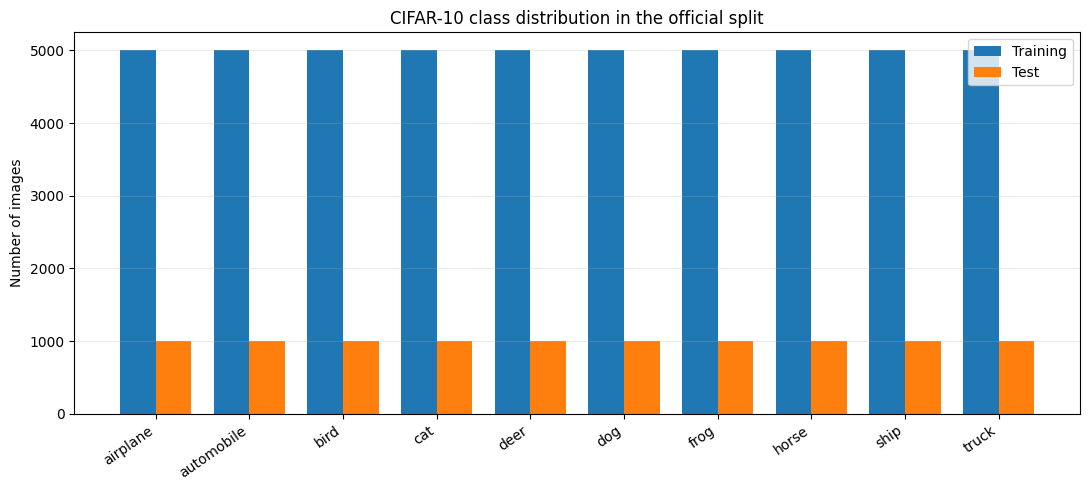

In [3]:
train_counts = np.bincount(y_train, minlength=10)
test_counts = np.bincount(y_test, minlength=10)

class_distribution = pd.DataFrame({
    "class_id": np.arange(10),
    "class_name": class_names,
    "training_count": train_counts,
    "training_percent": 100 * train_counts / len(y_train),
    "test_count": test_counts,
    "test_percent": 100 * test_counts / len(y_test),
})
display(class_distribution)

positions = np.arange(len(class_names))
width = 0.38
figure, axis = plt.subplots(figsize=(11, 5))
axis.bar(positions - width / 2, train_counts, width, label="Training")
axis.bar(positions + width / 2, test_counts, width, label="Test")
axis.set_xticks(positions, class_names, rotation=35, ha="right")
axis.set_ylabel("Number of images")
axis.set_title("CIFAR-10 class distribution in the official split")
axis.legend()
axis.grid(axis="y", alpha=0.25)
figure.tight_layout()
plt.show()


**Distribution finding.** Every class contributes exactly `10%` of both official partitions. Overall metrics are therefore not being improved by an over-represented class, and a balanced development split can be formed without resampling.

## 2.4 Image and Pixel Investigation

I use a seeded sample rather than selecting visually favourable records. Five images from every class reveal the task's natural variation and the amount of detail available at `32 x 32` resolution.

Pixel statistics are inspected by channel because an incorrect range or colour conversion would affect the VAE reconstruction scale, GAN output activation and FID preprocessing later.

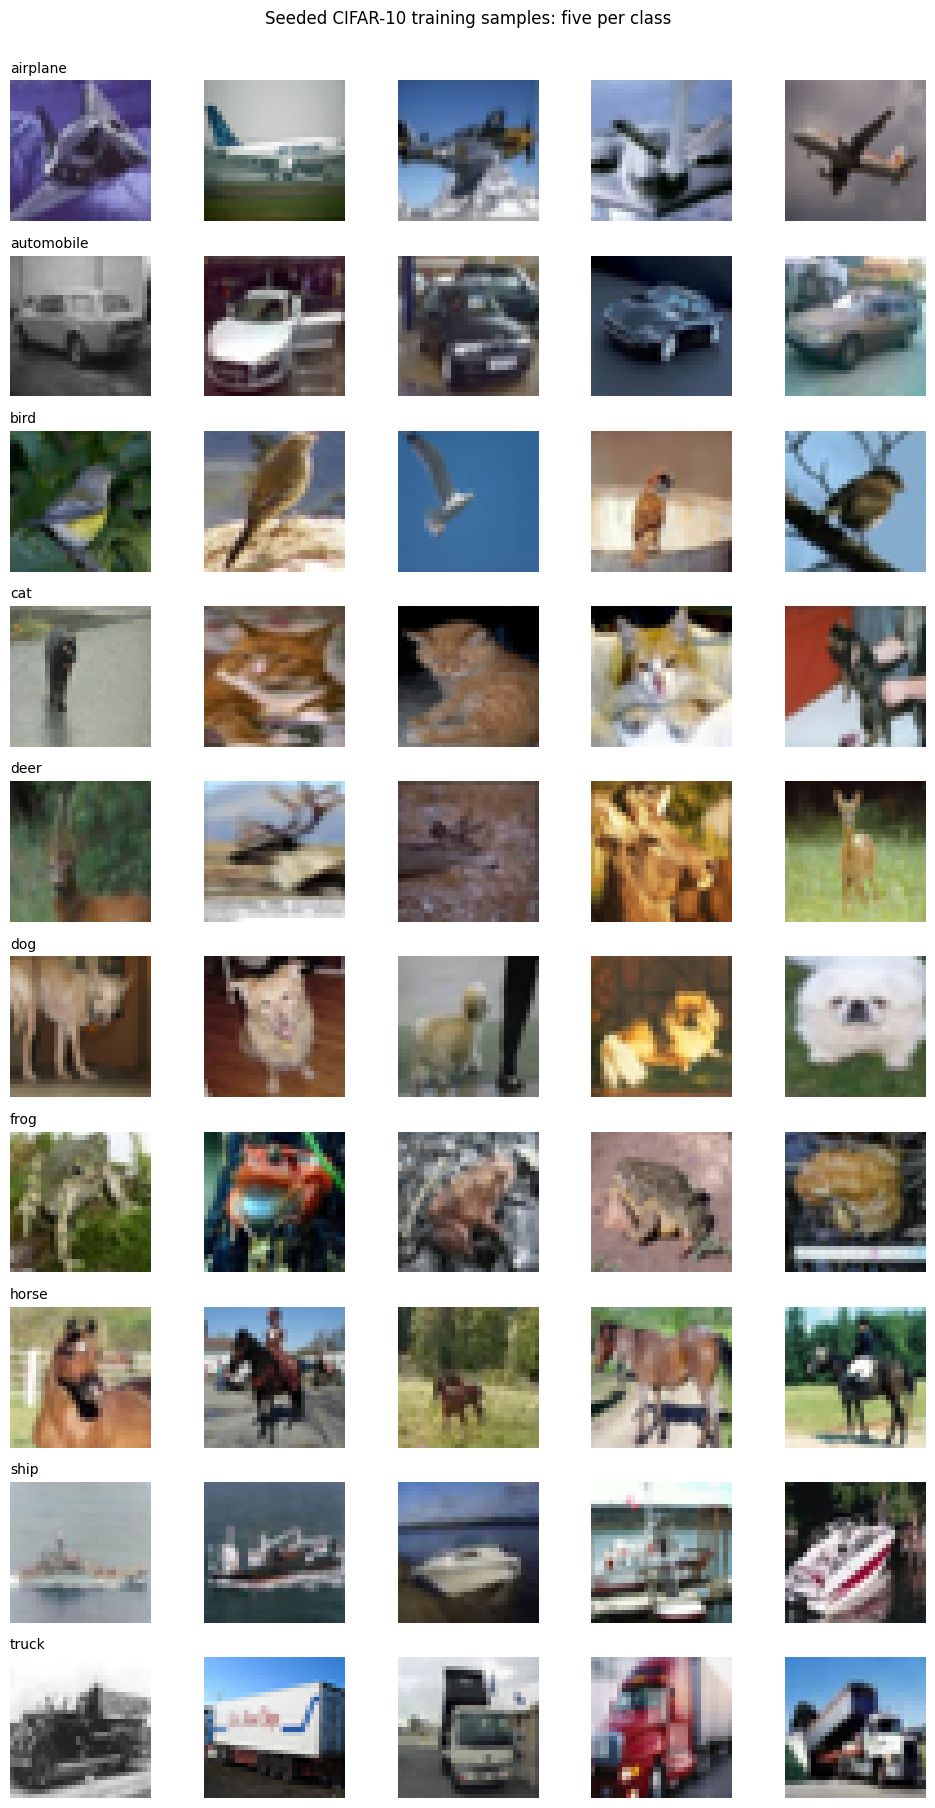

In [4]:
sample_rng = np.random.default_rng(SEED)
figure, axes = plt.subplots(10, 5, figsize=(10, 18))

for class_id, class_name in enumerate(class_names):
    class_indices = np.flatnonzero(y_train == class_id)
    selected_indices = sample_rng.choice(class_indices, size=5, replace=False)
    for column, image_index in enumerate(selected_indices):
        axis = axes[class_id, column]
        axis.imshow(x_train[image_index])
        axis.axis("off")
        if column == 0:
            axis.set_title(class_name, loc="left", fontsize=10)

figure.suptitle("Seeded CIFAR-10 training samples: five per class", y=1.002)
figure.tight_layout()
plt.show()


      split channel  minimum  maximum     mean  standard_deviation
0  Training     Red        0      255  125.307              62.993
1  Training   Green        0      255  122.950              62.089
2  Training    Blue        0      255  113.865              66.705
3      Test     Red        0      255  126.025              62.896
4      Test   Green        0      255  123.709              61.938
5      Test    Blue        0      255  114.854              66.706

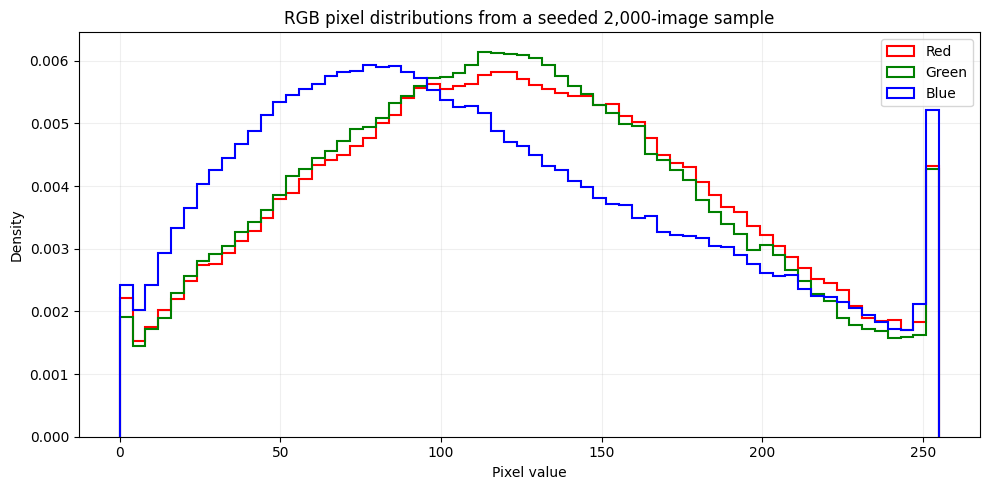

In [5]:
channel_names = ["Red", "Green", "Blue"]
pixel_records = []

for split_name, images in (("Training", x_train), ("Test", x_test)):
    for channel_id, channel_name in enumerate(channel_names):
        values = images[..., channel_id]
        pixel_records.append({
            "split": split_name,
            "channel": channel_name,
            "minimum": int(values.min()),
            "maximum": int(values.max()),
            "mean": float(values.mean()),
            "standard_deviation": float(values.std()),
        })

pixel_statistics = pd.DataFrame(pixel_records)
display(pixel_statistics.round(3))

histogram_indices = sample_rng.choice(len(x_train), size=2000, replace=False)
histogram_images = x_train[histogram_indices]

figure, axis = plt.subplots(figsize=(10, 5))
for channel_id, (channel_name, colour) in enumerate(
    zip(channel_names, ["red", "green", "blue"])
):
    axis.hist(
        histogram_images[..., channel_id].reshape(-1),
        bins=64,
        range=(0, 255),
        density=True,
        histtype="step",
        linewidth=1.5,
        color=colour,
        label=channel_name,
    )

axis.set_title("RGB pixel distributions from a seeded 2,000-image sample")
axis.set_xlabel("Pixel value")
axis.set_ylabel("Density")
axis.legend()
axis.grid(alpha=0.2)
figure.tight_layout()
plt.show()


**Image and pixel finding.** The seeded grid shows substantial variation in pose, background and scale within each class. All three channels span `0` to `255`; the lower blue-channel mean is a property of the loaded images, not a missing channel or grayscale conversion.

## 2.5 Data-Quality Audit

The audit focuses on objective faults that could justify modifying the supplied records:

- Non-finite values
- Constant images with no pixel variation
- Invalid labels
- Exact duplicate images within each split
- Exact duplicates associated with conflicting labels
- Exact image overlap between official training and test partitions

Exact hashing does not identify transformed near-duplicates. I report that limitation instead of selecting an arbitrary similarity threshold and silently changing the benchmark.

In [6]:
def hash_images(images):
    return np.array([
        hashlib.sha256(image.tobytes()).hexdigest()
        for image in images
    ])


def duplicate_statistics(images, labels):
    hashes = hash_images(images)
    counts = pd.Series(hashes).value_counts()
    label_counts = (
        pd.DataFrame({"hash": hashes, "label": labels})
        .groupby("hash")["label"]
        .nunique()
    )
    return hashes, counts, int((label_counts > 1).sum())


train_hashes, train_hash_counts, train_conflicts = duplicate_statistics(
    x_train, y_train
)
test_hashes, test_hash_counts, test_conflicts = duplicate_statistics(
    x_test, y_test
)

quality_audit = pd.DataFrame({
    "check": [
        "Non-finite training values",
        "Non-finite test values",
        "Constant training images",
        "Constant test images",
        "Invalid training labels",
        "Invalid test labels",
        "Exact duplicate groups within training",
        "Additional training images in duplicate groups",
        "Exact duplicate groups within test",
        "Additional test images in duplicate groups",
        "Training duplicate groups with conflicting labels",
        "Test duplicate groups with conflicting labels",
        "Exact image overlap between training and test",
    ],
    "count": [
        int(np.size(x_train) - np.isfinite(x_train).sum()),
        int(np.size(x_test) - np.isfinite(x_test).sum()),
        int(np.sum(np.ptp(x_train, axis=(1, 2, 3)) == 0)),
        int(np.sum(np.ptp(x_test, axis=(1, 2, 3)) == 0)),
        int(np.sum(~np.isin(y_train, np.arange(10)))),
        int(np.sum(~np.isin(y_test, np.arange(10)))),
        int((train_hash_counts > 1).sum()),
        int((train_hash_counts[train_hash_counts > 1] - 1).sum()),
        int((test_hash_counts > 1).sum()),
        int((test_hash_counts[test_hash_counts > 1] - 1).sum()),
        train_conflicts,
        test_conflicts,
        int(len(set(train_hashes).intersection(test_hashes))),
    ],
})
quality_audit


                                                check  count
0                          Non-finite training values      0
1                              Non-finite test values      0
2                            Constant training images      0
3                                Constant test images      0
4                             Invalid training labels      0
5                                 Invalid test labels      0
6              Exact duplicate groups within training      0
7      Additional training images in duplicate groups      0
8                  Exact duplicate groups within test      0
9          Additional test images in duplicate groups      0
10  Training duplicate groups with conflicting labels      0
11      Test duplicate groups with conflicting labels      0
12      Exact image overlap between training and test      0

## 2.6 Cleaning Decision

### What I found

- The official split contains 50,000 training images and 10,000 test images, with 5,000 and 1,000 examples per class respectively.
- Every image has the expected `32 x 32 x 3` shape and every label is an integer from 0 to 9.
- The audit found **0** non-finite values, constant images or invalid labels in either split.
- The hash audit found **0** byte-identical duplicate groups within either split, **0** conflicting-label duplicate groups and **0** exact image overlaps between training and test.

### Decision

- I **do not remove, replace or relabel any record**. There is no observed defect that justifies changing the supplied data.
- I preserve every official record. The official training partition is divided into model-training and validation subsets; the official test partition remains outside model development.
- Scaling the pixels for the VAE and GAN is still required, but this is preprocessing rather than cleaning because it changes representation rather than record membership.

### Boundary of this conclusion

- A cryptographic hash detects exact pixel equality only. It does not detect near-duplicates produced by crops, compression or small pixel changes.
- The audit also cannot prove that every semantic label is correct. Removing suspected records would require a defensible similarity threshold and manual verification, and would create a modified dataset that is harder to compare with the original task.
- I preserve the assigned dataset and record these two issues as limitations instead of making speculative corrections.


# 3. Data Preparation

## 3.1 Development Split and Transformation Decisions

| Decision | Reason | Alternative considered |
|---|---|---|
| Stratified 45,000/5,000 split within the official training partition | Provides balanced development evidence while reserving the official test set for one final evaluation | Reusing the test split during model selection would weaken the final claim |
| Retain RGB | Colour is part of CIFAR-10 and may distinguish objects and backgrounds | Grayscale discards task information |
| Preserve integer labels | Required for stratification, class analysis and conditional generation | One-hot conversion occurs only where a model requires it |
| VAE scale `[0, 1]` | Matches the sigmoid decoder and reconstruction target | Tanh would require a different decoder assumption |
| GAN scale `[-1, 1]` | Matches the tanh generator output | `[0, 1]` would mismatch the generator range |
| No initial augmentation | Keeps both baselines tied to the supplied image distribution | Augmentation remains a separate intervention only if later evidence supports it |
| No handcrafted features | The convolutional networks learn spatial representations directly from pixels | Edges, PCA or histograms would change the generation problem |

Normalisation changes numerical scale rather than record membership or semantic content, so I treat it as preprocessing rather than cleaning or feature engineering.

## 3.2 Stratified Split and Model-Specific Normalisation

I split before converting labels or pixels. The same 45,000 records train every model and the same 5,000 records form every development reference. The VAE and GAN then receive ranges matched to their output activations.

In [7]:
from sklearn.model_selection import train_test_split

x_model_train, x_validation, y_model_train, y_validation = train_test_split(
    x_train,
    y_train,
    test_size=5000,
    random_state=SEED,
    shuffle=True,
    stratify=y_train,
)

x_train_vae = x_model_train.astype("float32") / 255.0
x_validation_vae = x_validation.astype("float32") / 255.0
x_train_gan = x_model_train.astype("float32") / 127.5 - 1.0
y_model_train = y_model_train.astype("int32")
y_validation = y_validation.astype("int32")

assert x_train_vae.shape == (45000, 32, 32, 3)
assert x_validation_vae.shape == (5000, 32, 32, 3)
assert np.array_equal(
    np.bincount(y_model_train, minlength=10), np.full(10, 4500)
)
assert np.array_equal(
    np.bincount(y_validation, minlength=10), np.full(10, 500)
)
assert x_train_vae.dtype == np.float32
assert x_train_gan.dtype == np.float32
assert 0.0 <= x_train_vae.min() <= x_train_vae.max() <= 1.0
assert -1.0 <= x_train_gan.min() <= x_train_gan.max() <= 1.0

scale_equivalence_error = np.max(
    np.abs((x_train_gan[:1000] + 1.0) / 2.0 - x_train_vae[:1000])
)

split_summary = pd.DataFrame({
    "partition": ["Model training", "Validation", "Official test"],
    "records": [len(x_model_train), len(x_validation), len(x_test)],
    "records_per_class": [4500, 500, 1000],
    "used_for": [
        "Optimisation only",
        "Development evaluation and model selection",
        "Integrity audit; final frozen-model evaluation",
    ],
})
preparation_summary = pd.DataFrame({
    "representation": ["Original", "VAE", "GAN"],
    "dtype": [
        str(x_model_train.dtype),
        str(x_train_vae.dtype),
        str(x_train_gan.dtype),
    ],
    "minimum": [
        float(x_model_train.min()),
        float(x_train_vae.min()),
        float(x_train_gan.min()),
    ],
    "maximum": [
        float(x_model_train.max()),
        float(x_train_vae.max()),
        float(x_train_gan.max()),
    ],
    "intended_output": [
        "Saved/displayed images",
        "Sigmoid decoder",
        "Tanh generator",
    ],
})

display(split_summary)
display(preparation_summary)
print(
    "Maximum VAE/GAN scale-equivalence error: "
    f"{scale_equivalence_error:.10f}"
)


        partition  records  records_per_class  \
0  Model training    45000               4500   
1      Validation     5000                500   
2   Official test    10000               1000   

                                     used_for  
0                           Optimisation only  
1  Development evaluation and model selection  
2  Integrity audit; final frozen-model evaluation  

  representation    dtype  minimum  maximum         intended_output
0       Original    uint8      0.0    255.0  Saved/displayed images
1            VAE  float32      0.0      1.0         Sigmoid decoder
2            GAN  float32     -1.0      1.0          Tanh generator

Maximum VAE/GAN scale-equivalence error: 0.0000000149


**Preparation finding.** The executed split contains `4,500` training and `500` validation records per class. The two model representations match exactly apart from floating-point rounding (`1.49 x 10^-8` maximum error), so later differences cannot be attributed to different underlying images.

## 3.3 Feature-Engineering Decision

Pixel normalisation is required preprocessing rather than feature engineering. I use `[0, 1]` for the sigmoid VAE decoder and `[-1, 1]` for the tanh GAN generator. I do not additionally apply channel-wise standardisation because its z-score range would no longer match either output activation; using both transformations would add an unnecessary inverse-scaling requirement.

| Option considered | Decision for the baseline | Reason |
|---|---|---|
| Handcrafted edges, textures, histograms or PCA | Reject | Convolutional layers should learn spatial features from the original pixels; these representations would change the generation target |
| Grayscale conversion | Reject | Colour is useful CIFAR-10 information and the required outputs are colour images |
| Random horizontal flips | Defer | This is the safest augmentation candidate, but adding it before the baseline would hide whether it produced the difference |
| Random crop and resize | Reject initially | At `32 x 32`, cropping can remove object evidence and resizing can introduce interpolation artefacts; padded cropping could be reconsidered separately |
| Colour jitter | Reject initially | Brightness and contrast shifts change the target colour distribution and may weaken class cues |
| Class labels as model inputs | Defer | Labels are retained for balanced evaluation and will be inputs only if conditional generation is tested separately |

Therefore, no additional features or augmented views are used for the first baselines. If the GAN later shows discriminator overfitting, I may test one augmentation policy while holding the architecture and optimiser fixed. Any GAN augmentation must be applied consistently to real and generated discriminator inputs, while evaluation and exported images remain unaugmented.

## 3.4 Data Preparation Summary

- The model-training and validation partitions contain exactly 4,500 and 500 records per class.
- VAE inputs are `float32` in `[0, 1]`; GAN inputs are `float32` in `[-1, 1]`.
- The two scaled representations differ only by the stated linear transformation.
- The official 10,000-image test partition has not been transformed for, or used by, model development.
- No augmentation, filtering or feature extraction has changed the image content.

# 4. VAE Baseline

The first working baseline is a convolutional VAE. I start with it because its single reconstruction-and-regularisation objective makes the data flow and latent representation easier to verify before introducing the two-network optimisation problem of a GAN.

I use enough convolutional capacity for a credible comparison, while retaining the standard VAE objective and a training budget fixed before generated images are inspected.

## 4.1 Baseline Controls and Training Budget

| Decision | Setting | Reason |
|---|---:|---|
| Training records | Stratified 45,000-image model-training set | Validation and test images do not enter optimisation |
| Input representation | RGB in `[0, 1]` | Matches binary cross-entropy and the sigmoid decoder |
| Latent dimension | 128 | Provides a shared, moderate latent capacity for the VAE and GAN |
| Batch size | 128 | Balances gradient averaging, update frequency and GPU memory |
| Complete epochs | 30 | Gives 10,560 updates and six post-start checkpoints, plus epoch 0, without selecting duration from the final images |
| Sample interval | Every 5 epochs, plus epoch 0 | Tracks learning with fixed latent vectors while keeping the evidence readable |
| Optimiser | Adam, learning rate `0.001` | Standard untuned VAE starting point |
| KL weight | `1.0` | Preserves the standard VAE objective before any beta intervention |
| Model selection | Final epoch | Avoids selecting a favourable small image grid |

One epoch is one pass over all 45,000 model-training images. I report both epochs and optimiser updates so the exposure is explicit.

In [8]:
IMAGE_SHAPE = (32, 32, 3)
LATENT_DIM = 128
BATCH_SIZE = 128
VAE_EPOCHS = 30
GAN_EPOCHS = 30
SAMPLE_INTERVAL = 5
FIXED_SAMPLE_COUNT = 25
STEPS_PER_EPOCH = int(np.ceil(len(x_train_vae) / BATCH_SIZE))

BASELINE_OUTPUT_DIR = Path("part_a_baseline_outputs")
VAE_SAMPLE_DIR = BASELINE_OUTPUT_DIR / "vae_samples"
GAN_SAMPLE_DIR = BASELINE_OUTPUT_DIR / "gan_samples"
WEIGHT_DIR = BASELINE_OUTPUT_DIR / "weights"
TABLE_DIR = BASELINE_OUTPUT_DIR / "tables"

for directory in (VAE_SAMPLE_DIR, GAN_SAMPLE_DIR, WEIGHT_DIR, TABLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

BASELINE_FIXED_NOISE = np.random.default_rng(SEED + 100).normal(
    size=(FIXED_SAMPLE_COUNT, LATENT_DIM)
).astype("float32")


def checkpoint_epochs(total_epochs):
    return [0, *range(SAMPLE_INTERVAL, total_epochs + 1, SAMPLE_INTERVAL)]


def images_for_display(images, output_range):
    images = np.asarray(images, dtype="float32")
    if output_range == "tanh":
        images = (images + 1.0) / 2.0
    return np.clip(images, 0.0, 1.0)


def make_training_dataset(images, labels=None, seed=SEED):
    records = images if labels is None else (images, labels)
    with tf.device("/CPU:0"):
        dataset = tf.data.Dataset.from_tensor_slices(records)
    dataset = dataset.shuffle(
        len(images),
        seed=seed,
        reshuffle_each_iteration=True,
    )
    dataset = dataset.batch(BATCH_SIZE, drop_remainder=False)
    options = tf.data.Options()
    options.experimental_deterministic = True
    return dataset.with_options(options).prefetch(tf.data.AUTOTUNE)


def history_frame(history, epochs, path):
    table = pd.DataFrame(history.history)
    table.index = np.arange(1, epochs + 1)
    table.index.name = "epoch"
    assert len(table) == epochs
    assert np.isfinite(table.to_numpy()).all()
    table.to_csv(path)
    return table


In [9]:
def save_fixed_grid(
    generator,
    model_inputs,
    output_range,
    rows,
    columns,
    path,
    title,
):
    sample_count = len(
        model_inputs[0] if isinstance(model_inputs, list) else model_inputs
    )
    images = generator.predict(
        model_inputs,
        batch_size=sample_count,
        verbose=0,
    )
    images = images_for_display(images, output_range)
    assert len(images) == rows * columns

    figure, axes = plt.subplots(rows, columns, figsize=(1.25 * columns, 1.25 * rows))
    for index, axis in enumerate(np.asarray(axes).flat):
        axis.imshow(images[index], interpolation="nearest")
        axis.axis("off")
        if columns == len(class_names) and index < columns:
            axis.set_title(class_names[index], fontsize=8)
    figure.suptitle(title)
    figure.tight_layout()
    figure.savefig(path, dpi=140, bbox_inches="tight")
    plt.close(figure)


class FixedSampleCheckpoint(keras.callbacks.Callback):
    def __init__(
        self,
        generator,
        model_inputs,
        sample_dir,
        weight_dir,
        prefix,
        output_range,
        rows,
        columns,
        title,
    ):
        super().__init__()
        self.generator = generator
        self.model_inputs = model_inputs
        self.sample_dir = Path(sample_dir)
        self.weight_dir = Path(weight_dir)
        self.prefix = prefix
        self.output_range = output_range
        self.rows = rows
        self.columns = columns
        self.title = title

    def save_checkpoint(self, epoch_number):
        save_fixed_grid(
            generator=self.generator,
            model_inputs=self.model_inputs,
            output_range=self.output_range,
            rows=self.rows,
            columns=self.columns,
            path=self.sample_dir / f"{self.prefix}_epoch_{epoch_number:03d}.png",
            title=f"{self.title}, epoch {epoch_number}",
        )
        self.generator.save_weights(
            self.weight_dir / f"{self.prefix}_epoch_{epoch_number:03d}.weights.h5"
        )

    def on_train_begin(self, logs=None):
        self.save_checkpoint(0)

    def on_epoch_end(self, epoch, logs=None):
        epoch_number = epoch + 1
        if epoch_number % SAMPLE_INTERVAL == 0:
            self.save_checkpoint(epoch_number)


def show_saved_progression(sample_dir, prefix, epochs, title):
    figure, axes = plt.subplots(1, len(epochs), figsize=(4 * len(epochs), 4))
    for axis, epoch_number in zip(np.asarray(axes).flat, epochs):
        path = Path(sample_dir) / f"{prefix}_epoch_{epoch_number:03d}.png"
        axis.imshow(plt.imread(path))
        axis.set_title(f"Epoch {epoch_number}")
        axis.axis("off")
    figure.suptitle(title)
    figure.tight_layout()
    plt.show()


def plot_training_diagnostics(history, metrics, title):
    columns = 2
    rows = int(np.ceil(len(metrics) / columns))
    figure, axes = plt.subplots(
        rows,
        columns,
        figsize=(10, 3.5 * rows),
        squeeze=False,
    )
    for axis, (column, label) in zip(axes.flat, metrics):
        assert column in history.columns
        axis.plot(history.index, history[column])
        axis.set_title(label)
        axis.set_xlabel("Epoch")
        axis.grid(alpha=0.25)
    for axis in axes.flat[len(metrics):]:
        axis.axis("off")
    figure.suptitle(title)
    figure.tight_layout()
    plt.show()


SOURCE_DIAGNOSTICS = [
    ("discriminator_loss", "Discriminator loss"),
    ("generator_loss", "Generator loss"),
    ("real_accuracy", "Real-source accuracy"),
    ("fake_accuracy", "Generated-source accuracy"),
]
AUXILIARY_DIAGNOSTICS = [
    ("discriminator_loss", "Discriminator loss"),
    ("generator_loss", "Generator loss"),
    ("real_class_accuracy", "Real class accuracy"),
    ("fake_class_accuracy", "Generated class accuracy"),
]


print("Complete-dataset steps per epoch:", STEPS_PER_EPOCH)
print("Optimiser updates per 30-epoch baseline:", STEPS_PER_EPOCH * 30)
print("Fixed sample epochs:", checkpoint_epochs(30))


Complete-dataset steps per epoch: 352
Optimiser updates per 30-epoch baseline: 10560
Fixed sample epochs: [0, 5, 10, 15, 20, 25, 30]


## 4.2 VAE Architecture

### Encoder

- Three stride-2 convolutional blocks reduce the spatial resolution exactly from `32 -> 16 -> 8 -> 4`.
- Filters increase from 32 to 64 to 128 as spatial resolution falls, allowing broader feature combinations at the compressed stage.
- A 256-unit dense layer feeds separate `z_mean` and `z_log_var` vectors.
- The reparameterisation step keeps sampling differentiable during training.

### Decoder

- A dense projection reconstructs a `4 x 4 x 128` feature map from the latent vector.
- Three transpose-convolution blocks restore `4 -> 8 -> 16 -> 32` pixels symmetrically.
- The final three-channel sigmoid layer matches the `[0, 1]` RGB target.

### Objective

- Pixel-wise binary cross-entropy supplies the reconstruction term used by the baseline framework.
- KL divergence regularises the approximate posterior towards `N(0, I)`, allowing direct prior sampling.
- Reconstruction and KL losses are retained separately because the total alone can conceal posterior collapse or excessive regularisation.

Binary cross-entropy is a simplifying pixel-distribution assumption for natural images and may encourage smooth outputs. I retain it here because changing the loss would already be a VAE improvement rather than a neutral baseline choice.

**Source:** [Kingma and Welling, Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114).

In [10]:
class Sampling(keras.layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


def build_vae_encoder(latent_dim=LATENT_DIM):
    inputs = keras.Input(shape=IMAGE_SHAPE, name="encoder_input")
    x = keras.layers.Conv2D(
        32, 3, strides=2, padding="same", activation="relu"
    )(inputs)
    x = keras.layers.Conv2D(
        64, 3, strides=2, padding="same", activation="relu"
    )(x)
    x = keras.layers.Conv2D(
        128, 3, strides=2, padding="same", activation="relu"
    )(x)
    x = keras.layers.Flatten()(x)
    x = keras.layers.Dense(256, activation="relu")(x)
    z_mean = keras.layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = keras.layers.Dense(latent_dim, name="z_log_var")(x)
    z = Sampling(name="z")([z_mean, z_log_var])
    return keras.Model(
        inputs,
        [z_mean, z_log_var, z],
        name="vae_encoder",
    )


In [11]:
def build_vae_decoder(latent_dim=LATENT_DIM):
    inputs = keras.Input(shape=(latent_dim,), name="decoder_input")
    x = keras.layers.Dense(4 * 4 * 128, activation="relu")(inputs)
    x = keras.layers.Reshape((4, 4, 128))(x)
    x = keras.layers.Conv2DTranspose(
        128, 3, strides=2, padding="same", activation="relu"
    )(x)
    x = keras.layers.Conv2DTranspose(
        64, 3, strides=2, padding="same", activation="relu"
    )(x)
    x = keras.layers.Conv2DTranspose(
        32, 3, strides=2, padding="same", activation="relu"
    )(x)
    outputs = keras.layers.Conv2D(
        3,
        3,
        padding="same",
        activation="sigmoid",
        name="decoder_output",
    )(x)
    return keras.Model(inputs, outputs, name="vae_decoder")


In [12]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name="loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def call(self, inputs, training=False):
        _, _, z = self.encoder(inputs, training=training)
        return self.decoder(z, training=training)

    def compute_losses(self, images, training=False):
        z_mean, z_log_var, z = self.encoder(images, training=training)
        reconstructions = self.decoder(z, training=training)
        reconstruction_loss = tf.reduce_mean(
            tf.reduce_sum(
                keras.losses.binary_crossentropy(images, reconstructions),
                axis=(1, 2),
            )
        )
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(
                1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
                axis=1,
            )
        )
        return (
            reconstruction_loss + kl_loss,
            reconstruction_loss,
            kl_loss,
        )

    def update_trackers(self, total_loss, reconstruction_loss, kl_loss):
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {metric.name: metric.result() for metric in self.metrics}

    def train_step(self, data):
        images = data[0] if isinstance(data, (tuple, list)) else data
        with tf.GradientTape() as tape:
            losses = self.compute_losses(images, training=True)
        gradients = tape.gradient(losses[0], self.trainable_weights)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_weights))
        return self.update_trackers(*losses)

    def test_step(self, data):
        images = data[0] if isinstance(data, (tuple, list)) else data
        losses = self.compute_losses(images, training=False)
        return self.update_trackers(*losses)


## 4.3 Implementation Check

Before optimisation, I check the encoder, latent and decoder shapes, output range, finite values and parameter count. A failure here would invalidate the training results, so the model is not trained until these checks pass.

In [13]:
keras.utils.set_random_seed(SEED)
vae_encoder = build_vae_encoder()
vae_decoder = build_vae_decoder()
baseline_vae = VAE(vae_encoder, vae_decoder, name="baseline_vae")
baseline_vae.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001)
)

vae_probe = x_train_vae[:4]
probe_mean, probe_log_var, probe_z = vae_encoder(
    vae_probe, training=False
)
probe_reconstruction = vae_decoder(probe_z, training=False)

assert probe_mean.shape == (4, LATENT_DIM)
assert probe_log_var.shape == (4, LATENT_DIM)
assert probe_z.shape == (4, LATENT_DIM)
assert probe_reconstruction.shape == (4, *IMAGE_SHAPE)
assert np.isfinite(probe_reconstruction.numpy()).all()
assert 0.0 <= float(tf.reduce_min(probe_reconstruction))
assert float(tf.reduce_max(probe_reconstruction)) <= 1.0

VAE_PARAMETER_COUNT = vae_encoder.count_params() + vae_decoder.count_params()
print("VAE encoder parameters:", f"{vae_encoder.count_params():,}")
print("VAE decoder parameters:", f"{vae_decoder.count_params():,}")
print("Total VAE parameters:", f"{VAE_PARAMETER_COUNT:,}")
print(
    "Initial output range:",
    float(tf.reduce_min(probe_reconstruction)),
    "to",
    float(tf.reduce_max(probe_reconstruction)),
)


VAE encoder parameters: 683,584
VAE decoder parameters: 504,899
Total VAE parameters: 1,188,483
Initial output range: 0.4819605350494385 to 0.5154504179954529


### Check result

The VAE shape, range, finite-value and parameter checks passed. No configuration change was needed.

## 4.4 VAE Training

The VAE trains for the fixed 30 complete epochs. Keras reports one line per epoch, and the full history is also saved to CSV for the plots below. The same 25 prior samples are saved before training and every five epochs, so changes in the grids come from the weights rather than a different random sample.


In [14]:
vae_callback = FixedSampleCheckpoint(
    generator=vae_decoder,
    model_inputs=BASELINE_FIXED_NOISE,
    sample_dir=VAE_SAMPLE_DIR,
    weight_dir=WEIGHT_DIR,
    prefix="vae_baseline",
    output_range="sigmoid",
    rows=5,
    columns=5,
    title="VAE fixed prior samples",
)

training_start = time.perf_counter()
vae_history_object = baseline_vae.fit(
    x_train_vae,
    epochs=VAE_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    callbacks=[vae_callback],
    verbose=2,
)
VAE_TRAINING_SECONDS = time.perf_counter() - training_start

vae_history_df = history_frame(
    vae_history_object,
    VAE_EPOCHS,
    TABLE_DIR / "vae_baseline_history.csv",
)
VAE_FINAL_WEIGHT_PATH = (
    WEIGHT_DIR / "vae_baseline_decoder_final.weights.h5"
)
vae_decoder.save_weights(VAE_FINAL_WEIGHT_PATH)

print(f"Training complete: {VAE_EPOCHS} complete epochs")
print("Fixed-sample checkpoints:", checkpoint_epochs(VAE_EPOCHS))
print(f"Training time: {VAE_TRAINING_SECONDS / 60:.2f} minutes")
print("Final decoder weights:", VAE_FINAL_WEIGHT_PATH)


Epoch 1/30


352/352 - 7s - loss: 674.8196 - reconstruction_loss: 668.4403 - kl_loss: 6.3794 - 7s/epoch - 19ms/step


Epoch 2/30


352/352 - 9s - loss: 646.7844 - reconstruction_loss: 635.4301 - kl_loss: 11.3541 - 9s/epoch - 26ms/step


Epoch 3/30


352/352 - 7s - loss: 638.7236 - reconstruction_loss: 626.5867 - kl_loss: 12.1370 - 7s/epoch - 20ms/step


... (51 outputs left out)

352/352 - 9s - loss: 625.9137 - reconstruction_loss: 608.8553 - kl_loss: 17.0585 - 9s/epoch - 26ms/step


Epoch 30/30


352/352 - 16s - loss: 625.8422 - reconstruction_loss: 608.7689 - kl_loss: 17.0731 - 16s/epoch - 46ms/step


Training complete: 30 complete epochs
Fixed-sample checkpoints: [0, 5, 10, 15, 20, 25, 30]
Training time: 3.47 minutes
Final decoder weights: part_a_baseline_outputs\weights\vae_baseline_decoder_final.weights.h5


## 4.5 VAE Baseline Evidence

I separate three questions:

1. Do reconstruction and KL losses remain finite and improve?
2. Does the encoder-decoder retain broad structure on balanced validation examples?
3. Do fixed direct samples from `N(0, I)` become varied and recognisable?

Reconstructions use `z_mean` to remove sampling noise from that comparison. Prior grids remain unfiltered. Seven grids were saved at epochs `0, 5, 10, 15, 20, 25, 30`; the figure displays `0, 10, 20, 30` to show the trend without repeating every saved file.

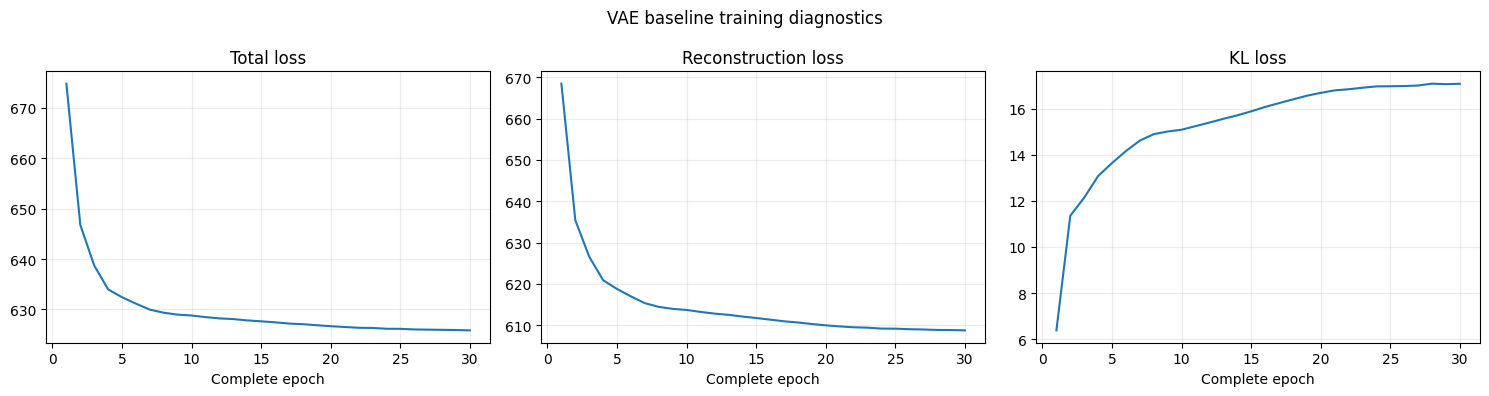

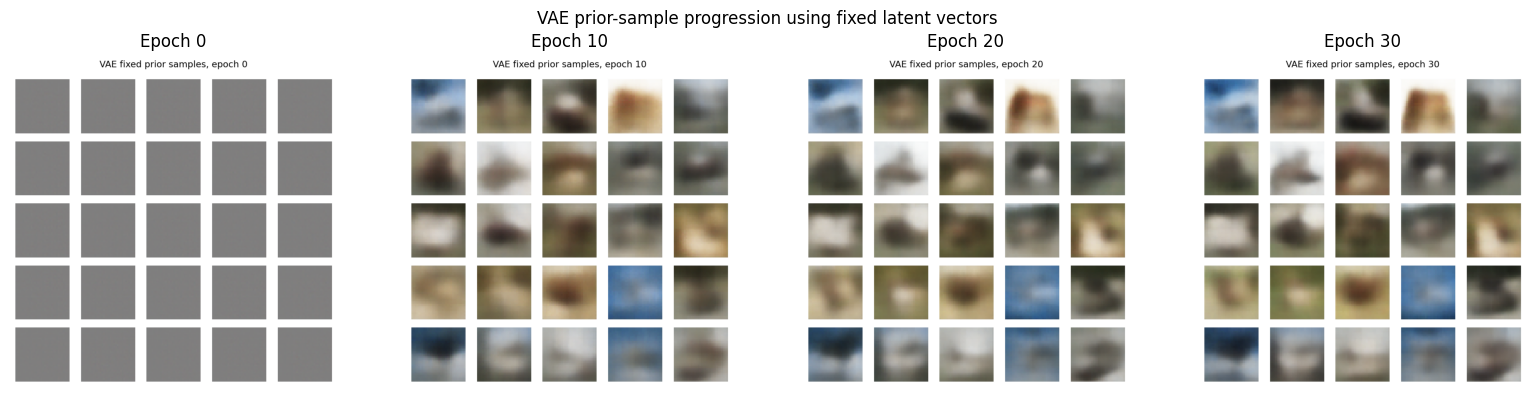

In [15]:
vae_validation_metrics = baseline_vae.evaluate(
    x_validation_vae,
    batch_size=BATCH_SIZE,
    return_dict=True,
    verbose=0,
)

figure, axes = plt.subplots(1, 3, figsize=(15, 4))
metrics = [
    ("loss", "Total loss"),
    ("reconstruction_loss", "Reconstruction loss"),
    ("kl_loss", "KL loss"),
]
for axis, (metric, label) in zip(axes, metrics):
    axis.plot(vae_history_df.index, vae_history_df[metric])
    axis.set_title(label)
    axis.set_xlabel("Complete epoch")
    axis.grid(alpha=0.25)
figure.suptitle("VAE baseline training diagnostics")
figure.tight_layout()
plt.show()

show_saved_progression(
    VAE_SAMPLE_DIR,
    "vae_baseline",
    [0, 10, 20, 30],
    "VAE prior-sample progression using fixed latent vectors",
)


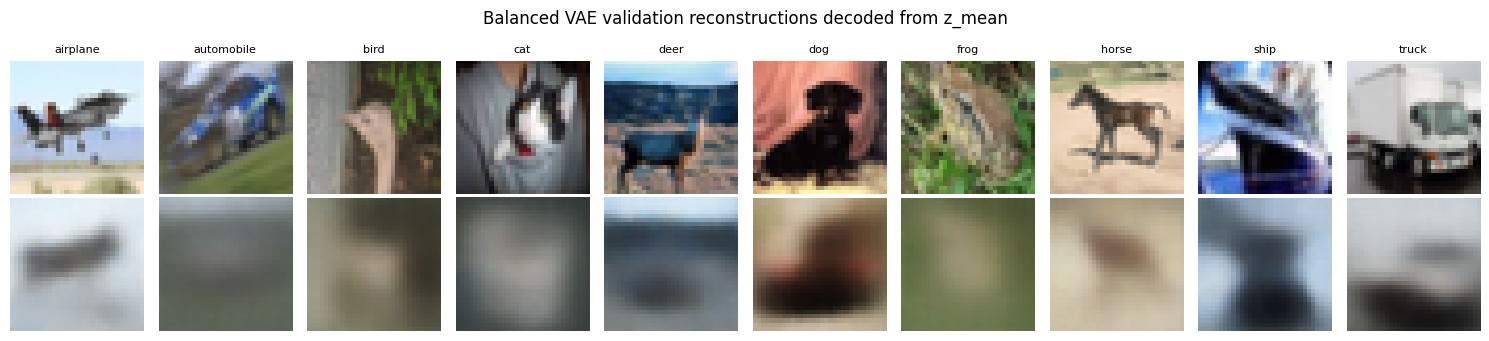

In [16]:
reconstruction_indices = np.array([
    np.flatnonzero(y_validation == class_id)[0]
    for class_id in range(len(class_names))
])
reconstruction_images = x_validation_vae[reconstruction_indices]
reconstruction_means, _, _ = vae_encoder.predict(
    reconstruction_images,
    batch_size=10,
    verbose=0,
)
reconstructed_images = vae_decoder.predict(
    reconstruction_means,
    batch_size=10,
    verbose=0,
)

figure, axes = plt.subplots(2, 10, figsize=(15, 3.5))
for column, class_name in enumerate(class_names):
    axes[0, column].imshow(
        reconstruction_images[column], interpolation="nearest"
    )
    axes[1, column].imshow(
        np.clip(reconstructed_images[column], 0, 1),
        interpolation="nearest",
    )
    axes[0, column].set_title(class_name, fontsize=8)
    axes[0, column].axis("off")
    axes[1, column].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruction")
figure.suptitle("Balanced VAE validation reconstructions decoded from z_mean")
figure.tight_layout()
plt.show()


In [17]:
vae_baseline_summary = pd.DataFrame([{
    "epochs": VAE_EPOCHS,
    "optimizer_updates": VAE_EPOCHS * STEPS_PER_EPOCH,
    "parameters": VAE_PARAMETER_COUNT,
    "training_minutes": VAE_TRAINING_SECONDS / 60,
    "validation_total_loss": vae_validation_metrics["loss"],
    "validation_reconstruction_loss": (
        vae_validation_metrics["reconstruction_loss"]
    ),
    "validation_kl_loss": vae_validation_metrics["kl_loss"],
}])
vae_baseline_summary.to_csv(
    TABLE_DIR / "vae_baseline_summary.csv",
    index=False,
)
display(vae_baseline_summary.round(6))


   epochs  optimizer_updates  parameters  training_minutes  \
0      30              10560     1188483          3.472365   

   validation_total_loss  validation_reconstruction_loss  validation_kl_loss  
0              625.61792                      608.376099           17.241934  

## 4.6 VAE Baseline Evaluation

### Findings

- Total training loss fell from `674.82` to `625.84`; the final validation loss was `625.62`.
- Validation reconstruction loss (`608.38`) remained much larger than KL loss (`17.24`). The KL term was active rather than collapsing to zero, but most of the objective was still spent on pixel reconstruction.
- Reconstructions retained broad colour and layout but smoothed fine edges. Samples drawn directly from the prior were varied, although few had clear class-specific structure.

### Decision

I keep the VAE as a valid baseline, but its falling loss is not enough to answer the generation task. The next comparison tests whether adversarial training improves the unfiltered prior samples under the same data split, latent dimension, batch size and epoch budget.


# 5. GAN Baseline

The second baseline is an unconditional convolutional GAN. It receives the same training images, latent dimension, batch size, complete epochs and fixed latent vectors as the VAE. Its adversarial objective is different, so matching these controls does not make the computation identical; runtime and optimiser updates are reported explicitly.

## 5.1 GAN Architecture and Optimisation Decisions

### Generator

- A dense projection creates a `4 x 4 x 256` feature map.
- Three stride-2 transpose convolutions restore `4 -> 8 -> 16 -> 32` pixels.
- Feature depth decreases from 256 to 128 to 64 to 32 as spatial size increases.
- Batch normalisation and LeakyReLU maintain gradient flow in the hidden generator blocks.
- The final tanh layer matches training images normalised to `[-1, 1]`.

### Discriminator

- Three stride-2 convolutions reduce `32 -> 16 -> 8 -> 4` while increasing filters from 64 to 128 to 256.
- LeakyReLU avoids a zero gradient for negative activations.
- Dropout `0.3` is modest regularisation against an immediately memorising discriminator; no data augmentation is used.
- The final unit returns a logit, paired with binary cross-entropy configured with `from_logits=True`.

### Optimisation

| Decision | Setting | Reason |
|---|---:|---|
| Latent prior | `N(0, I)`, dimension 128 | Same latent input capacity as the VAE |
| Batch size | 128 | Same batch exposure as the VAE |
| Complete epochs | 30 | Same 10,560 batches as the VAE; no training-until-good stopping |
| Generator and discriminator updates | One each per batch | A simple balanced starting schedule |
| Both Adam learning rates | `0.0002` | Conservative adversarial step size established for DCGAN training |
| Adam `beta_1` | `0.5` | Reduces momentum persistence in the changing adversarial objective |
| Labels | Hard real `1`, fake `0` | Label smoothing remains available as a later controlled change |

GAN losses will be treated as stability diagnostics rather than image-quality scores. Transpose-convolution artefacts, mode collapse and discriminator overconfidence remain explicit baseline risks.

**Sources:** [Goodfellow et al. (2014), Generative Adversarial Nets](https://papers.neurips.cc/paper_files/paper/2014/hash/f033ed80deb0234979a61f95710dbe25-Abstract.html); [Radford, Metz and Chintala (2016), DCGAN](https://arxiv.org/abs/1511.06434).

In [18]:
def build_gan_generator(latent_dim=LATENT_DIM):
    model = keras.Sequential(name="gan_generator")
    model.add(keras.layers.Input(shape=(latent_dim,)))
    model.add(keras.layers.Dense(4 * 4 * 256, use_bias=False))
    model.add(keras.layers.BatchNormalization(momentum=0.8))
    model.add(keras.layers.LeakyReLU(alpha=0.2))
    model.add(keras.layers.Reshape((4, 4, 256)))

    for filters in (128, 64, 32):
        model.add(keras.layers.Conv2DTranspose(
            filters,
            4,
            strides=2,
            padding="same",
            use_bias=False,
        ))
        model.add(keras.layers.BatchNormalization(momentum=0.8))
        model.add(keras.layers.LeakyReLU(alpha=0.2))

    model.add(keras.layers.Conv2D(
        3,
        3,
        padding="same",
        activation="tanh",
    ))
    return model


def build_gan_discriminator():
    model = keras.Sequential(name="gan_discriminator")
    model.add(keras.layers.Input(shape=IMAGE_SHAPE))
    for filters in (64, 128, 256):
        model.add(keras.layers.Conv2D(
            filters,
            4,
            strides=2,
            padding="same",
        ))
        model.add(keras.layers.LeakyReLU(alpha=0.2))
        model.add(keras.layers.Dropout(0.3))
    model.add(keras.layers.Flatten())
    model.add(keras.layers.Dense(1))
    return model


In [19]:
class DCGAN(keras.Model):
    def __init__(self, generator, discriminator, latent_dim, **kwargs):
        super().__init__(**kwargs)
        self.generator = generator
        self.discriminator = discriminator
        self.latent_dim = latent_dim
        self.discriminator_loss_tracker = keras.metrics.Mean(
            name="discriminator_loss"
        )
        self.generator_loss_tracker = keras.metrics.Mean(
            name="generator_loss"
        )
        self.real_accuracy_tracker = keras.metrics.Mean(
            name="real_accuracy"
        )
        self.fake_accuracy_tracker = keras.metrics.Mean(
            name="fake_accuracy"
        )

    @property
    def metrics(self):
        return [
            self.discriminator_loss_tracker,
            self.generator_loss_tracker,
            self.real_accuracy_tracker,
            self.fake_accuracy_tracker,
        ]

    def compile(self, discriminator_optimizer, generator_optimizer, loss_fn):
        super().compile()
        self.discriminator_optimizer = discriminator_optimizer
        self.generator_optimizer = generator_optimizer
        self.loss_fn = loss_fn

    def train_step(self, real_images):
        batch_size = tf.shape(real_images)[0]
        noise = tf.random.normal((batch_size, self.latent_dim))
        generated_images = self.generator(noise, training=True)

        with tf.GradientTape() as tape:
            real_logits = self.discriminator(real_images, training=True)
            fake_logits = self.discriminator(
                tf.stop_gradient(generated_images),
                training=True,
            )
            real_loss = self.loss_fn(tf.ones_like(real_logits), real_logits)
            fake_loss = self.loss_fn(tf.zeros_like(fake_logits), fake_logits)
            discriminator_loss = 0.5 * (real_loss + fake_loss)

        gradients = tape.gradient(
            discriminator_loss,
            self.discriminator.trainable_weights,
        )
        self.discriminator_optimizer.apply_gradients(
            zip(gradients, self.discriminator.trainable_weights)
        )

        noise = tf.random.normal((batch_size, self.latent_dim))
        with tf.GradientTape() as tape:
            generated_images = self.generator(noise, training=True)
            generated_logits = self.discriminator(
                generated_images,
                training=True,
            )
            generator_loss = self.loss_fn(
                tf.ones_like(generated_logits),
                generated_logits,
            )

        gradients = tape.gradient(
            generator_loss,
            self.generator.trainable_weights,
        )
        self.generator_optimizer.apply_gradients(
            zip(gradients, self.generator.trainable_weights)
        )

        self.discriminator_loss_tracker.update_state(discriminator_loss)
        self.generator_loss_tracker.update_state(generator_loss)
        self.real_accuracy_tracker.update_state(
            tf.reduce_mean(tf.cast(real_logits >= 0.0, tf.float32))
        )
        self.fake_accuracy_tracker.update_state(
            tf.reduce_mean(tf.cast(fake_logits < 0.0, tf.float32))
        )
        return {metric.name: metric.result() for metric in self.metrics}


## 5.2 Implementation Check

Before optimisation, I verify the generator shape and tanh range, one discriminator logit per image, finite outputs, and both parameter counts. The epoch-0 fixed grid is saved before any update.

In [20]:
keras.utils.set_random_seed(SEED)
gan_generator = build_gan_generator()
gan_discriminator = build_gan_discriminator()
baseline_gan = DCGAN(
    gan_generator,
    gan_discriminator,
    latent_dim=LATENT_DIM,
    name="baseline_gan",
)
baseline_gan.compile(
    discriminator_optimizer=keras.optimizers.Adam(
        learning_rate=0.0002,
        beta_1=0.5,
    ),
    generator_optimizer=keras.optimizers.Adam(
        learning_rate=0.0002,
        beta_1=0.5,
    ),
    loss_fn=keras.losses.BinaryCrossentropy(from_logits=True),
)

gan_probe_noise = tf.convert_to_tensor(BASELINE_FIXED_NOISE[:4])
gan_probe_images = gan_generator(gan_probe_noise, training=False)
real_probe_logits = gan_discriminator(x_train_gan[:4], training=False)
fake_probe_logits = gan_discriminator(gan_probe_images, training=False)

assert gan_probe_images.shape == (4, *IMAGE_SHAPE)
assert real_probe_logits.shape == (4, 1)
assert fake_probe_logits.shape == (4, 1)
assert np.isfinite(gan_probe_images.numpy()).all()
assert -1.0 <= float(tf.reduce_min(gan_probe_images))
assert float(tf.reduce_max(gan_probe_images)) <= 1.0

GAN_GENERATOR_PARAMETER_COUNT = gan_generator.count_params()
GAN_DISCRIMINATOR_PARAMETER_COUNT = gan_discriminator.count_params()
GAN_TOTAL_PARAMETER_COUNT = (
    GAN_GENERATOR_PARAMETER_COUNT + GAN_DISCRIMINATOR_PARAMETER_COUNT
)

print("GAN generator parameters:", f"{GAN_GENERATOR_PARAMETER_COUNT:,}")
print(
    "GAN discriminator parameters:",
    f"{GAN_DISCRIMINATOR_PARAMETER_COUNT:,}",
)
print("Total GAN parameters:", f"{GAN_TOTAL_PARAMETER_COUNT:,}")
print(
    "Generator/discriminator parameter ratio:",
    f"{GAN_GENERATOR_PARAMETER_COUNT / GAN_DISCRIMINATOR_PARAMETER_COUNT:.2f}",
)
print(
    "Initial output range:",
    float(tf.reduce_min(gan_probe_images)),
    "to",
    float(tf.reduce_max(gan_probe_images)),
)


GAN generator parameters: 1,230,563
GAN discriminator parameters: 662,977
Total GAN parameters: 1,893,540
Generator/discriminator parameter ratio: 1.86
Initial output range: -0.05756032466888428 to 0.05205054208636284


### Check result

The GAN shape, range, finite-value and parameter checks passed. No configuration change was needed.

## 5.3 GAN Training

The dataset is shuffled reproducibly at the start of each complete epoch and batched without dropping the final records. Each batch performs:

1. One discriminator update using both real and generated images.
2. One generator update using a fresh latent batch and the non-saturating real target.

The baseline deliberately excludes label smoothing, alternative learning rates, augmentation, spectral normalisation and conditional labels. Adding them now would prevent their effects from being isolated later.

Fixed unfiltered grids and generator weights are saved at epoch 0 and every five complete epochs, matching the VAE schedule. Reusing the same latent vectors makes visual changes attributable to the trained weights rather than a more favourable random draw. The complete 30-row history is still retained and plotted in Section 5.4.

In [21]:
gan_dataset = make_training_dataset(x_train_gan, seed=SEED)
gan_callback = FixedSampleCheckpoint(
    generator=gan_generator,
    model_inputs=BASELINE_FIXED_NOISE,
    sample_dir=GAN_SAMPLE_DIR,
    weight_dir=WEIGHT_DIR,
    prefix="gan_baseline",
    output_range="tanh",
    rows=5,
    columns=5,
    title="GAN fixed latent samples",
)

training_start = time.perf_counter()
gan_history_object = baseline_gan.fit(
    gan_dataset,
    epochs=GAN_EPOCHS,
    callbacks=[gan_callback],
    verbose=2,
)
GAN_TRAINING_SECONDS = time.perf_counter() - training_start

gan_history_df = history_frame(
    gan_history_object,
    GAN_EPOCHS,
    TABLE_DIR / "gan_baseline_history.csv",
)
GAN_FINAL_WEIGHT_PATH = (
    WEIGHT_DIR / "gan_baseline_generator_final.weights.h5"
)
gan_generator.save_weights(GAN_FINAL_WEIGHT_PATH)

print(f"Training complete: {GAN_EPOCHS} complete epochs")
print("Fixed-sample checkpoints:", checkpoint_epochs(GAN_EPOCHS))
print(f"Training time: {GAN_TRAINING_SECONDS / 60:.2f} minutes")
print("Final generator weights:", GAN_FINAL_WEIGHT_PATH)


Epoch 1/30


352/352 - 32s - discriminator_loss: 0.5399 - generator_loss: 1.6436 - real_accuracy: 0.6846 - fake_accuracy: 0.7684 - 32s/epoch - 90ms/step


Epoch 2/30


352/352 - 22s - discriminator_loss: 0.6263 - generator_loss: 1.0143 - real_accuracy: 0.5940 - fake_accuracy: 0.7356 - 22s/epoch - 63ms/step


Epoch 3/30


352/352 - 24s - discriminator_loss: 0.6277 - generator_loss: 0.9870 - real_accuracy: 0.5817 - fake_accuracy: 0.7242 - 24s/epoch - 67ms/step


... (51 outputs left out)

352/352 - 22s - discriminator_loss: 0.6019 - generator_loss: 1.0463 - real_accuracy: 0.5891 - fake_accuracy: 0.7510 - 22s/epoch - 63ms/step


Epoch 30/30


352/352 - 22s - discriminator_loss: 0.5992 - generator_loss: 1.0411 - real_accuracy: 0.5955 - fake_accuracy: 0.7497 - 22s/epoch - 64ms/step


Training complete: 30 complete epochs
Fixed-sample checkpoints: [0, 5, 10, 15, 20, 25, 30]
Training time: 11.61 minutes
Final generator weights: part_a_baseline_outputs\weights\gan_baseline_generator_final.weights.h5


## 5.4 GAN Baseline Evidence

I inspect the losses, real/fake discriminator accuracies and fixed-noise progression together:

- Persistently perfect real and fake accuracy would indicate discriminator overconfidence.
- Very low discriminator accuracy could indicate that it is too weak rather than that the GAN has converged.
- Loss oscillation is expected in an adversarial game; the important question is whether fixed samples develop structure without collapsing to repeated outputs.
- Seven unfiltered grids were saved at epochs `0, 5, 10, 15, 20, 25, 30`. The displayed progression uses `0, 10, 20, 30` only to keep the figure readable; no saved checkpoint was removed from the output folder.

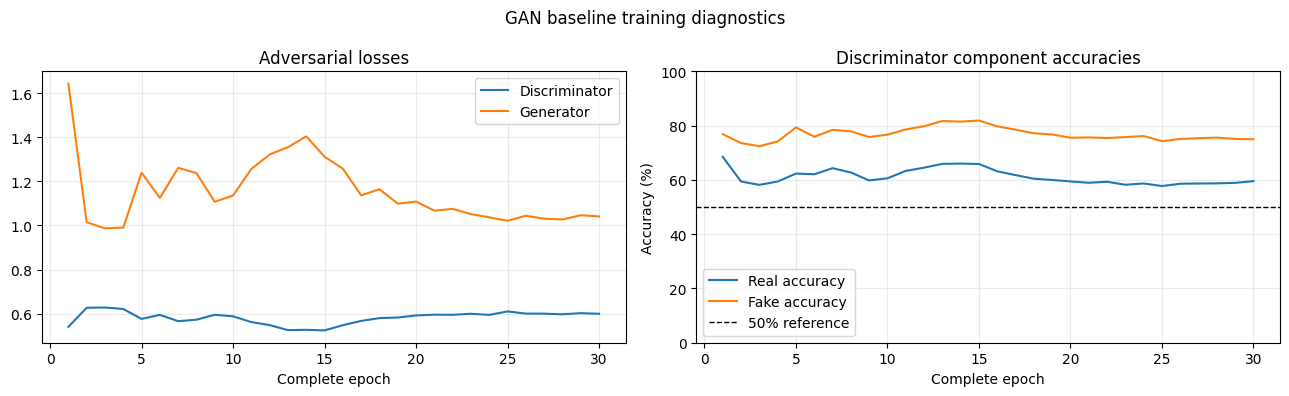

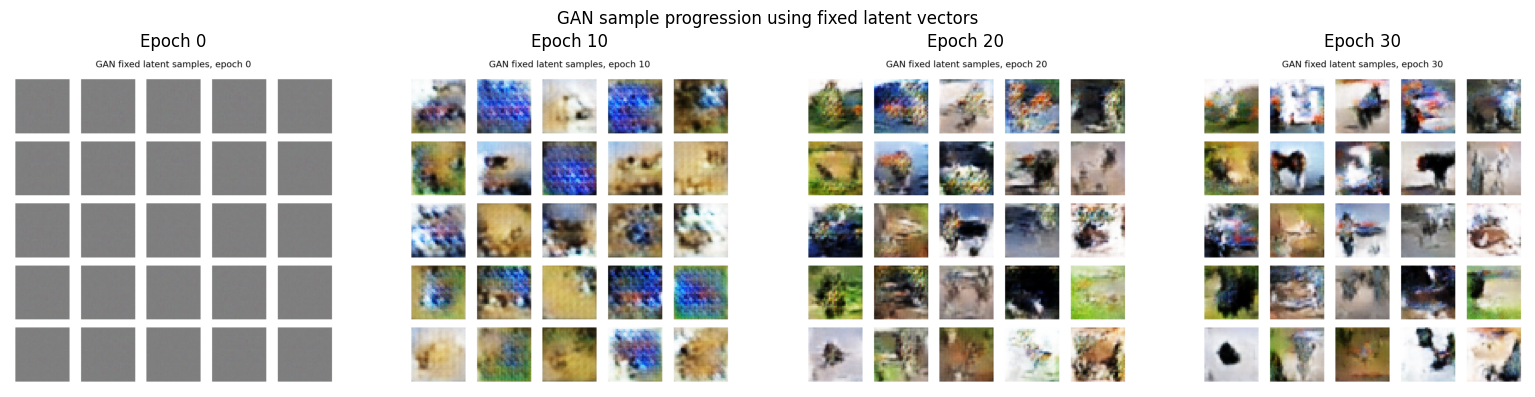

In [22]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(
    gan_history_df.index,
    gan_history_df["discriminator_loss"],
    label="Discriminator",
)
axes[0].plot(
    gan_history_df.index,
    gan_history_df["generator_loss"],
    label="Generator",
)
axes[0].set_title("Adversarial losses")
axes[0].set_xlabel("Complete epoch")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(
    gan_history_df.index,
    100 * gan_history_df["real_accuracy"],
    label="Real accuracy",
)
axes[1].plot(
    gan_history_df.index,
    100 * gan_history_df["fake_accuracy"],
    label="Fake accuracy",
)
axes[1].axhline(
    50,
    color="black",
    linestyle="--",
    linewidth=1,
    label="50% reference",
)
axes[1].set_title("Discriminator component accuracies")
axes[1].set_xlabel("Complete epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(0, 100)
axes[1].grid(alpha=0.25)
axes[1].legend()

figure.suptitle("GAN baseline training diagnostics")
figure.tight_layout()
plt.show()

show_saved_progression(
    GAN_SAMPLE_DIR,
    "gan_baseline",
    [0, 10, 20, 30],
    "GAN sample progression using fixed latent vectors",
)


In [23]:
gan_baseline_summary = pd.DataFrame([{
    "epochs": GAN_EPOCHS,
    "generator_updates": GAN_EPOCHS * STEPS_PER_EPOCH,
    "discriminator_updates": GAN_EPOCHS * STEPS_PER_EPOCH,
    "generator_parameters": GAN_GENERATOR_PARAMETER_COUNT,
    "discriminator_parameters": GAN_DISCRIMINATOR_PARAMETER_COUNT,
    "total_parameters": GAN_TOTAL_PARAMETER_COUNT,
    "training_minutes": GAN_TRAINING_SECONDS / 60,
    "final_discriminator_loss": (
        gan_history_df.iloc[-1]["discriminator_loss"]
    ),
    "final_generator_loss": gan_history_df.iloc[-1]["generator_loss"],
    "final_real_accuracy": gan_history_df.iloc[-1]["real_accuracy"],
    "final_fake_accuracy": gan_history_df.iloc[-1]["fake_accuracy"],
}])
gan_baseline_summary.to_csv(
    TABLE_DIR / "gan_baseline_summary.csv",
    index=False,
)


## 5.5 GAN Baseline Evaluation

### Findings

- Fixed samples changed from random texture into varied object-like shapes. They were sharper than the VAE samples, although many remained distorted.
- Final real and generated discriminator accuracies were `59.55%` and `74.97%`. Neither remained near `100%`, so the history does not show a discriminator that simply saturated and stopped supplying a gradient.
- Final discriminator and generator losses were `0.5992` and `1.0411`. These describe the training balance; they do not rank image quality.
- The fixed grid contained no obvious repeated-image collapse, but 25 images are too few to establish full coverage.

### Decision

I accept the unconditional GAN as the second baseline. The common validation comparison below determines whether the visual difference is supported beyond one fixed grid.


# 6. Baseline Comparison

## 6.1 Comparison Design

The VAE and GAN losses are not numerically comparable because they optimise different objectives. Their comparison uses common generated-image evidence while retaining each framework's own diagnostics.

### Controls held fixed

- The same 45,000 model-training images with no augmentation.
- RGB output resolution of `32 x 32`.
- Latent dimension 128, batch size 128 and 30 complete epochs.
- 10,560 training batches per model.
- One seeded set of 5,000 latent vectors.
- All 5,000 balanced validation images as the real reference.
- One in-memory resize, Inception preprocessing and feature-extraction path.

These controls support an internal comparison, but they do not remove FID's finite-sample bias or the domain mismatch between ImageNet features and CIFAR-10.

## 6.2 Common Validation FID

Both baselines are evaluated against all 5,000 balanced validation images using one frozen InceptionV3 feature extractor and one in-memory resize/preprocessing path. Each model generates 5,000 unfiltered images from the same fixed latent array. Lower FID indicates closer feature-distribution statistics, but does not establish class correctness or human recognisability.

In [24]:
FID_SAMPLE_COUNT = len(x_validation_vae)
FID_IMAGES_PER_CLASS = FID_SAMPLE_COUNT // len(class_names)

fid_rng = np.random.default_rng(SEED + 700)
real_fid_images = x_validation_vae[fid_rng.permutation(FID_SAMPLE_COUNT)]
fid_noise = fid_rng.normal(
    size=(FID_SAMPLE_COUNT, LATENT_DIM)
).astype("float32")

vae_fid_images = images_for_display(
    vae_decoder.predict(fid_noise, batch_size=256, verbose=0),
    output_range="sigmoid",
)
gan_fid_images = images_for_display(
    gan_generator.predict(fid_noise, batch_size=256, verbose=0),
    output_range="tanh",
)

inception_weights_path = Path(
    ".keras/models/inception_v3_weights_tf_dim_ordering_tf_kernels.h5"
)
if inception_weights_path.exists():
    inception_base = keras.applications.InceptionV3(
        include_top=True,
        weights=None,
    )
    inception_base.load_weights(inception_weights_path)
    print("Loaded cached official InceptionV3 weights.")
else:
    inception_base = keras.applications.InceptionV3(
        include_top=True,
        weights="imagenet",
    )
    print("Downloaded official InceptionV3 weights through Keras.")

inception_extractor = keras.Model(
    inception_base.input,
    inception_base.get_layer("avg_pool").output,
    name="inception_feature_extractor",
)
inception_extractor.trainable = False


Loaded cached official InceptionV3 weights.


In [25]:
def extract_inception_features(images, batch_size=32):
    dataset = tf.data.Dataset.from_tensor_slices(images).batch(batch_size)
    batches = []
    for image_batch in dataset:
        resized = tf.image.resize(
            tf.cast(image_batch, tf.float32),
            (299, 299),
            method="bicubic",
            antialias=True,
        )
        prepared = keras.applications.inception_v3.preprocess_input(
            resized * 255.0
        )
        batches.append(
            inception_extractor(prepared, training=False).numpy()
        )
    return np.concatenate(batches, axis=0)


def calculate_fid(real_features, generated_features):
    real_mean = np.mean(real_features, axis=0)
    generated_mean = np.mean(generated_features, axis=0)
    real_covariance = np.cov(real_features, rowvar=False)
    generated_covariance = np.cov(generated_features, rowvar=False)
    covariance_mean = linalg.sqrtm(
        real_covariance @ generated_covariance
    )

    if not np.isfinite(covariance_mean).all():
        offset = np.eye(real_covariance.shape[0]) * 1e-6
        covariance_mean = linalg.sqrtm(
            (real_covariance + offset)
            @ (generated_covariance + offset)
        )
    if np.iscomplexobj(covariance_mean):
        covariance_mean = covariance_mean.real

    mean_difference = real_mean - generated_mean
    return float(
        mean_difference @ mean_difference
        + np.trace(
            real_covariance
            + generated_covariance
            - 2.0 * covariance_mean
        )
    )


In [26]:
def calculate_kid(
    real_features,
    generated_features,
    subset_size=1000,
    repeats=10,
    seed=SEED + 702,
):
    if subset_size > min(len(real_features), len(generated_features)):
        raise ValueError("KID subset exceeds the available feature count.")

    rng = np.random.default_rng(seed)
    real_tensor = tf.convert_to_tensor(real_features, dtype=tf.float32)
    generated_tensor = tf.convert_to_tensor(
        generated_features,
        dtype=tf.float32,
    )
    feature_dimension = tf.cast(tf.shape(real_tensor)[1], tf.float32)
    scores = []

    for _ in range(repeats):
        real_indices = rng.choice(
            len(real_features), subset_size, replace=False
        )
        generated_indices = rng.choice(
            len(generated_features), subset_size, replace=False
        )
        real_subset = tf.gather(real_tensor, real_indices)
        generated_subset = tf.gather(
            generated_tensor,
            generated_indices,
        )

        real_kernel = (
            tf.matmul(real_subset, real_subset, transpose_b=True)
            / feature_dimension
            + 1.0
        ) ** 3
        generated_kernel = (
            tf.matmul(
                generated_subset,
                generated_subset,
                transpose_b=True,
            )
            / feature_dimension
            + 1.0
        ) ** 3
        cross_kernel = (
            tf.matmul(real_subset, generated_subset, transpose_b=True)
            / feature_dimension
            + 1.0
        ) ** 3

        denominator = float(subset_size * (subset_size - 1))
        score = (
            (tf.reduce_sum(real_kernel) - tf.linalg.trace(real_kernel))
            / denominator
            + (
                tf.reduce_sum(generated_kernel)
                - tf.linalg.trace(generated_kernel)
            )
            / denominator
            - 2.0 * tf.reduce_mean(cross_kernel)
        )
        scores.append(float(score.numpy()))

    scores = np.asarray(scores)
    return float(scores.mean()), float(scores.std(ddof=1)), scores


In [27]:
self_test_rng = np.random.default_rng(SEED + 701)
self_test_features = self_test_rng.normal(size=(500, 16))
FID_SELF_TEST = calculate_fid(
    self_test_features,
    self_test_features.copy(),
)
assert abs(FID_SELF_TEST) < 1e-6

feature_start = time.perf_counter()
real_fid_features = extract_inception_features(real_fid_images)
vae_fid_features = extract_inception_features(vae_fid_images)
gan_fid_features = extract_inception_features(gan_fid_images)
FID_FEATURE_SECONDS = time.perf_counter() - feature_start

VAE_BASELINE_FID = calculate_fid(
    real_fid_features,
    vae_fid_features,
)
GAN_BASELINE_FID = calculate_fid(
    real_fid_features,
    gan_fid_features,
)

print(f"FID implementation self-test: {FID_SELF_TEST:.10f}")
print(
    "Feature shapes:",
    real_fid_features.shape,
    vae_fid_features.shape,
    gan_fid_features.shape,
)
print(f"Feature-extraction time: {FID_FEATURE_SECONDS:.2f} seconds")
print(f"VAE validation FID: {VAE_BASELINE_FID:.4f}")
print(f"GAN validation FID: {GAN_BASELINE_FID:.4f}")


FID implementation self-test: -0.0000000000
Feature shapes: (5000, 2048) (5000, 2048) (5000, 2048)
Feature-extraction time: 77.26 seconds
VAE validation FID: 219.2612
GAN validation FID: 85.6591


  model  epochs  training_batches  parameters  training_minutes  \
0   VAE      30             10560     1188483            3.4724   
1   GAN      30             10560     1893540           11.6064   

   validation_fid_5000  weights_mb  
0             219.2612      1.9481  
1              85.6591      4.7304  

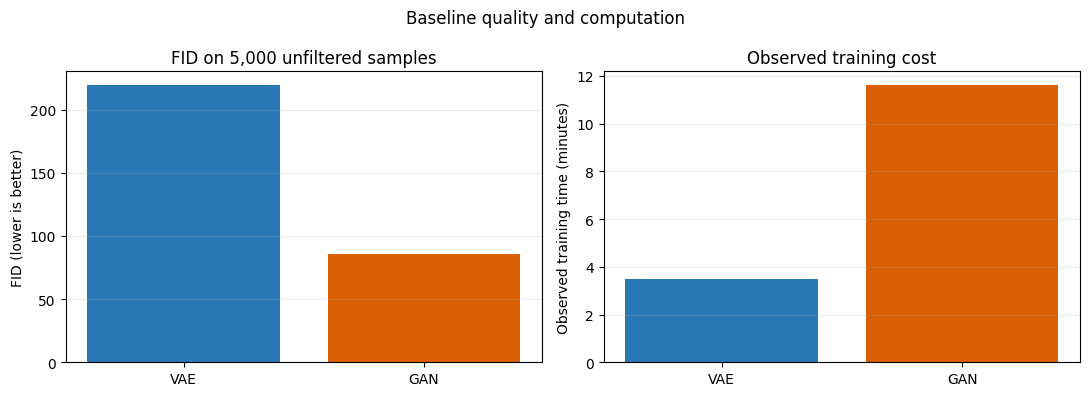

In [28]:
baseline_comparison = pd.DataFrame([
    {
        "model": "VAE",
        "epochs": VAE_EPOCHS,
        "training_batches": VAE_EPOCHS * STEPS_PER_EPOCH,
        "parameters": VAE_PARAMETER_COUNT,
        "training_minutes": VAE_TRAINING_SECONDS / 60,
        "validation_fid_5000": VAE_BASELINE_FID,
        "weights_mb": VAE_FINAL_WEIGHT_PATH.stat().st_size / (1024 ** 2),
    },
    {
        "model": "GAN",
        "epochs": GAN_EPOCHS,
        "training_batches": GAN_EPOCHS * STEPS_PER_EPOCH,
        "parameters": GAN_TOTAL_PARAMETER_COUNT,
        "training_minutes": GAN_TRAINING_SECONDS / 60,
        "validation_fid_5000": GAN_BASELINE_FID,
        "weights_mb": GAN_FINAL_WEIGHT_PATH.stat().st_size / (1024 ** 2),
    },
])
baseline_comparison.to_csv(
    TABLE_DIR / "baseline_comparison.csv",
    index=False,
)
display(baseline_comparison.round(4))

figure, axes = plt.subplots(1, 2, figsize=(11, 4))
colours = ["#2878B5", "#D95F02"]
axes[0].bar(
    baseline_comparison["model"],
    baseline_comparison["validation_fid_5000"],
    color=colours,
)
axes[0].set_title("FID on 5,000 unfiltered samples")
axes[0].set_ylabel("FID (lower is better)")
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(
    baseline_comparison["model"],
    baseline_comparison["training_minutes"],
    color=colours,
)
axes[1].set_title("Observed training cost")
axes[1].set_ylabel("Observed training time (minutes)")
axes[1].grid(axis="y", alpha=0.25)

figure.suptitle("Baseline quality and computation")
figure.tight_layout()
plt.show()


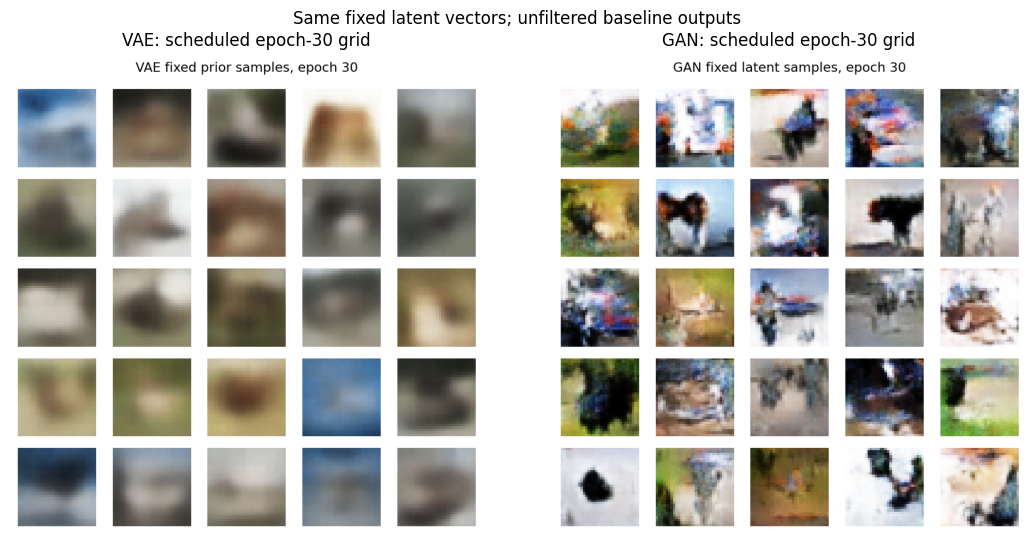

In [29]:
figure, axes = plt.subplots(1, 2, figsize=(11, 5.5))
baseline_grids = [
    (
        VAE_SAMPLE_DIR / "vae_baseline_epoch_030.png",
        "VAE: scheduled epoch-30 grid",
    ),
    (
        GAN_SAMPLE_DIR / "gan_baseline_epoch_030.png",
        "GAN: scheduled epoch-30 grid",
    ),
]
for axis, (path, title) in zip(axes, baseline_grids):
    axis.imshow(plt.imread(path))
    axis.set_title(title)
    axis.axis("off")
figure.suptitle("Same fixed latent vectors; unfiltered baseline outputs")
figure.tight_layout()
plt.show()


## 6.3 Baseline Findings and Model-Family Decision

| Measure | VAE | GAN | Reading |
|---|---:|---:|---|
| Validation FID, 5,000 samples | `219.26` | `85.66` | The GAN is much closer to the validation feature distribution in this fixed pipeline |
| Parameters | `1,188,483` | `1,893,540` | The GAN uses `59.3%` more parameters |
| Training time | `3.47` min | `11.61` min | The GAN is slower because both networks are updated each batch |
| Fixed samples | Smooth broad forms | Sharper object-like forms | The visual direction agrees with FID, although neither baseline is consistently clear |

I carry the **GAN** forward. Its FID is `133.60` points lower and the unfiltered samples show a matching practical improvement. The extra time and parameters therefore buy a substantial change rather than a marginal score difference. This ranks only these two baselines under the shared budget; it is not a general claim that GANs always outperform VAEs.


## 6.4 Choosing the First Intervention

| Candidate | When it would be useful | Decision from the baseline |
|---|---|---|
| Class conditioning | Images have varied structure but weak class identity | **Test first:** this directly addresses the observed ambiguity and enables requested-class generation |
| Latent dimension | Outputs repeat or the latent space is visibly restrictive | Defer: the fixed samples are varied, so a larger latent vector does not target the main weakness |
| Learning rate | One network saturates or progression stalls | Defer: neither discriminator accuracy is near perfect and samples continue changing |
| More generator/discriminator capacity | Both networks underfit despite a useful learning signal | Defer: the baseline already learns object-like structure; extra depth would add cost without addressing class control |
| Label smoothing | The discriminator is overconfident | Do not test yet: the accuracy history does not show that failure |
| Augmentation | Discriminator overfitting is visible | Do not test yet: the current diagnostics do not separate overfitting from ordinary GAN difficulty |
| More epochs | Checkpoint results are still improving at the endpoint | Revisit only after a model has comparable checkpoint FID and class-match results |

This keeps the first experiment tied to the baseline weakness instead of changing a convenient hyperparameter without a reason.


# 7. Controlled Experiment 1: Class Conditioning

## 7.1 Experiment Plan

The baseline GAN produces object-like images, but many cannot be assigned confidently to one CIFAR-10 class. The task also asks how a requested class could be generated, so I test a conditional GAN (cGAN), following [Mirza and Osindero](https://arxiv.org/abs/1411.1784).

| Item | Decision before training |
|---|---|
| Question | Does supplying the requested class improve controllability while retaining the baseline's overall distribution quality? |
| Main changed factor | Add class conditioning to both generator and discriminator |
| Held constant | Training images, normalization, convolutional depth and widths, latent dimension, optimizer, batch size, 30 epochs and checkpoint interval |
| Mechanism | The generator receives the class vector; the discriminator adds a learned image-feature/class projection to its source score |
| Evidence | Final and checkpoint FID, independent requested-class match, fixed same-noise class grids, GAN diagnostics and added cost |
| Rejection reason | Labels mainly alter colour/background, class match remains weak, or distribution quality deteriorates substantially |

The projection term is necessary for a meaningful conditional discriminator: it makes the real/fake score depend on compatibility between image features and the requested class. Learning rate, label smoothing, augmentation and upsampling method are not changed in this experiment.

## 7.2 Independent Class-Consistency Check

FID cannot determine whether a generated image matches its requested class. I train one compact CIFAR-10 classifier on the same 45,000-image model-training set and measure it on the 5,000-image validation set. Its validation accuracy and per-class recall are reported before it is used as supporting evidence.

This evaluator is not ground truth. It may respond to colour or texture shortcuts, so requested-class match is interpreted beside fixed image grids and FID. The official test set remains unused at this stage.

In [30]:
EXPERIMENT_OUTPUT_DIR = Path("part_a_experiment_outputs")
EXPERIMENT_WEIGHT_DIR = EXPERIMENT_OUTPUT_DIR / "weights"
EXPERIMENT_SAMPLE_DIR = EXPERIMENT_OUTPUT_DIR / "samples"
EXPERIMENT_TABLE_DIR = EXPERIMENT_OUTPUT_DIR / "tables"

for directory in (
    EXPERIMENT_WEIGHT_DIR,
    EXPERIMENT_SAMPLE_DIR,
    EXPERIMENT_TABLE_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

EVALUATOR_EPOCHS = 20
EVALUATOR_BATCH_SIZE = 256


def build_cifar10_evaluator():
    inputs = keras.Input(IMAGE_SHAPE)
    x = inputs
    blocks = [(32, 0.15), (64, 0.20), (128, 0.25)]
    for filters, dropout_rate in blocks:
        for _ in range(2):
            x = keras.layers.Conv2D(
                filters,
                3,
                padding="same",
                use_bias=False,
            )(x)
            x = keras.layers.BatchNormalization()(x)
            x = keras.layers.ReLU()(x)
        x = keras.layers.MaxPooling2D()(x)
        x = keras.layers.Dropout(dropout_rate)(x)

    x = keras.layers.Conv2D(
        256,
        3,
        padding="same",
        activation="relu",
    )(x)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(0.30)(x)
    outputs = keras.layers.Dense(
        len(class_names),
        activation="softmax",
    )(x)
    return keras.Model(inputs, outputs, name="cifar10_class_evaluator")


In [31]:
keras.utils.set_random_seed(SEED + 500)
class_evaluator = build_cifar10_evaluator()
class_evaluator.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

evaluator_y_train = keras.utils.to_categorical(
    y_model_train,
    len(class_names),
).astype("float32")
evaluator_y_validation = keras.utils.to_categorical(
    y_validation,
    len(class_names),
).astype("float32")

training_start = time.perf_counter()
evaluator_history_object = class_evaluator.fit(
    x_train_vae,
    evaluator_y_train,
    validation_data=(x_validation_vae, evaluator_y_validation),
    epochs=EVALUATOR_EPOCHS,
    batch_size=EVALUATOR_BATCH_SIZE,
    shuffle=True,
    verbose=2,
)
EVALUATOR_TRAINING_SECONDS = time.perf_counter() - training_start

evaluator_history = history_frame(
    evaluator_history_object,
    EVALUATOR_EPOCHS,
    EXPERIMENT_TABLE_DIR / "class_evaluator_history.csv",
)
evaluator_weights_path = (
    EXPERIMENT_WEIGHT_DIR / "class_evaluator.weights.h5"
)
class_evaluator.save_weights(evaluator_weights_path)


Epoch 1/20


176/176 - 14s - loss: 1.6132 - accuracy: 0.3995 - val_loss: 3.5429 - val_accuracy: 0.1304 - 14s/epoch - 82ms/step


Epoch 2/20


176/176 - 13s - loss: 1.1446 - accuracy: 0.5847 - val_loss: 2.1644 - val_accuracy: 0.2974 - 13s/epoch - 72ms/step


Epoch 3/20


176/176 - 13s - loss: 0.9539 - accuracy: 0.6584 - val_loss: 1.3137 - val_accuracy: 0.5438 - 13s/epoch - 73ms/step


... (30 outputs left out)

Epoch 19/20


176/176 - 14s - loss: 0.3445 - accuracy: 0.8785 - val_loss: 0.5495 - val_accuracy: 0.8190 - 14s/epoch - 81ms/step


Epoch 20/20


176/176 - 14s - loss: 0.3286 - accuracy: 0.8850 - val_loss: 0.4613 - val_accuracy: 0.8408 - 14s/epoch - 81ms/step


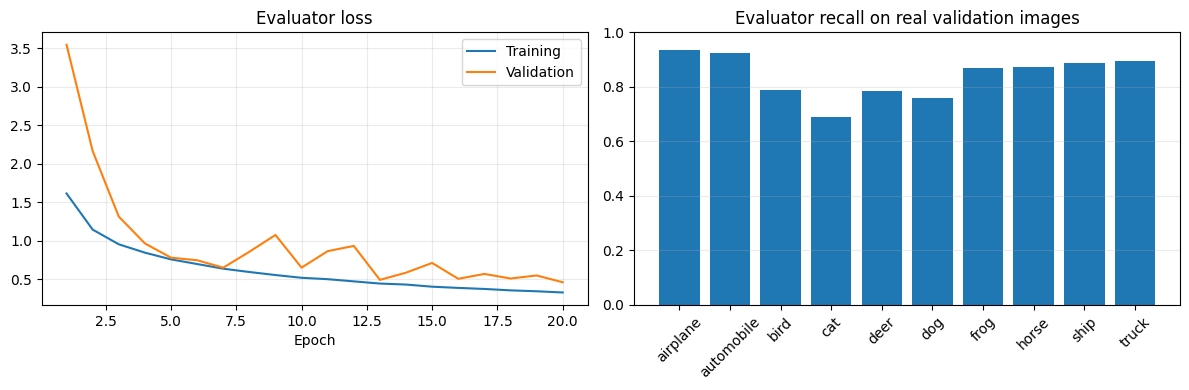

Evaluator validation accuracy: 0.8408
Training time: 4.67 minutes


        class  validation_count  recall
0    airplane               500   0.934
1  automobile               500   0.926
2        bird               500   0.788
3         cat               500   0.690
4        deer               500   0.784
5         dog               500   0.760
6        frog               500   0.870
7       horse               500   0.872
8        ship               500   0.888
9       truck               500   0.896

In [32]:
evaluator_validation = class_evaluator.evaluate(
    x_validation_vae,
    evaluator_y_validation,
    batch_size=EVALUATOR_BATCH_SIZE,
    return_dict=True,
    verbose=0,
)
evaluator_predictions = class_evaluator.predict(
    x_validation_vae,
    batch_size=EVALUATOR_BATCH_SIZE,
    verbose=0,
).argmax(axis=1)

evaluator_per_class = pd.DataFrame([
    {
        "class": class_name,
        "validation_count": int(np.sum(y_validation == class_id)),
        "recall": float(np.mean(
            evaluator_predictions[y_validation == class_id] == class_id
        )),
    }
    for class_id, class_name in enumerate(class_names)
])
evaluator_per_class.to_csv(
    EXPERIMENT_TABLE_DIR / "class_evaluator_per_class.csv",
    index=False,
)

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(
    evaluator_history.index,
    evaluator_history["loss"],
    label="Training",
)
axes[0].plot(
    evaluator_history.index,
    evaluator_history["val_loss"],
    label="Validation",
)
axes[0].set_title("Evaluator loss")
axes[0].set_xlabel("Epoch")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].bar(
    evaluator_per_class["class"],
    evaluator_per_class["recall"],
)
axes[1].set_title("Evaluator recall on real validation images")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="y", alpha=0.25)
figure.tight_layout()
plt.show()

print(f"Evaluator validation accuracy: {evaluator_validation['accuracy']:.4f}")
print(f"Training time: {EVALUATOR_TRAINING_SECONDS / 60:.2f} minutes")
display(evaluator_per_class.round(4))


**Evaluator finding.** Validation accuracy is `84.08%`, but reliability is not equal across classes. Recall is highest for airplane (`93.4%`) and automobile (`92.6%`) and lowest for cat (`69.0%`) and dog (`76.0%`). Later class-match results will therefore be interpreted class by class and alongside the generated images; a low cat or dog match may partly reflect evaluator error, while a high match still cannot prove realism.

## 7.3 Conditional Architecture and Implementation Check

- The generator adds a one-hot class vector to the same 128-dimensional noise input while retaining the baseline spatial blocks.
- The discriminator retains the baseline image backbone. Its source score combines an unconditional image logit with the dot product between image features and a learned class projection.
- The bilinear projection can reward a matching image-label pair and penalize a mismatch; a final linear concatenation would only learn a class-specific offset and is therefore not used.
- Learning rates, batch size, epoch budget, training images, fixed noise, checkpoint schedule and source loss remain unchanged.

Before training, I verify generator and discriminator shapes, finite values, output range, and that changing only the class label changes the projection-conditioned source score for a fixed image.

In [33]:
NUMBER_OF_CLASSES = len(class_names)
CONDITIONAL_SEED = SEED
CONDITIONAL_EPOCHS = 30
CONDITIONAL_SAMPLE_DIR = EXPERIMENT_SAMPLE_DIR / "conditional_gan"
CONDITIONAL_SAMPLE_DIR.mkdir(parents=True, exist_ok=True)


def build_conditional_generator(latent_dim=LATENT_DIM):
    noise_input = keras.Input((latent_dim,), name="noise")
    class_input = keras.Input(
        (NUMBER_OF_CLASSES,),
        name="class_one_hot",
    )
    x = keras.layers.Concatenate()([noise_input, class_input])
    x = keras.layers.Dense(4 * 4 * 256, use_bias=False)(x)
    x = keras.layers.BatchNormalization(momentum=0.8)(x)
    x = keras.layers.LeakyReLU(alpha=0.2)(x)
    x = keras.layers.Reshape((4, 4, 256))(x)

    for filters in (128, 64, 32):
        x = keras.layers.Conv2DTranspose(
            filters,
            4,
            strides=2,
            padding="same",
            use_bias=False,
        )(x)
        x = keras.layers.BatchNormalization(momentum=0.8)(x)
        x = keras.layers.LeakyReLU(alpha=0.2)(x)

    outputs = keras.layers.Conv2D(
        3,
        3,
        padding="same",
        activation="tanh",
    )(x)
    return keras.Model(
        [noise_input, class_input],
        outputs,
        name="conditional_generator",
    )


def build_conditioned_discriminator(
    include_class_head=False,
    model_name="conditioned_discriminator",
):
    image_input = keras.Input(IMAGE_SHAPE, name="image")
    class_input = keras.Input(
        (NUMBER_OF_CLASSES,),
        name="class_one_hot",
    )
    x = image_input
    for filters in (64, 128, 256):
        x = keras.layers.Conv2D(
            filters,
            4,
            strides=2,
            padding="same",
        )(x)
        x = keras.layers.LeakyReLU(alpha=0.2)(x)
        x = keras.layers.Dropout(0.3)(x)

    image_features = keras.layers.Flatten(name="image_features")(x)
    unconditional_source = keras.layers.Dense(
        1,
        name="unconditional_source_logit",
    )(image_features)
    class_projection = keras.layers.Dense(
        int(image_features.shape[-1]),
        use_bias=False,
        name="class_projection",
    )(class_input)
    projection_score = keras.layers.Dot(
        axes=1,
        name="image_class_projection",
    )([image_features, class_projection])
    source_output = keras.layers.Add(name="source_logit")([
        unconditional_source,
        projection_score,
    ])

    outputs = source_output
    if include_class_head:
        class_output = keras.layers.Dense(
            NUMBER_OF_CLASSES,
            name="class_logits",
        )(image_features)
        outputs = [source_output, class_output]

    return keras.Model(
        [image_input, class_input],
        outputs,
        name=model_name,
    )


In [34]:
class ConditionalGAN(keras.Model):
    def __init__(self, generator, discriminator, latent_dim, **kwargs):
        super().__init__(**kwargs)
        self.generator = generator
        self.discriminator = discriminator
        self.latent_dim = latent_dim
        self.discriminator_loss_tracker = keras.metrics.Mean(
            name="discriminator_loss"
        )
        self.generator_loss_tracker = keras.metrics.Mean(
            name="generator_loss"
        )
        self.real_accuracy_tracker = keras.metrics.Mean(
            name="real_accuracy"
        )
        self.fake_accuracy_tracker = keras.metrics.Mean(
            name="fake_accuracy"
        )

    @property
    def metrics(self):
        return [
            self.discriminator_loss_tracker,
            self.generator_loss_tracker,
            self.real_accuracy_tracker,
            self.fake_accuracy_tracker,
        ]

    def compile(self, discriminator_optimizer, generator_optimizer, loss_fn):
        super().compile()
        self.discriminator_optimizer = discriminator_optimizer
        self.generator_optimizer = generator_optimizer
        self.loss_fn = loss_fn

    def train_step(self, data):
        real_images, integer_labels = data
        integer_labels = tf.cast(
            tf.reshape(integer_labels, (-1,)),
            tf.int32,
        )
        class_labels = tf.one_hot(
            integer_labels,
            NUMBER_OF_CLASSES,
        )
        batch_size = tf.shape(real_images)[0]
        noise = tf.random.normal((batch_size, self.latent_dim))
        generated_images = self.generator(
            [noise, class_labels],
            training=True,
        )

        with tf.GradientTape() as tape:
            real_logits = self.discriminator(
                [real_images, class_labels],
                training=True,
            )
            fake_logits = self.discriminator(
                [tf.stop_gradient(generated_images), class_labels],
                training=True,
            )
            real_loss = self.loss_fn(tf.ones_like(real_logits), real_logits)
            fake_loss = self.loss_fn(tf.zeros_like(fake_logits), fake_logits)
            discriminator_loss = 0.5 * (real_loss + fake_loss)

        gradients = tape.gradient(
            discriminator_loss,
            self.discriminator.trainable_weights,
        )
        self.discriminator_optimizer.apply_gradients(
            zip(gradients, self.discriminator.trainable_weights)
        )

        noise = tf.random.normal((batch_size, self.latent_dim))
        with tf.GradientTape() as tape:
            generated_images = self.generator(
                [noise, class_labels],
                training=True,
            )
            generated_logits = self.discriminator(
                [generated_images, class_labels],
                training=True,
            )
            generator_loss = self.loss_fn(
                tf.ones_like(generated_logits),
                generated_logits,
            )

        gradients = tape.gradient(
            generator_loss,
            self.generator.trainable_weights,
        )
        self.generator_optimizer.apply_gradients(
            zip(gradients, self.generator.trainable_weights)
        )

        self.discriminator_loss_tracker.update_state(discriminator_loss)
        self.generator_loss_tracker.update_state(generator_loss)
        self.real_accuracy_tracker.update_state(
            tf.reduce_mean(tf.cast(real_logits >= 0.0, tf.float32))
        )
        self.fake_accuracy_tracker.update_state(
            tf.reduce_mean(tf.cast(fake_logits < 0.0, tf.float32))
        )
        return {metric.name: metric.result() for metric in self.metrics}


In [35]:
base_conditional_noise = np.random.default_rng(SEED + 1001).normal(
    size=(5, LATENT_DIM)
).astype("float32")
CONDITIONAL_FIXED_NOISE = np.repeat(
    base_conditional_noise,
    NUMBER_OF_CLASSES,
    axis=0,
)
CONDITIONAL_FIXED_LABEL_IDS = np.tile(
    np.arange(NUMBER_OF_CLASSES),
    5,
).astype("int32")
CONDITIONAL_FIXED_LABELS = keras.utils.to_categorical(
    CONDITIONAL_FIXED_LABEL_IDS,
    NUMBER_OF_CLASSES,
).astype("float32")
CONDITIONAL_FIXED_INPUTS = [
    CONDITIONAL_FIXED_NOISE,
    CONDITIONAL_FIXED_LABELS,
]

keras.utils.set_random_seed(CONDITIONAL_SEED)
conditional_generator = build_conditional_generator()
conditional_discriminator = build_conditioned_discriminator(
    model_name="conditional_discriminator"
)
conditional_gan = ConditionalGAN(
    conditional_generator,
    conditional_discriminator,
    LATENT_DIM,
    name="conditional_gan",
)
conditional_gan.compile(
    discriminator_optimizer=keras.optimizers.Adam(
        0.0002,
        beta_1=0.5,
    ),
    generator_optimizer=keras.optimizers.Adam(
        0.0002,
        beta_1=0.5,
    ),
    loss_fn=keras.losses.BinaryCrossentropy(from_logits=True),
)


In [36]:
probe_labels = keras.utils.to_categorical(
    np.arange(4),
    NUMBER_OF_CLASSES,
).astype("float32")
probe_noise = np.random.default_rng(SEED + 1002).normal(
    size=(4, LATENT_DIM)
).astype("float32")
probe_images = conditional_generator(
    [probe_noise, probe_labels],
    training=False,
)
probe_logits = conditional_discriminator(
    [probe_images, probe_labels],
    training=False,
)
fixed_image_batch = tf.repeat(probe_images[:1], repeats=4, axis=0)
fixed_image_class_logits = conditional_discriminator(
    [fixed_image_batch, probe_labels],
    training=False,
)

CONDITIONAL_INITIAL_GENERATOR_OUTPUT = probe_images.numpy().copy()
CONDITIONAL_INITIAL_SOURCE_OUTPUT = probe_logits.numpy().copy()

assert probe_images.shape == (4, *IMAGE_SHAPE)
assert probe_logits.shape == (4, 1)
assert np.isfinite(probe_images.numpy()).all()
assert np.isfinite(fixed_image_class_logits.numpy()).all()
assert float(tf.math.reduce_std(fixed_image_class_logits)) > 0.0
assert -1.0 <= float(tf.reduce_min(probe_images))
assert float(tf.reduce_max(probe_images)) <= 1.0

print("Conditional model checks passed.")
print("Generator parameters:", f"{conditional_generator.count_params():,}")
print(
    "Discriminator parameters:",
    f"{conditional_discriminator.count_params():,}",
)


Conditional model checks passed.
Generator parameters: 1,271,523
Discriminator parameters: 703,937


### Check result

The conditional generator and discriminator produced the expected shapes, finite values and label-sensitive source scores. The experiment configuration was left unchanged.

## 7.4 Training

The model uses the same 30 complete epochs and checkpoint schedule as the GAN baseline. Labels are paired with their images before deterministic shuffling, and the same label controls both generation and source judgement.

In [37]:
conditional_dataset = make_training_dataset(
    x_train_gan,
    y_model_train,
    seed=CONDITIONAL_SEED,
)
conditional_callback = FixedSampleCheckpoint(
    generator=conditional_generator,
    model_inputs=CONDITIONAL_FIXED_INPUTS,
    sample_dir=CONDITIONAL_SAMPLE_DIR,
    weight_dir=EXPERIMENT_WEIGHT_DIR,
    prefix="conditional_gan",
    output_range="tanh",
    rows=5,
    columns=10,
    title="Conditional GAN fixed class grid",
)

keras.utils.set_random_seed(CONDITIONAL_SEED)
training_start = time.perf_counter()
conditional_history_object = conditional_gan.fit(
    conditional_dataset,
    epochs=CONDITIONAL_EPOCHS,
    callbacks=[conditional_callback],
    verbose=2,
)
CONDITIONAL_TRAINING_SECONDS = time.perf_counter() - training_start

conditional_history = history_frame(
    conditional_history_object,
    CONDITIONAL_EPOCHS,
    EXPERIMENT_TABLE_DIR / "conditional_gan_history.csv",
)
CONDITIONAL_FINAL_WEIGHT_PATH = (
    EXPERIMENT_WEIGHT_DIR / "conditional_gan_final.weights.h5"
)
conditional_generator.save_weights(CONDITIONAL_FINAL_WEIGHT_PATH)

print(f"Training complete: {len(conditional_history)} complete epochs")
print("Fixed-sample checkpoints:", checkpoint_epochs(CONDITIONAL_EPOCHS))
print(f"Training time: {CONDITIONAL_TRAINING_SECONDS / 60:.2f} minutes")


Epoch 1/30


352/352 - 36s - discriminator_loss: 0.5088 - generator_loss: 1.9290 - real_accuracy: 0.7281 - fake_accuracy: 0.7715 - 36s/epoch - 103ms/step


Epoch 2/30


352/352 - 29s - discriminator_loss: 0.6137 - generator_loss: 0.9871 - real_accuracy: 0.6273 - fake_accuracy: 0.7135 - 29s/epoch - 81ms/step


Epoch 3/30


352/352 - 28s - discriminator_loss: 0.5754 - generator_loss: 1.1793 - real_accuracy: 0.6492 - fake_accuracy: 0.7667 - 28s/epoch - 80ms/step


... (51 outputs left out)

352/352 - 23s - discriminator_loss: 0.5791 - generator_loss: 1.0839 - real_accuracy: 0.6369 - fake_accuracy: 0.7391 - 23s/epoch - 66ms/step


Epoch 30/30


352/352 - 24s - discriminator_loss: 0.5815 - generator_loss: 1.0784 - real_accuracy: 0.6314 - fake_accuracy: 0.7385 - 24s/epoch - 68ms/step


Training complete: 30 complete epochs
Fixed-sample checkpoints: [0, 5, 10, 15, 20, 25, 30]
Training time: 13.34 minutes


## 7.5 Validation Evidence

All 30 epoch records are saved and checked for finite values. Images and weights are saved every five epochs. Because each FID calculation requires 5,000 generated and 5,000 validation-image features, I calculate FID and class match at epochs `10`, `20` and `30` and display those same three grids. The latent vectors, requested labels, validation reference and feature pipeline remain fixed. I compare the endpoint with the unconditional GAN using FID, KID, the unfiltered grids and requested-class match. KID is restricted to this model-family intervention as planned.

In [38]:
conditional_fid_label_ids = np.repeat(
    np.arange(NUMBER_OF_CLASSES),
    FID_IMAGES_PER_CLASS,
).astype("int32")
conditional_fid_labels = keras.utils.to_categorical(
    conditional_fid_label_ids,
    NUMBER_OF_CLASSES,
).astype("float32")


def experiment_checkpoint_path(prefix, epoch_number):
    return (
        EXPERIMENT_WEIGHT_DIR
        / f"{prefix}_epoch_{epoch_number:03d}.weights.h5"
    )


def evaluate_conditional_checkpoints(prefix, epochs, batch_size=256):
    records = []
    predictions = {}
    features = {}

    for epoch_number in epochs:
        generator = build_conditional_generator()
        generator.load_weights(
            experiment_checkpoint_path(prefix, epoch_number)
        )
        generated_images = images_for_display(
            generator.predict(
                [fid_noise, conditional_fid_labels],
                batch_size=batch_size,
                verbose=0,
            ),
            "tanh",
        )
        generated_features = extract_inception_features(generated_images)
        generated_predictions = class_evaluator.predict(
            generated_images,
            batch_size=batch_size,
            verbose=0,
        ).argmax(axis=1)

        predictions[epoch_number] = generated_predictions
        features[epoch_number] = generated_features
        records.append({
            "epoch": epoch_number,
            "validation_fid_5000": calculate_fid(
                real_fid_features,
                generated_features,
            ),
            "requested_class_match": float(np.mean(
                generated_predictions == conditional_fid_label_ids
            )),
        })

    return pd.DataFrame(records), predictions, features


def per_class_match(predictions, column_name="requested_class_match"):
    return pd.DataFrame([
        {
            "class": class_name,
            column_name: float(np.mean(
                predictions[conditional_fid_label_ids == class_id]
                == class_id
            )),
        }
        for class_id, class_name in enumerate(class_names)
    ])


def plot_checkpoint_metrics(table, title_prefix):
    figure, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(
        table["epoch"],
        table["validation_fid_5000"],
        marker="o",
    )
    axes[0].set_title(f"{title_prefix} FID")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("FID (lower is better)")
    axes[0].grid(alpha=0.25)

    axes[1].plot(
        table["epoch"],
        table["requested_class_match"],
        marker="o",
    )
    axes[1].set_title(f"{title_prefix} class match")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylim(0, 1)
    axes[1].grid(alpha=0.25)
    figure.tight_layout()
    plt.show()


In [39]:
(
    conditional_checkpoint_evaluation,
    conditional_predictions,
    conditional_features,
) = evaluate_conditional_checkpoints(
    "conditional_gan",
    [10, 20, 30],
)
conditional_checkpoint_evaluation.to_csv(
    EXPERIMENT_TABLE_DIR
    / "conditional_gan_checkpoint_evaluation.csv",
    index=False,
)

conditional_epoch_30_features = conditional_features[30]
conditional_epoch_30_predictions = conditional_predictions[30]
conditional_per_class = per_class_match(
    conditional_epoch_30_predictions
)
conditional_per_class["sample_count"] = FID_IMAGES_PER_CLASS
conditional_per_class["evaluator_real_validation_recall"] = (
    evaluator_per_class.set_index("class").loc[
        conditional_per_class["class"],
        "recall",
    ].to_numpy()
)
conditional_per_class.to_csv(
    EXPERIMENT_TABLE_DIR / "conditional_gan_per_class.csv",
    index=False,
)

GAN_KID_MEAN, GAN_KID_STD, _ = calculate_kid(
    real_fid_features,
    gan_fid_features,
)
CGAN_KID_MEAN, CGAN_KID_STD, _ = calculate_kid(
    real_fid_features,
    conditional_epoch_30_features,
)
kid_comparison = pd.DataFrame([
    {
        "model": "Unconditional GAN",
        "kid_mean": GAN_KID_MEAN,
        "kid_std": GAN_KID_STD,
    },
    {
        "model": "Conditional GAN",
        "kid_mean": CGAN_KID_MEAN,
        "kid_std": CGAN_KID_STD,
    },
])
kid_comparison["kid_mean_x1000"] = 1000 * kid_comparison["kid_mean"]
kid_comparison["kid_std_x1000"] = 1000 * kid_comparison["kid_std"]
kid_comparison.to_csv(
    EXPERIMENT_TABLE_DIR / "gan_vs_cgan_kid.csv",
    index=False,
)


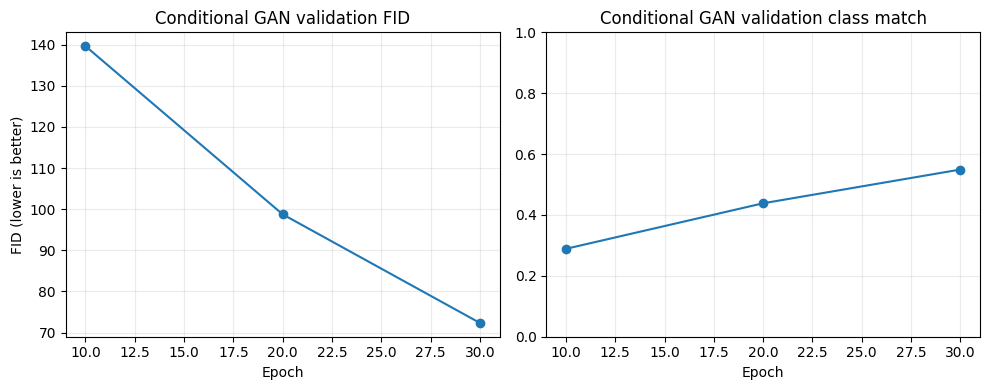

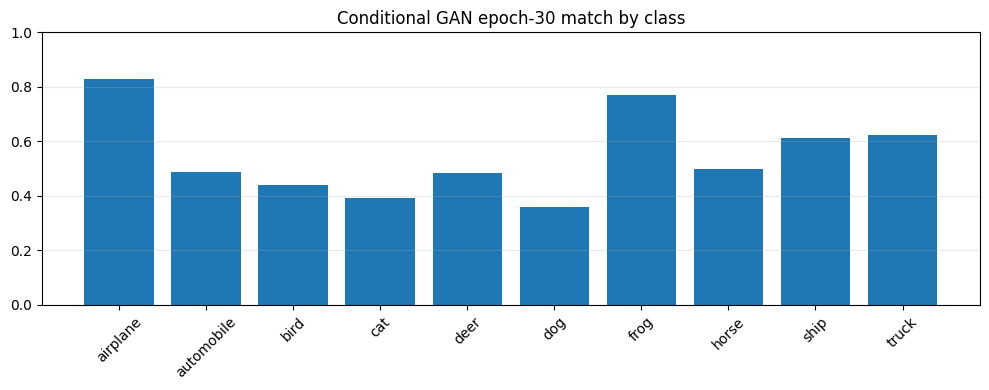

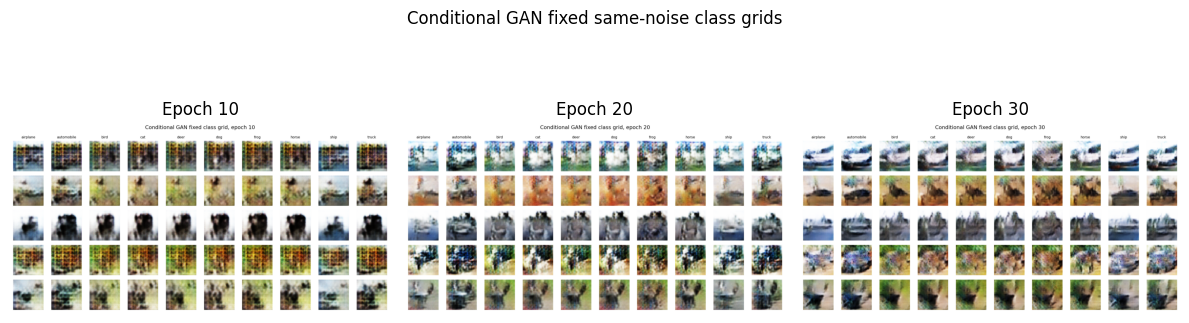

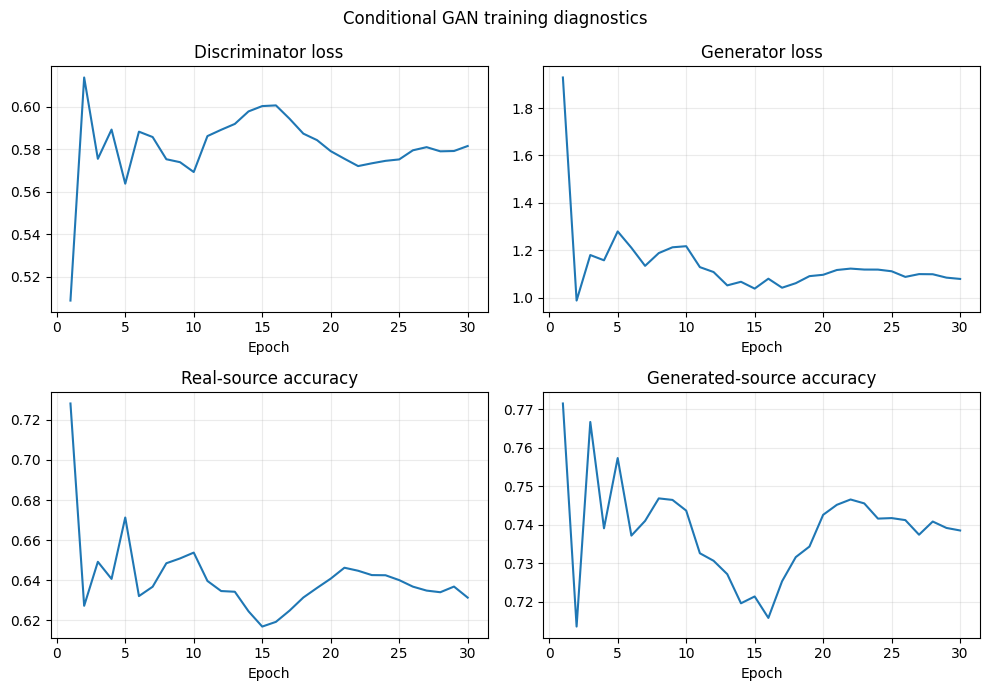

   epoch  validation_fid_5000  requested_class_match
0     10             139.6103                 0.2888
1     20              98.7432                 0.4384
2     30              72.3630                 0.5492

               model  kid_mean   kid_std  kid_mean_x1000  kid_std_x1000
0  Unconditional GAN  0.059262  0.001933       59.261537       1.933429
1    Conditional GAN  0.046189  0.001287       46.189237       1.286558

        class  requested_class_match  sample_count  \
0    airplane                  0.828           500   
1  automobile                  0.488           500   
2        bird                  0.440           500   
3         cat                  0.392           500   
4        deer                  0.484           500   
5         dog                  0.358           500   
6        frog                  0.770           500   
7       horse                  0.498           500   
8        ship                  0.612           500   
9       truck                  0.622           500   

   evaluator_real_validation_recall  
0                             0.934  
1                             0.926  
2                             0.788  
3                             0.690  
4                             0.784  
5                             0.760  
6                             0.870  
7                             0.872  
8                             0.888  
9                        

In [40]:
conditional_final_row = (
    conditional_checkpoint_evaluation.set_index("epoch").loc[30]
)
conditional_summary = pd.DataFrame([{
    "experiment": "Conditional GAN",
    "epochs": CONDITIONAL_EPOCHS,
    "generator_parameters": conditional_generator.count_params(),
    "discriminator_parameters": conditional_discriminator.count_params(),
    "total_parameters": (
        conditional_generator.count_params()
        + conditional_discriminator.count_params()
    ),
    "training_minutes": CONDITIONAL_TRAINING_SECONDS / 60,
    "validation_fid_5000": conditional_final_row["validation_fid_5000"],
    "requested_class_match": conditional_final_row[
        "requested_class_match"
    ],
    "kid_mean": CGAN_KID_MEAN,
}])
conditional_summary.to_csv(
    EXPERIMENT_TABLE_DIR / "conditional_gan_summary.csv",
    index=False,
)

plot_checkpoint_metrics(
    conditional_checkpoint_evaluation,
    "Conditional GAN validation",
)

figure, axis = plt.subplots(figsize=(10, 4))
axis.bar(
    conditional_per_class["class"],
    conditional_per_class["requested_class_match"],
)
axis.set_title("Conditional GAN epoch-30 match by class")
axis.set_ylim(0, 1)
axis.tick_params(axis="x", rotation=45)
axis.grid(axis="y", alpha=0.25)
figure.tight_layout()
plt.show()

show_saved_progression(
    CONDITIONAL_SAMPLE_DIR,
    "conditional_gan",
    [10, 20, 30],
    "Conditional GAN fixed same-noise class grids",
)

plot_training_diagnostics(
    conditional_history,
    SOURCE_DIAGNOSTICS,
    "Conditional GAN training diagnostics",
)

display(conditional_checkpoint_evaluation.round(4))
display(kid_comparison.round(6))
display(conditional_per_class.round(4))


## 7.6 Experiment 1 Decision

- Validation FID improved from `85.66` to `72.36`.
- Repeated-subset KID moved in the same direction, from `59.26 +/- 1.93` to `46.19 +/- 1.29` (`x 10^-3`). These repeats measure subset sensitivity, not independent training variation.
- Requested-class match rose from `28.88%` at epoch 10 to `43.84%` at epoch 20 and `54.92%` at epoch 30, above the `10%` chance level.
- Class control was uneven. Airplane reached `82.8%`, while dog reached only `35.8%`; this agrees with the evaluator's weaker recall on animal classes and with the ambiguity in the grids.
- Conditioning added `81,920` parameters (`4.3%`) and increased this run from `11.61` to `13.34` minutes.

I keep the projection cGAN. Both distribution measures improve, and the independent evaluator confirms that the requested label affects the output. The uneven class results motivate a direct class objective rather than a learning-rate or capacity change.


# 8. Controlled Experiment 2: Auxiliary Class Objective

## 8.1 Experiment Plan

The projection cGAN receives a class label, but its discriminator is trained only to separate real from generated image-label pairs. I add a ten-class prediction head to test whether a direct semantic objective improves control over the requested class.

| Element | Decision |
|---|---|
| Parent | Projection cGAN from Experiment 1 |
| Changed factor | Ten-class discriminator head and categorical cross-entropy objective |
| Matched comparison | Same generator, conditioned source head, backbone, initialization, data order, latent inputs, optimizers, batch size and epoch-30 checkpoint |
| Main evidence | Overall and per-class requested-label match |
| Guard evidence | Validation FID, fixed grids, training behaviour and parameter count |
| Rejection condition | Class control does not improve broadly, or the gain is outweighed by poorer distribution quality |

The run is allowed to reach 60 epochs once. Experiment 2 uses only its epoch-30 checkpoint so the architectural comparison remains matched; Section 9 separately examines whether the same model benefits from further training.

## 8.2 Architecture and Control Check

I keep the Experiment 1 generator, image backbone and conditioned source head unchanged. The only addition is a ten-class prediction branch from the discriminator features. Before training, I reset the seed and compare both versions on identical inputs; their generator and source outputs must match before I attribute any later difference to the new class objective.

In [41]:
AUXILIARY_EPOCHS = 60
AUXILIARY_SAMPLE_DIR = EXPERIMENT_SAMPLE_DIR / "auxiliary_cgan"
AUXILIARY_SAMPLE_DIR.mkdir(parents=True, exist_ok=True)


def build_auxiliary_discriminator():
    return build_conditioned_discriminator(
        include_class_head=True,
        model_name="auxiliary_class_conditional_discriminator",
    )


class AuxiliaryClassConditionalGAN(keras.Model):
    def __init__(self, generator, discriminator, latent_dim, **kwargs):
        super().__init__(**kwargs)
        self.generator = generator
        self.discriminator = discriminator
        self.latent_dim = latent_dim
        metric_names = [
            "discriminator_loss",
            "generator_loss",
            "real_accuracy",
            "fake_accuracy",
            "real_class_accuracy",
            "fake_class_accuracy",
        ]
        self.metric_trackers = {
            name: keras.metrics.Mean(name=name)
            for name in metric_names
        }

    @property
    def metrics(self):
        return list(self.metric_trackers.values())

    def compile(
        self,
        discriminator_optimizer,
        generator_optimizer,
        source_loss_fn,
        class_loss_fn,
    ):
        super().compile()
        self.discriminator_optimizer = discriminator_optimizer
        self.generator_optimizer = generator_optimizer
        self.source_loss_fn = source_loss_fn
        self.class_loss_fn = class_loss_fn

    def train_step(self, data):
        real_images, integer_labels = data
        integer_labels = tf.cast(
            tf.reshape(integer_labels, (-1,)),
            tf.int32,
        )
        class_labels = tf.one_hot(
            integer_labels,
            NUMBER_OF_CLASSES,
        )
        batch_size = tf.shape(real_images)[0]
        noise = tf.random.normal((batch_size, self.latent_dim))
        generated_images = self.generator(
            [noise, class_labels],
            training=True,
        )

        with tf.GradientTape() as tape:
            real_source, real_classes = self.discriminator(
                [real_images, class_labels],
                training=True,
            )
            fake_source, fake_classes = self.discriminator(
                [tf.stop_gradient(generated_images), class_labels],
                training=True,
            )
            source_loss = 0.5 * (
                self.source_loss_fn(
                    tf.ones_like(real_source),
                    real_source,
                )
                + self.source_loss_fn(
                    tf.zeros_like(fake_source),
                    fake_source,
                )
            )
            class_loss = 0.5 * (
                self.class_loss_fn(class_labels, real_classes)
                + self.class_loss_fn(class_labels, fake_classes)
            )
            discriminator_loss = source_loss + class_loss

        gradients = tape.gradient(
            discriminator_loss,
            self.discriminator.trainable_weights,
        )
        self.discriminator_optimizer.apply_gradients(
            zip(gradients, self.discriminator.trainable_weights)
        )

        noise = tf.random.normal((batch_size, self.latent_dim))
        with tf.GradientTape() as tape:
            generated_images = self.generator(
                [noise, class_labels],
                training=True,
            )
            generated_source, generated_classes = self.discriminator(
                [generated_images, class_labels],
                training=True,
            )
            generator_loss = self.source_loss_fn(
                tf.ones_like(generated_source),
                generated_source,
            ) + self.class_loss_fn(class_labels, generated_classes)

        gradients = tape.gradient(
            generator_loss,
            self.generator.trainable_weights,
        )
        self.generator_optimizer.apply_gradients(
            zip(gradients, self.generator.trainable_weights)
        )

        real_class_accuracy = tf.reduce_mean(tf.cast(
            tf.argmax(real_classes, axis=1, output_type=tf.int32)
            == integer_labels,
            tf.float32,
        ))
        fake_class_accuracy = tf.reduce_mean(tf.cast(
            tf.argmax(fake_classes, axis=1, output_type=tf.int32)
            == integer_labels,
            tf.float32,
        ))
        metric_values = {
            "discriminator_loss": discriminator_loss,
            "generator_loss": generator_loss,
            "real_accuracy": tf.reduce_mean(
                tf.cast(real_source >= 0.0, tf.float32)
            ),
            "fake_accuracy": tf.reduce_mean(
                tf.cast(fake_source < 0.0, tf.float32)
            ),
            "real_class_accuracy": real_class_accuracy,
            "fake_class_accuracy": fake_class_accuracy,
        }
        for name, value in metric_values.items():
            self.metric_trackers[name].update_state(value)
        return {
            name: tracker.result()
            for name, tracker in self.metric_trackers.items()
        }


In [42]:
def create_auxiliary_cgan(
    name,
    class_loss_fn,
    seed=CONDITIONAL_SEED,
):
    keras.utils.set_random_seed(seed)
    generator = build_conditional_generator()
    discriminator = build_auxiliary_discriminator()
    model = AuxiliaryClassConditionalGAN(
        generator,
        discriminator,
        LATENT_DIM,
        name=name,
    )
    model.compile(
        discriminator_optimizer=keras.optimizers.Adam(
            0.0002,
            beta_1=0.5,
        ),
        generator_optimizer=keras.optimizers.Adam(
            0.0002,
            beta_1=0.5,
        ),
        source_loss_fn=keras.losses.BinaryCrossentropy(
            from_logits=True
        ),
        class_loss_fn=class_loss_fn,
    )
    return generator, discriminator, model


standard_class_loss = keras.losses.CategoricalCrossentropy(
    from_logits=True
)
(
    auxiliary_generator,
    auxiliary_discriminator,
    auxiliary_cgan,
) = create_auxiliary_cgan(
    "auxiliary_class_conditional_gan",
    standard_class_loss,
)


In [43]:
auxiliary_probe_images = auxiliary_generator(
    [probe_noise, probe_labels],
    training=False,
)
auxiliary_source, auxiliary_classes = auxiliary_discriminator(
    [auxiliary_probe_images, probe_labels],
    training=False,
)
AUXILIARY_INITIAL_GENERATOR_ERROR = float(np.max(np.abs(
    auxiliary_probe_images.numpy()
    - CONDITIONAL_INITIAL_GENERATOR_OUTPUT
)))
AUXILIARY_INITIAL_SOURCE_ERROR = float(np.max(np.abs(
    auxiliary_source.numpy()
    - CONDITIONAL_INITIAL_SOURCE_OUTPUT
)))

assert auxiliary_probe_images.shape == (4, *IMAGE_SHAPE)
assert auxiliary_source.shape == (4, 1)
assert auxiliary_classes.shape == (4, NUMBER_OF_CLASSES)
assert AUXILIARY_INITIAL_GENERATOR_ERROR < 1e-6
assert AUXILIARY_INITIAL_SOURCE_ERROR < 1e-6

print("Auxiliary-class model checks passed.")
print(
    "Initial generator difference:",
    f"{AUXILIARY_INITIAL_GENERATOR_ERROR:.10f}",
)
print(
    "Initial conditioned-source difference:",
    f"{AUXILIARY_INITIAL_SOURCE_ERROR:.10f}",
)
print("Generator parameters:", f"{auxiliary_generator.count_params():,}")
print(
    "Discriminator parameters:",
    f"{auxiliary_discriminator.count_params():,}",
)


Auxiliary-class model checks passed.
Initial generator difference: 0.0000000000
Initial conditioned-source difference: 0.0000000000
Generator parameters: 1,271,523
Discriminator parameters: 744,907


### Check result

Before training, the two versions produced identical generator images and source scores. The class head is therefore the only architectural difference.

## 8.3 Training

The class loss is applied to real and generated images in the discriminator update and to generated images in the generator update. Fixed grids and weights follow the unchanged five-epoch schedule.

In [44]:
auxiliary_dataset = make_training_dataset(
    x_train_gan,
    y_model_train,
    seed=CONDITIONAL_SEED,
)
auxiliary_callback = FixedSampleCheckpoint(
    generator=auxiliary_generator,
    model_inputs=CONDITIONAL_FIXED_INPUTS,
    sample_dir=AUXILIARY_SAMPLE_DIR,
    weight_dir=EXPERIMENT_WEIGHT_DIR,
    prefix="auxiliary_cgan",
    output_range="tanh",
    rows=5,
    columns=10,
    title="Auxiliary-class cGAN fixed class grid",
)

keras.utils.set_random_seed(CONDITIONAL_SEED)
training_start = time.perf_counter()
auxiliary_history_object = auxiliary_cgan.fit(
    auxiliary_dataset,
    epochs=AUXILIARY_EPOCHS,
    callbacks=[auxiliary_callback],
    verbose=2,
)
AUXILIARY_TRAINING_SECONDS = time.perf_counter() - training_start

auxiliary_history = history_frame(
    auxiliary_history_object,
    AUXILIARY_EPOCHS,
    EXPERIMENT_TABLE_DIR / "auxiliary_cgan_history.csv",
)
AUXILIARY_FINAL_WEIGHT_PATH = (
    EXPERIMENT_WEIGHT_DIR / "auxiliary_cgan_final.weights.h5"
)
auxiliary_generator.save_weights(AUXILIARY_FINAL_WEIGHT_PATH)

print(f"Training complete: {len(auxiliary_history)} epochs")
print("Fixed-sample checkpoints:", checkpoint_epochs(AUXILIARY_EPOCHS))
print(f"Training time: {AUXILIARY_TRAINING_SECONDS / 60:.2f} minutes")


Epoch 1/60


352/352 - 25s - discriminator_loss: 2.1705 - generator_loss: 2.8570 - real_accuracy: 0.7202 - fake_accuracy: 0.7890 - real_class_accuracy: 0.3025 - fake_class_accuracy: 0.6166 - 25s/epoch - 72ms/step


Epoch 2/60


352/352 - 24s - discriminator_loss: 1.7327 - generator_loss: 1.6729 - real_accuracy: 0.6776 - fake_accuracy: 0.7560 - real_class_accuracy: 0.4025 - fake_class_accuracy: 0.9498 - 24s/epoch - 69ms/step


Epoch 3/60


352/352 - 24s - discriminator_loss: 1.6225 - generator_loss: 1.6619 - real_accuracy: 0.6919 - fake_accuracy: 0.7705 - real_class_accuracy: 0.4451 - fake_class_accuracy: 0.9520 - 24s/epoch - 69ms/step


... (111 outputs left out)

352/352 - 31s - discriminator_loss: 0.9951 - generator_loss: 1.2449 - real_accuracy: 0.6432 - fake_accuracy: 0.7122 - real_class_accuracy: 0.7775 - fake_class_accuracy: 0.9582 - 31s/epoch - 89ms/step


Epoch 60/60


352/352 - 36s - discriminator_loss: 0.9964 - generator_loss: 1.2438 - real_accuracy: 0.6397 - fake_accuracy: 0.7065 - real_class_accuracy: 0.7804 - fake_class_accuracy: 0.9564 - 36s/epoch - 102ms/step


Training complete: 60 epochs
Fixed-sample checkpoints: [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60]
Training time: 27.93 minutes


## 8.4 Epoch-30 Comparison

The architectural comparison is made at epoch 30 because the parent projection cGAN was trained for 30 epochs. I use FID and requested-class match from the same validation sample, then inspect per-class changes, fixed-noise grids and training behaviour. Later checkpoints are not used to make this architecture-only claim.

In [45]:
(
    auxiliary_checkpoint_evaluation,
    auxiliary_predictions,
    _,
) = evaluate_conditional_checkpoints(
    "auxiliary_cgan",
    [10, 20, 30],
)
auxiliary_checkpoint_evaluation.to_csv(
    EXPERIMENT_TABLE_DIR
    / "auxiliary_cgan_checkpoint_evaluation.csv",
    index=False,
)

auxiliary_per_class = per_class_match(auxiliary_predictions[30])
auxiliary_per_class["sample_count"] = FID_IMAGES_PER_CLASS
auxiliary_per_class.to_csv(
    EXPERIMENT_TABLE_DIR / "auxiliary_cgan_per_class.csv",
    index=False,
)

auxiliary_class_comparison = conditional_per_class[
    ["class", "requested_class_match"]
].merge(
    auxiliary_per_class[["class", "requested_class_match"]],
    on="class",
    suffixes=("_cgan", "_auxiliary_cgan"),
)
auxiliary_class_comparison["change"] = (
    auxiliary_class_comparison[
        "requested_class_match_auxiliary_cgan"
    ]
    - auxiliary_class_comparison["requested_class_match_cgan"]
)
auxiliary_class_comparison.to_csv(
    EXPERIMENT_TABLE_DIR / "auxiliary_cgan_class_comparison.csv",
    index=False,
)


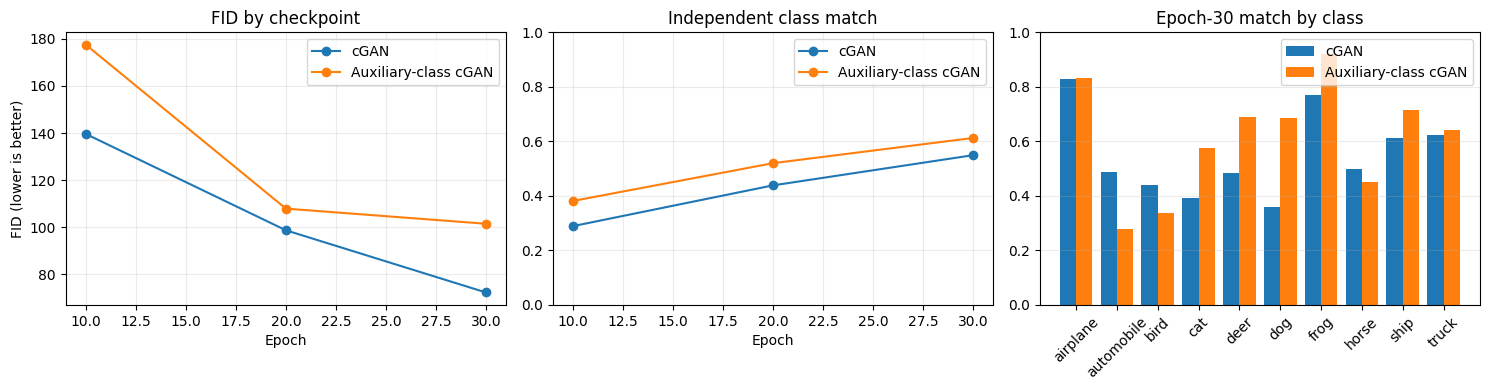

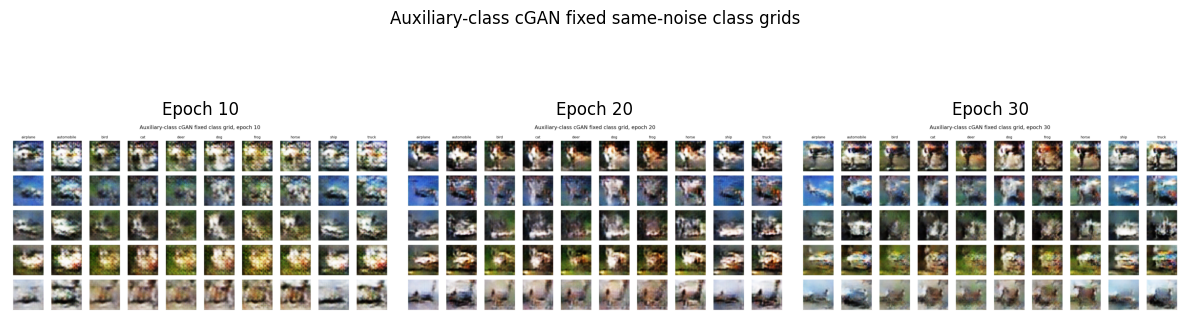

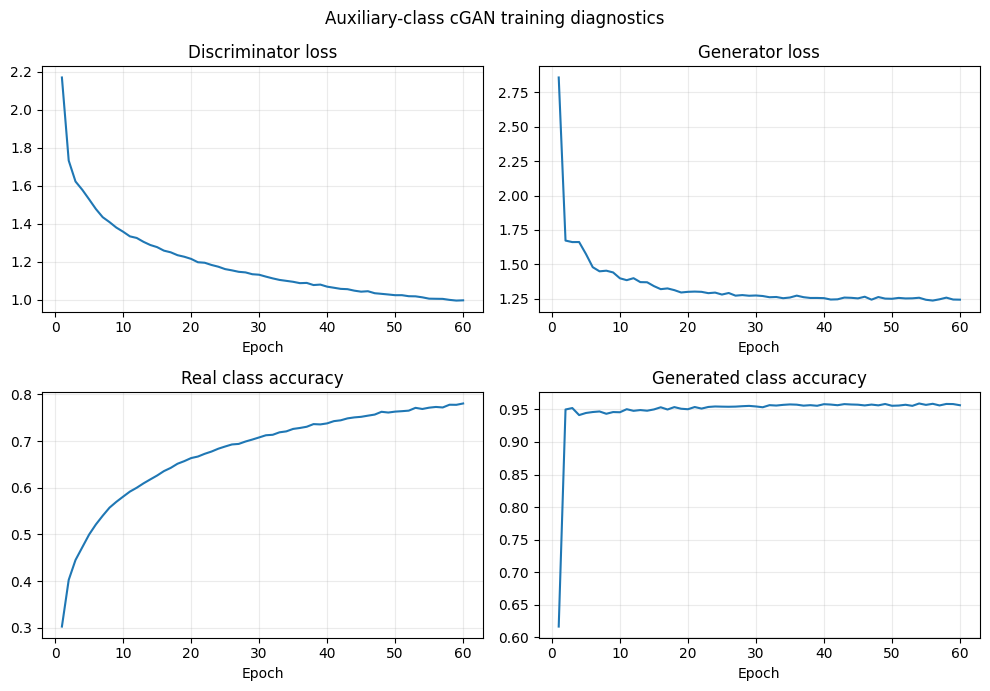

   epoch  validation_fid_5000  requested_class_match
0     10             177.4430                 0.3812
1     20             107.9340                 0.5198
2     30             101.5098                 0.6124

        class  requested_class_match_cgan  \
0    airplane                       0.828   
1  automobile                       0.488   
2        bird                       0.440   
3         cat                       0.392   
4        deer                       0.484   
5         dog                       0.358   
6        frog                       0.770   
7       horse                       0.498   
8        ship                       0.612   
9       truck                       0.622   

   requested_class_match_auxiliary_cgan  change  
0                                 0.832   0.004  
1                                 0.280  -0.208  
2                                 0.336  -0.104  
3                                 0.574   0.182  
4                                 0.688   0.204  
5                                 0.684   0.326  
6                                 0.922   0.152  
7                                 0.450  -0.048  
8                                 0.716   0.104  
9   

In [46]:
auxiliary_final_row = (
    auxiliary_checkpoint_evaluation.set_index("epoch").loc[30]
)
auxiliary_summary = pd.DataFrame([{
    "experiment": "Auxiliary-class cGAN at epoch 30",
    "comparison_epoch": 30,
    "generator_parameters": auxiliary_generator.count_params(),
    "discriminator_parameters": auxiliary_discriminator.count_params(),
    "total_parameters": (
        auxiliary_generator.count_params()
        + auxiliary_discriminator.count_params()
    ),
    "validation_fid_5000": auxiliary_final_row[
        "validation_fid_5000"
    ],
    "requested_class_match": auxiliary_final_row[
        "requested_class_match"
    ],
}])
auxiliary_summary.to_csv(
    EXPERIMENT_TABLE_DIR / "auxiliary_cgan_summary.csv",
    index=False,
)

figure, axes = plt.subplots(1, 3, figsize=(15, 4))
for table, label in (
    (conditional_checkpoint_evaluation, "cGAN"),
    (auxiliary_checkpoint_evaluation, "Auxiliary-class cGAN"),
):
    axes[0].plot(
        table["epoch"],
        table["validation_fid_5000"],
        marker="o",
        label=label,
    )
    axes[1].plot(
        table["epoch"],
        table["requested_class_match"],
        marker="o",
        label=label,
    )
axes[0].set_title("FID by checkpoint")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("FID (lower is better)")
axes[0].grid(alpha=0.25)
axes[0].legend()
axes[1].set_title("Independent class match")
axes[1].set_xlabel("Epoch")
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.25)
axes[1].legend()

positions = np.arange(NUMBER_OF_CLASSES)
axes[2].bar(
    positions - 0.2,
    auxiliary_class_comparison["requested_class_match_cgan"],
    width=0.4,
    label="cGAN",
)
axes[2].bar(
    positions + 0.2,
    auxiliary_class_comparison[
        "requested_class_match_auxiliary_cgan"
    ],
    width=0.4,
    label="Auxiliary-class cGAN",
)
axes[2].set_title("Epoch-30 match by class")
axes[2].set_xticks(positions, class_names, rotation=45)
axes[2].set_ylim(0, 1)
axes[2].grid(axis="y", alpha=0.25)
axes[2].legend()
figure.tight_layout()
plt.show()

show_saved_progression(
    AUXILIARY_SAMPLE_DIR,
    "auxiliary_cgan",
    [10, 20, 30],
    "Auxiliary-class cGAN fixed same-noise class grids",
)

plot_training_diagnostics(
    auxiliary_history,
    AUXILIARY_DIAGNOSTICS,
    "Auxiliary-class cGAN training diagnostics",
)

display(auxiliary_checkpoint_evaluation.round(4))
display(auxiliary_class_comparison.round(4))


## 8.5 Experiment 2 Decision

At the matched epoch-30 checkpoint, the auxiliary head increased requested-class match from `54.92%` to `61.24%`, but FID worsened from `72.36` to `101.51`. Six classes improved and four declined. The largest gains were dog (`+32.6` percentage points), deer (`+20.4`) and cat (`+18.2`); automobile (`-20.8`) and bird (`-10.4`) regressed.

The class objective is therefore useful for control but does not replace the projection cGAN at this checkpoint: the semantic gain is accompanied by a large distribution-quality cost. Because both validation measures and the fixed grids were still changing at epoch 30, I examine the later checkpoints from this same uninterrupted run before deciding whether the architecture itself should be rejected.


# 9. Duration Investigation

## 9.1 Question and Controls

Both validation measures were still changing at epoch 30, so I inspect later checkpoints from the same uninterrupted auxiliary-cGAN run. Architecture, optimizer state, data order and initialization remain unchanged; only training exposure increases.

The comparison uses epochs 30, 35, 40, 45, 50, 55 and 60. FID is the primary checkpoint measure, while requested-class match, all ten class rows, fixed-noise grids and training diagnostics check whether an aggregate gain hides semantic or visual deterioration.

In [47]:
DURATION_CHECKPOINTS = [30, 35, 40, 45, 50, 55, 60]

(
    duration_checkpoint_evaluation,
    duration_predictions,
    _,
) = evaluate_conditional_checkpoints(
    "auxiliary_cgan",
    DURATION_CHECKPOINTS,
)
duration_checkpoint_evaluation.to_csv(
    EXPERIMENT_TABLE_DIR
    / "auxiliary_cgan_duration_evaluation.csv",
    index=False,
)

duration_per_class = per_class_match(
    duration_predictions[30],
    "epoch_30_match",
)
for epoch_number in [45, 60]:
    duration_per_class = duration_per_class.merge(
        per_class_match(
            duration_predictions[epoch_number],
            f"epoch_{epoch_number}_match",
        ),
        on="class",
        validate="one_to_one",
    )
duration_per_class["change_30_to_60"] = (
    duration_per_class["epoch_60_match"]
    - duration_per_class["epoch_30_match"]
)
duration_per_class.to_csv(
    EXPERIMENT_TABLE_DIR / "auxiliary_cgan_duration_per_class.csv",
    index=False,
)

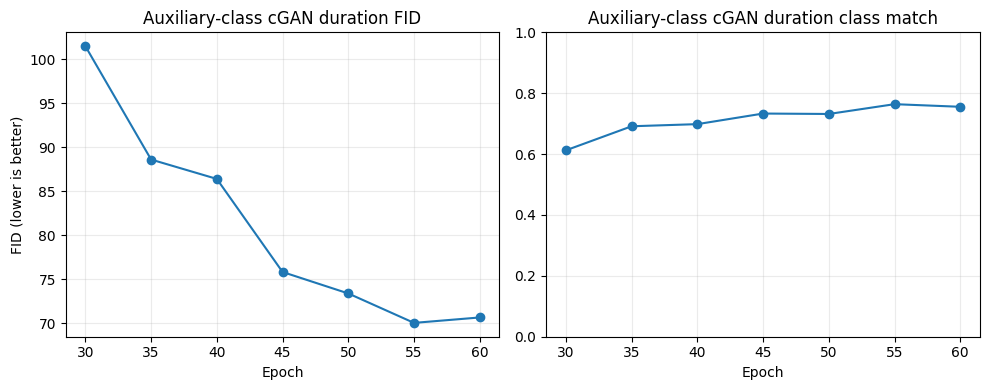

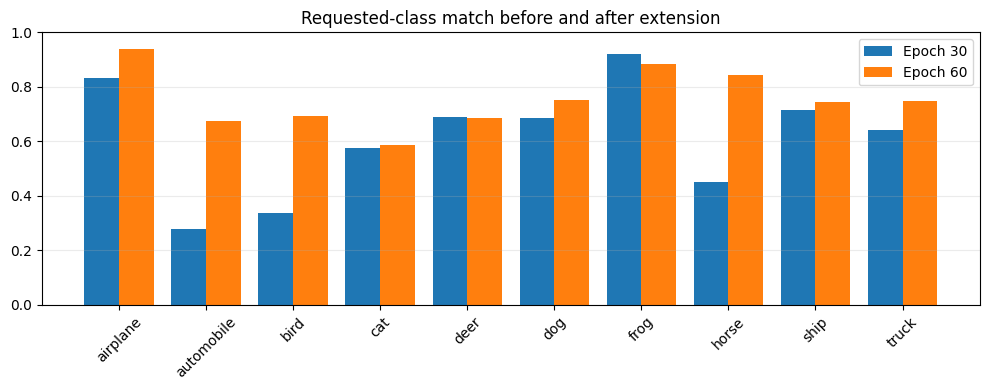

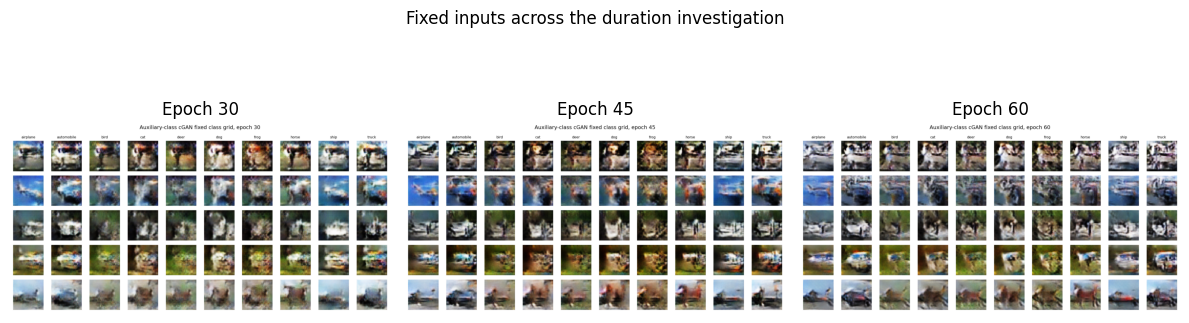

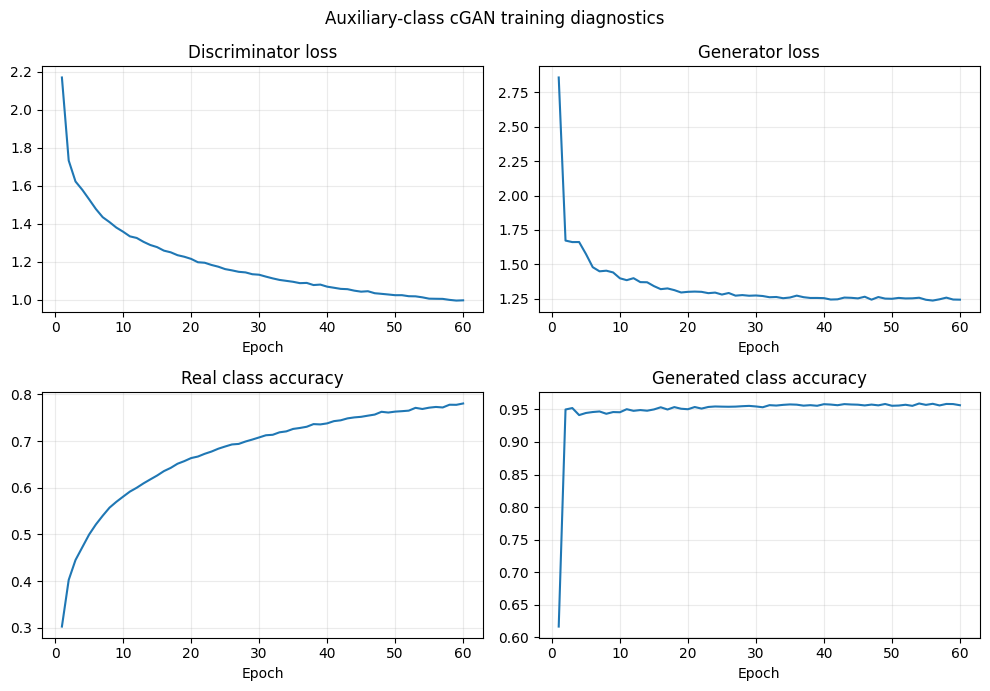

   epoch  validation_fid_5000  requested_class_match
0     30             101.5098                 0.6124
1     35              88.6279                 0.6914
2     40              86.4256                 0.6984
3     45              75.8499                 0.7332
4     50              73.4115                 0.7318
5     55              70.0676                 0.7640
6     60              70.6841                 0.7554

        class  epoch_30_match  epoch_45_match  epoch_60_match  change_30_to_60
0    airplane           0.832           0.896           0.940            0.108
1  automobile           0.280           0.602           0.676            0.396
2        bird           0.336           0.448           0.692            0.356
3         cat           0.574           0.568           0.588            0.014
4        deer           0.688           0.688           0.686           -0.002
5         dog           0.684           0.752           0.752            0.068
6        frog           0.922           0.926           0.884           -0.038
7       horse           0.450           0.788           0.844            0.394
8        ship           0.716           0.826           0.744            0.028
9       truck           0.642           0.838           0.748            0.106

In [48]:
plot_checkpoint_metrics(
    duration_checkpoint_evaluation,
    "Auxiliary-class cGAN duration",
)

positions = np.arange(NUMBER_OF_CLASSES)
figure, axis = plt.subplots(figsize=(10, 4))
axis.bar(
    positions - 0.2,
    duration_per_class["epoch_30_match"],
    width=0.4,
    label="Epoch 30",
)
axis.bar(
    positions + 0.2,
    duration_per_class["epoch_60_match"],
    width=0.4,
    label="Epoch 60",
)
axis.set_title("Requested-class match before and after extension")
axis.set_xticks(positions, class_names, rotation=45)
axis.set_ylim(0, 1)
axis.grid(axis="y", alpha=0.25)
axis.legend()
figure.tight_layout()
plt.show()

show_saved_progression(
    AUXILIARY_SAMPLE_DIR,
    "auxiliary_cgan",
    [30, 45, 60],
    "Fixed inputs across the duration investigation",
)

plot_training_diagnostics(
    auxiliary_history,
    AUXILIARY_DIAGNOSTICS,
    "Auxiliary-class cGAN training diagnostics",
)

display(duration_checkpoint_evaluation.round(4))
display(duration_per_class.round(4))

## 9.2 Duration Decision

FID fell from `101.51` at epoch 30 to `70.07` at epoch 55, then changed slightly to `70.68` at epoch 60. Requested-class match rose from `61.24%` to `76.40%` at epoch 55 and ended at `75.54%`. The final five epochs therefore show a small plateau rather than a collapse.

The class table gives the more important result: eight of ten classes improved from epoch 30 to 60. Automobile (`+39.6` points), horse (`+39.4`) and bird (`+35.6`) gained most, while deer (`-0.2`) and frog (`-3.8`) slipped. Epoch 60 remains close to the best FID checkpoint and retains strong overall class control, so I use it as the duration-matched parent for the final controlled experiment. The later cross-seed comparison checks whether this conclusion is stable beyond seed 42.


# 10. Controlled Experiment 3: Weak-Class Weighting

## 10.1 Experiment Plan

The two weakest requested classes at epoch 60 are selected directly from the independent evaluator. I double their raw auxiliary-loss weight, then normalize all ten weights to a mean of one so the intervention changes relative class emphasis rather than the average loss scale.

The weighted and unweighted models use the same 60-epoch budget, initialization, data order, architecture and optimization settings. The hypothesis requires both targeted classes to improve; model replacement additionally requires competitive FID, overall class match and fixed-sample quality.

## 10.2 Implementation and Control Check

The two weakest classes receive raw weight `2`; all others receive `1`. I divide all weights by their mean so the average auxiliary-loss scale remains `1.0`. This limits the intervention to relative class emphasis rather than silently increasing the whole class objective.

Before training, I verify the intended two-to-one loss ratio and compare fixed initial generator outputs with the unweighted parent run.

In [49]:
WEIGHTED_EPOCHS = AUXILIARY_EPOCHS
WEIGHTED_PREFIX = "weighted_auxiliary_cgan"
WEIGHTED_SAMPLE_DIR = EXPERIMENT_SAMPLE_DIR / WEIGHTED_PREFIX
WEIGHTED_SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

weak_class_rows = duration_per_class.nsmallest(
    2,
    "epoch_60_match",
)
WEAK_CLASS_NAMES = weak_class_rows["class"].tolist()
WEAK_CLASS_IDS = np.array([
    int(np.flatnonzero(class_names == class_name)[0])
    for class_name in WEAK_CLASS_NAMES
], dtype="int32")

raw_class_loss_weights = np.ones(NUMBER_OF_CLASSES, dtype="float32")
raw_class_loss_weights[WEAK_CLASS_IDS] = 2.0
normalized_class_loss_weights = (
    raw_class_loss_weights / raw_class_loss_weights.mean()
)
CLASS_LOSS_WEIGHTS = tf.constant(
    normalized_class_loss_weights,
    dtype=tf.float32,
)


def weak_class_weighted_loss(targets, logits):
    per_example_loss = keras.losses.categorical_crossentropy(
        targets,
        logits,
        from_logits=True,
    )
    per_example_weight = tf.reduce_sum(
        targets * CLASS_LOSS_WEIGHTS,
        axis=1,
    )
    return tf.reduce_mean(per_example_loss * per_example_weight)


In [50]:
zero_logits = tf.zeros((1, NUMBER_OF_CLASSES), dtype=tf.float32)
other_class_id = int(np.flatnonzero(~np.isin(
    np.arange(NUMBER_OF_CLASSES),
    WEAK_CLASS_IDS,
))[0])
other_target = tf.one_hot([other_class_id], NUMBER_OF_CLASSES)
weak_target = tf.one_hot([WEAK_CLASS_IDS[0]], NUMBER_OF_CLASSES)
other_probe_loss = float(
    weak_class_weighted_loss(other_target, zero_logits).numpy()
)
weak_probe_loss = float(
    weak_class_weighted_loss(weak_target, zero_logits).numpy()
)
assert np.isclose(weak_probe_loss / other_probe_loss, 2.0, atol=1e-6)
assert np.isclose(normalized_class_loss_weights.mean(), 1.0)

(
    weighted_generator,
    weighted_discriminator,
    weighted_auxiliary_cgan,
) = create_auxiliary_cgan(
    "weak_class_weighted_auxiliary_cgan",
    weak_class_weighted_loss,
)

initial_reference_generator = build_conditional_generator()
initial_reference_generator.load_weights(
    experiment_checkpoint_path("auxiliary_cgan", 0)
)
weighted_initial_output = weighted_generator(
    [CONDITIONAL_FIXED_NOISE, CONDITIONAL_FIXED_LABELS],
    training=False,
).numpy()
reference_initial_output = initial_reference_generator(
    [CONDITIONAL_FIXED_NOISE, CONDITIONAL_FIXED_LABELS],
    training=False,
).numpy()
WEIGHTED_INITIAL_REFERENCE_ERROR = float(np.max(np.abs(
    weighted_initial_output - reference_initial_output
)))
assert WEIGHTED_INITIAL_REFERENCE_ERROR < 1e-6

weighted_probe_images = weighted_generator(
    [probe_noise, probe_labels],
    training=False,
)
weighted_source, weighted_classes = weighted_discriminator(
    [weighted_probe_images, probe_labels],
    training=False,
)
assert weighted_probe_images.shape == (4, *IMAGE_SHAPE)
assert weighted_source.shape == (4, 1)
assert weighted_classes.shape == (4, NUMBER_OF_CLASSES)

weight_table = pd.DataFrame({
    "class": class_names,
    "normalized_class_loss_weight": normalized_class_loss_weights,
})
display(weak_class_rows)
display(weight_table)
print("Targeted weak classes:", WEAK_CLASS_NAMES)
print(f"Weak-to-other loss ratio: {weak_probe_loss / other_probe_loss:.1f}")
print(
    "Initial reference maximum difference: "
    f"{WEIGHTED_INITIAL_REFERENCE_ERROR:.10f}"
)


        class  epoch_30_match  epoch_45_match  epoch_60_match  change_30_to_60
3         cat           0.574           0.568           0.588            0.014
1  automobile           0.280           0.602           0.676            0.396

        class  normalized_class_loss_weight
0    airplane                      0.833333
1  automobile                      1.666667
2        bird                      0.833333
3         cat                      1.666667
4        deer                      0.833333
5         dog                      0.833333
6        frog                      0.833333
7       horse                      0.833333
8        ship                      0.833333
9       truck                      0.833333

Targeted weak classes: ['cat', 'automobile']
Weak-to-other loss ratio: 2.0
Initial reference maximum difference: 0.0000000000


### Check Result

At epoch 60, cat (`58.8%`) and automobile (`67.6%`) were the two weakest requested classes. Their normalized auxiliary-loss weights are twice those of the other classes, while the mean weight remains `1.0`. The weighted and unweighted generators also produced identical outputs before training, so their comparison begins from the same initialization.

## 10.3 Training

The weighted model receives the same 60 complete epochs as its parent. Architecture, optimiser, data order, fixed inputs and checkpoint interval remain unchanged; only the relative class-loss weights differ.


In [51]:
weighted_dataset = make_training_dataset(
    x_train_gan,
    y_model_train,
    seed=CONDITIONAL_SEED,
)
weighted_checkpoint = FixedSampleCheckpoint(
    generator=weighted_generator,
    model_inputs=[CONDITIONAL_FIXED_NOISE, CONDITIONAL_FIXED_LABELS],
    sample_dir=WEIGHTED_SAMPLE_DIR,
    weight_dir=EXPERIMENT_WEIGHT_DIR,
    prefix=WEIGHTED_PREFIX,
    output_range="tanh",
    rows=5,
    columns=10,
    title="Weighted auxiliary-class cGAN: fixed class grid",
)

keras.utils.set_random_seed(CONDITIONAL_SEED)
training_start = time.perf_counter()
weighted_history_object = weighted_auxiliary_cgan.fit(
    weighted_dataset,
    epochs=WEIGHTED_EPOCHS,
    callbacks=[weighted_checkpoint],
    verbose=2,
)
WEIGHTED_TRAINING_SECONDS = time.perf_counter() - training_start

weighted_history = history_frame(
    weighted_history_object,
    WEIGHTED_EPOCHS,
    EXPERIMENT_TABLE_DIR / "weighted_auxiliary_cgan_history.csv",
)
WEIGHTED_FINAL_WEIGHT_PATH = (
    EXPERIMENT_WEIGHT_DIR / "weighted_auxiliary_cgan_final.weights.h5"
)
weighted_generator.save_weights(WEIGHTED_FINAL_WEIGHT_PATH)

print(f"Training complete: {len(weighted_history)} epochs.")
print("Fixed-sample checkpoints:", checkpoint_epochs(WEIGHTED_EPOCHS))
print(f"Training time: {WEIGHTED_TRAINING_SECONDS / 60:.2f} minutes")


Epoch 1/60


352/352 - 34s - discriminator_loss: 2.1669 - generator_loss: 3.0574 - real_accuracy: 0.7272 - fake_accuracy: 0.8071 - real_class_accuracy: 0.2816 - fake_class_accuracy: 0.5301 - 34s/epoch - 96ms/step


Epoch 2/60


352/352 - 24s - discriminator_loss: 1.7056 - generator_loss: 1.6808 - real_accuracy: 0.6848 - fake_accuracy: 0.7513 - real_class_accuracy: 0.3992 - fake_class_accuracy: 0.9269 - 24s/epoch - 68ms/step


Epoch 3/60


352/352 - 24s - discriminator_loss: 1.6104 - generator_loss: 1.6417 - real_accuracy: 0.6781 - fake_accuracy: 0.7466 - real_class_accuracy: 0.4381 - fake_class_accuracy: 0.9329 - 24s/epoch - 67ms/step


... (111 outputs left out)

352/352 - 23s - discriminator_loss: 0.9931 - generator_loss: 1.2401 - real_accuracy: 0.6435 - fake_accuracy: 0.7077 - real_class_accuracy: 0.7730 - fake_class_accuracy: 0.9540 - 23s/epoch - 66ms/step


Epoch 60/60


352/352 - 24s - discriminator_loss: 0.9900 - generator_loss: 1.2345 - real_accuracy: 0.6439 - fake_accuracy: 0.7065 - real_class_accuracy: 0.7722 - fake_class_accuracy: 0.9525 - 24s/epoch - 68ms/step


Training complete: 60 epochs.
Fixed-sample checkpoints: [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60]
Training time: 25.02 minutes


## 10.4 Results and Decision Rules

The narrow question is whether **both** targeted classes improve relative to the unweighted epoch-60 parent. Model replacement is a separate decision: FID and overall class match must also remain competitive, and any gain must be judged against regressions in the other classes. This prevents a better aggregate score from being reported as a successful weak-class intervention when one target still declines.


In [52]:
parent_generator = build_conditional_generator()
parent_generator.load_weights(AUXILIARY_FINAL_WEIGHT_PATH)

(
    weighted_checkpoint_table,
    weighted_predictions,
    _,
) = evaluate_conditional_checkpoints(
    WEIGHTED_PREFIX,
    [30, 45, 60],
    batch_size=128,
)
weighted_checkpoint_table.to_csv(
    EXPERIMENT_TABLE_DIR
    / "weighted_auxiliary_cgan_checkpoint_evaluation.csv",
    index=False,
)

parent_images = images_for_display(
    parent_generator.predict(
        [fid_noise, conditional_fid_labels],
        batch_size=128,
        verbose=0,
    ),
    "tanh",
)
parent_predictions = class_evaluator.predict(
    parent_images,
    batch_size=128,
    verbose=0,
).argmax(axis=1)

parent_class_match = per_class_match(
    parent_predictions,
    "parent_epoch_60_match",
)
weighted_class_match = per_class_match(
    weighted_predictions[60],
    "weighted_epoch_60_match",
)
weighted_class_comparison = parent_class_match.merge(
    weighted_class_match,
    on="class",
    validate="one_to_one",
)
weighted_class_comparison["change"] = (
    weighted_class_comparison["weighted_epoch_60_match"]
    - weighted_class_comparison["parent_epoch_60_match"]
)
weighted_class_comparison.to_csv(
    EXPERIMENT_TABLE_DIR
    / "weighted_auxiliary_cgan_class_comparison.csv",
    index=False,
)


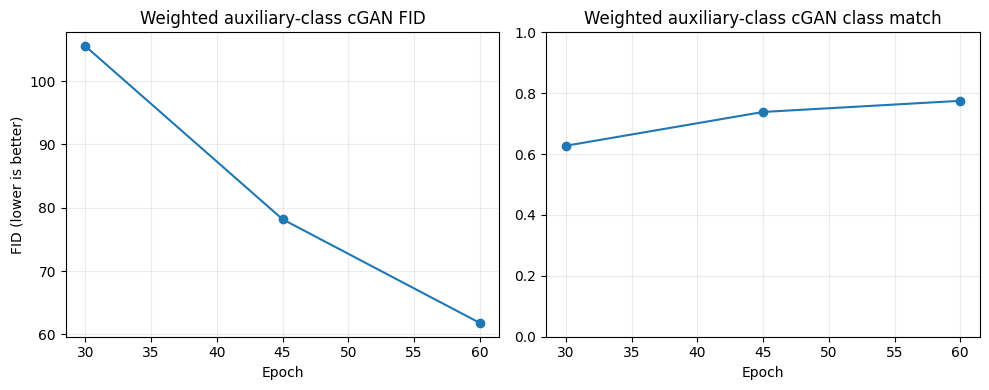

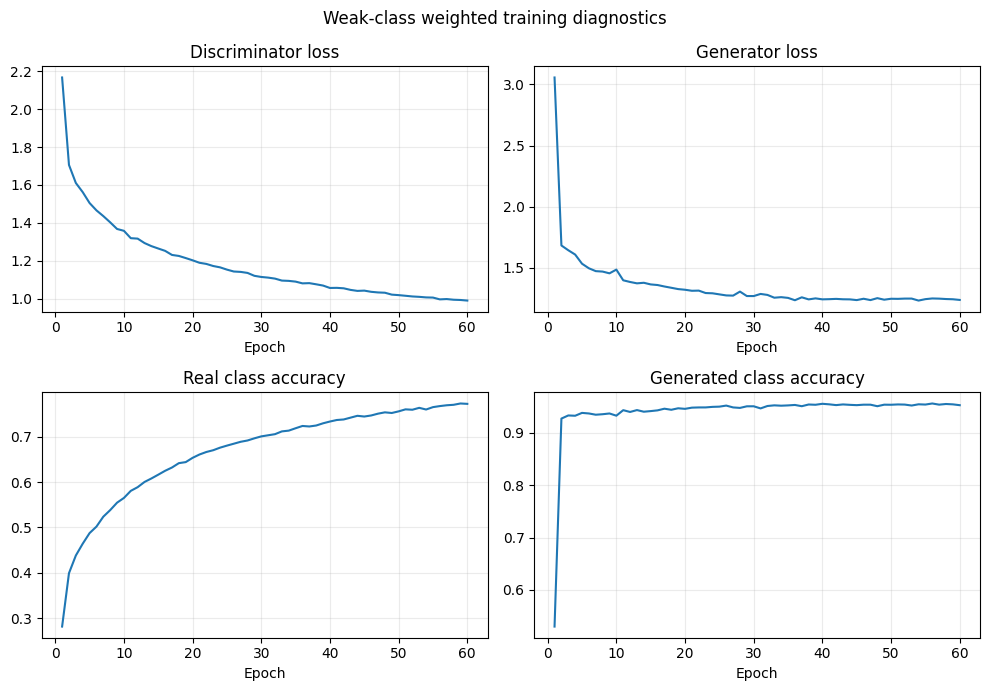

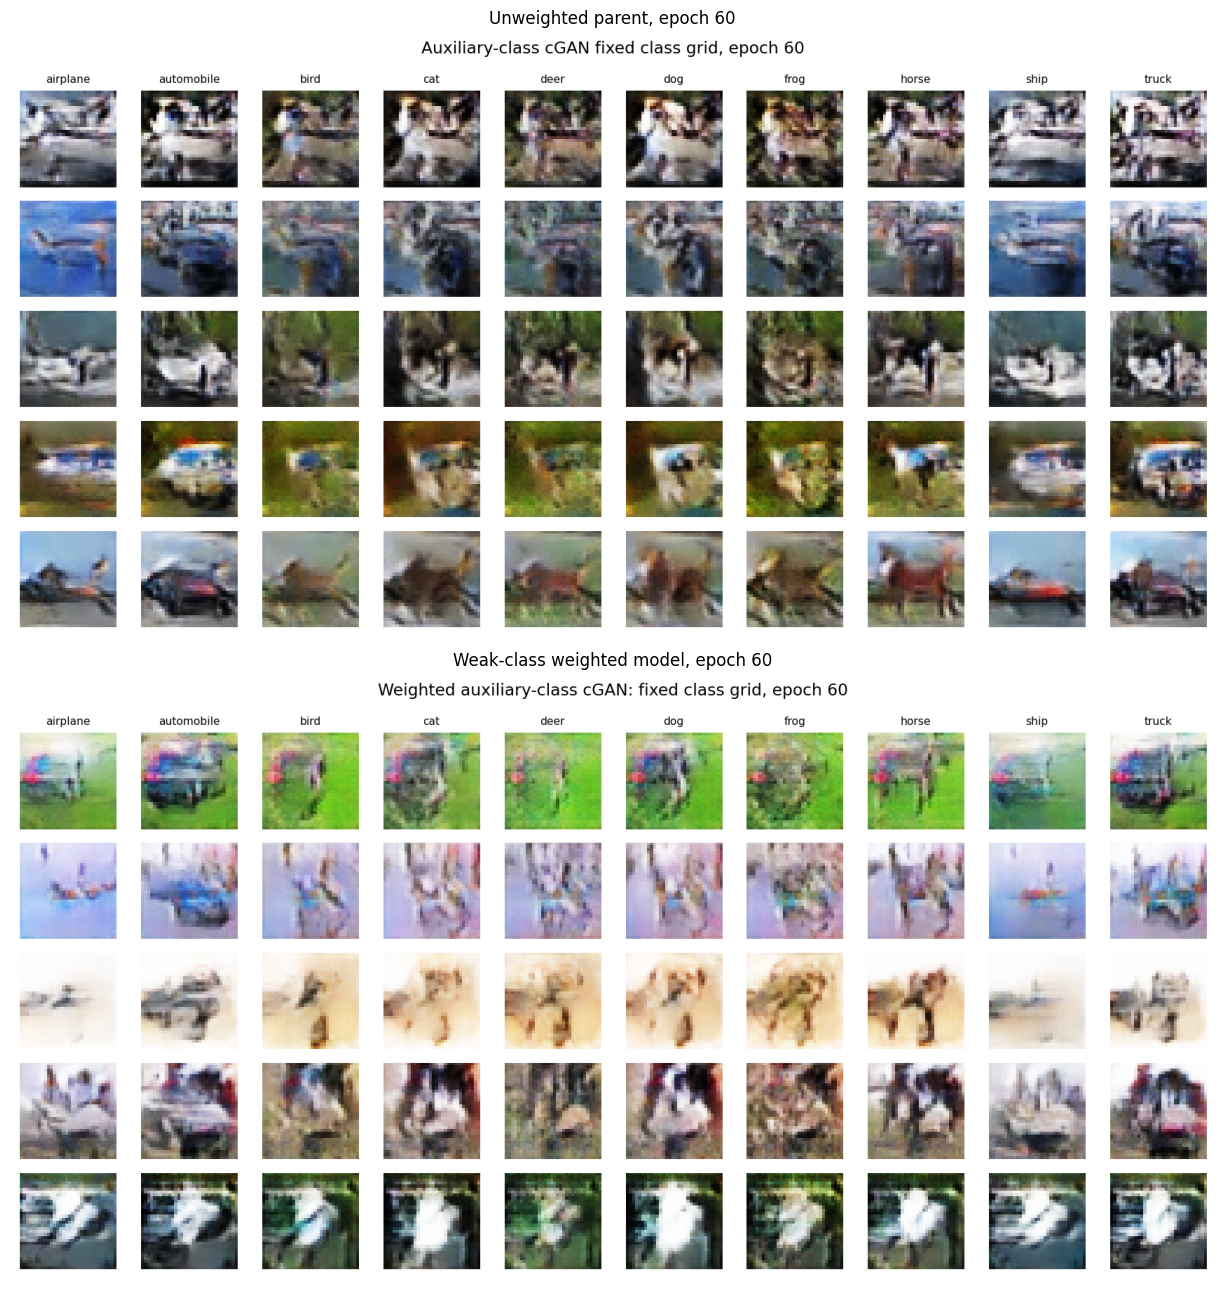

   epoch  validation_fid_5000  requested_class_match
0     30             105.5064                 0.6274
1     45              78.1800                 0.7384
2     60              61.8209                 0.7750

        class  parent_epoch_60_match  weighted_epoch_60_match  change
0    airplane                  0.940                    0.960   0.020
1  automobile                  0.676                    0.772   0.096
2        bird                  0.692                    0.620  -0.072
3         cat                  0.588                    0.630   0.042
4        deer                  0.686                    0.668  -0.018
5         dog                  0.752                    0.748  -0.004
6        frog                  0.884                    0.916   0.032
7       horse                  0.844                    0.870   0.026
8        ship                  0.744                    0.770   0.026
9       truck                  0.748                    0.796   0.048

In [53]:
weighted_final_row = weighted_checkpoint_table.set_index("epoch").loc[60]
weighted_summary = pd.DataFrame([{
    "experiment": "Weak-class weighted auxiliary-class cGAN",
    "epochs": WEIGHTED_EPOCHS,
    "generator_parameters": weighted_generator.count_params(),
    "discriminator_parameters": weighted_discriminator.count_params(),
    "total_parameters": (
        weighted_generator.count_params()
        + weighted_discriminator.count_params()
    ),
    "training_minutes": WEIGHTED_TRAINING_SECONDS / 60,
    "validation_fid_5000": weighted_final_row["validation_fid_5000"],
    "requested_class_match": weighted_final_row["requested_class_match"],
    "initial_reference_error": WEIGHTED_INITIAL_REFERENCE_ERROR,
}])
weighted_summary.to_csv(
    EXPERIMENT_TABLE_DIR / "weighted_auxiliary_cgan_summary.csv",
    index=False,
)

plot_checkpoint_metrics(
    weighted_checkpoint_table,
    "Weighted auxiliary-class cGAN",
)

plot_training_diagnostics(
    weighted_history,
    AUXILIARY_DIAGNOSTICS,
    "Weak-class weighted training diagnostics",
)

figure, axes = plt.subplots(2, 1, figsize=(14, 13))
comparison_grids = [
    (
        AUXILIARY_SAMPLE_DIR / "auxiliary_cgan_epoch_060.png",
        "Unweighted parent, epoch 60",
    ),
    (
        WEIGHTED_SAMPLE_DIR / "weighted_auxiliary_cgan_epoch_060.png",
        "Weak-class weighted model, epoch 60",
    ),
]
for axis, (path, title) in zip(axes, comparison_grids):
    axis.imshow(plt.imread(path))
    axis.set_title(title)
    axis.axis("off")
figure.tight_layout()
plt.show()

display(weighted_checkpoint_table.round(4))
display(weighted_class_comparison.round(4))


## 10.5 Seed-42 Decision

For seed 42, weighting improved both targets: cat rose from `58.8%` to `63.0%`, and automobile from `67.6%` to `77.2%`. FID also improved from `70.68` to `61.82`, while overall class match moved from `75.54%` to `77.50%`. The intervention therefore answers its narrow question positively in this run.

The change was not uniformly beneficial. Bird fell by `7.2` percentage points, deer by `1.8`, and dog by `0.4`. I keep the weighted model as a candidate and use the paired-seed stage to determine whether its aggregate gain and class trade-offs repeat under different initializations.


# 11. Paired-Seed Confirmation

Seed 42 is the primary run for every controlled comparison. I repeat the complete model sequence with seeds 1042 and 2042, giving each configuration three paired observations under the same data split and evaluation inputs.

The repeated runs use the same epochs and hyperparameters as the primary run. Their histories, final weights and fixed-input grids are saved, while their console output is compact to keep the notebook readable. Model claims use the three-seed mean, sample standard deviation and paired change. Seed 42 supplies the export checkpoint; the additional seeds test whether the conclusions repeat.

Seeds 42, 1042 and 2042 completed for every model.
The tables below use the same split and evaluation inputs.


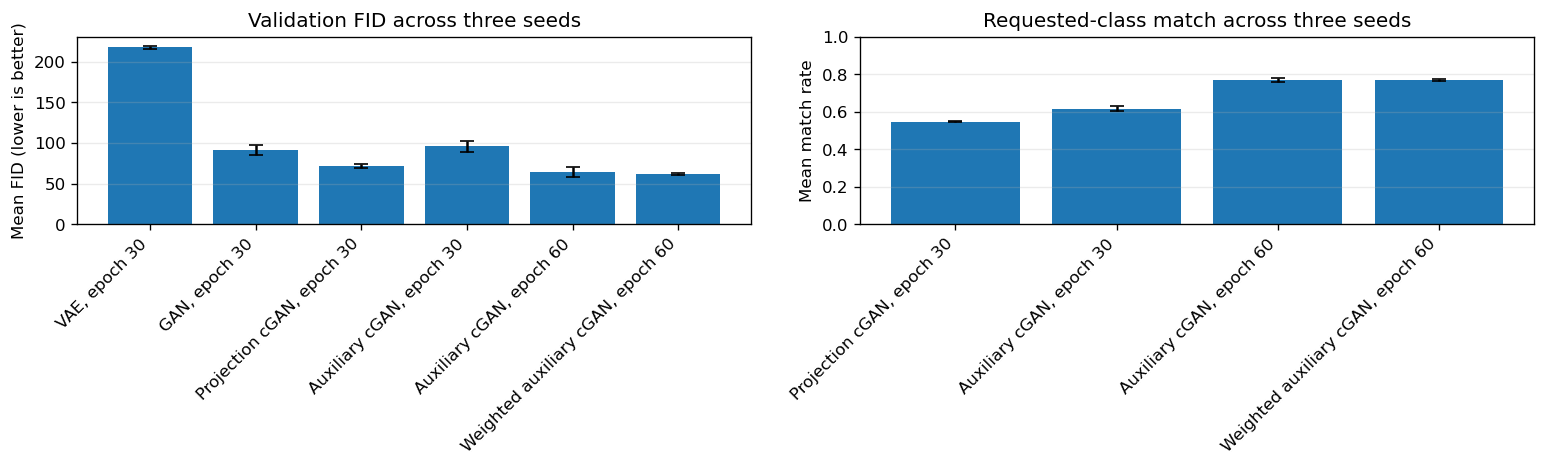

 seed                             model  validation_fid_5000  requested_class_match
   42                     VAE, epoch 30             219.2612                    NaN
   42                     GAN, epoch 30              85.6591                    NaN
   42         Projection cGAN, epoch 30              72.3630                 0.5492
   42          Auxiliary cGAN, epoch 30             101.5098                 0.6124
   42          Auxiliary cGAN, epoch 60              70.6841                 0.7554
   42 Weighted auxiliary cGAN, epoch 60              61.8209                 0.7750
 1042                     VAE, epoch 30             215.9223                    NaN
 1042                     GAN, epoch 30              97.4511                    NaN
 1042         Projection cGAN, epoch 30              73.1287                 0.5458
 1042          Auxiliary cGAN, epoch 30              88.0695                 0.6032
 1042          Auxiliary cGAN, epoch 60              61.6023                

                            model  fid_mean  fid_std  class_match_mean  class_match_std
                    VAE, epoch 30  217.9573   1.7854               NaN              NaN
                    GAN, epoch 30   90.8758   6.0123               NaN              NaN
        Projection cGAN, epoch 30   71.2602   2.6016            0.5464           0.0026
         Auxiliary cGAN, epoch 30   95.6430   6.8808            0.6149           0.0132
         Auxiliary cGAN, epoch 60   64.1290   5.7263            0.7690           0.0123
Weighted auxiliary cGAN, epoch 60   61.8633   0.8442            0.7693           0.0055

                       comparison  fid_improvement_mean  fid_improvement_std  fid_wins_out_of_3  class_match_change_mean  class_match_change_std  class_match_wins_out_of_3
                       VAE to GAN              127.0815               7.7789                  3                      NaN                     NaN                          0
           GAN to projection cGAN               19.6156               5.6873                  3                      NaN                     NaN                          0
Projection to auxiliary objective              -24.3828               8.1771                  0                   0.0685                  0.0146                          3
             Epoch 30 to epoch 60               31.5140               5.4238                  3                   0.1541                  0.0134                          3
             Weak-class weighting                2.2657               5.7143                  1                   0.0003                  0.

             selected_model  export_seed  selected_checkpoint_epoch  checkpoint_validation_fid_5000  checkpoint_requested_class_match                                                   selected_weight_path     weak_classes          target_class_wins  fid_wins_out_of_3  overall_class_wins_out_of_3  weighted_replaces_parent
0  Auxiliary cGAN, epoch 60           42                         55                         70.0676                             0.764  part_a_experiment_outputs\weights\auxiliary_cgan_epoch_055.weights.h5  cat, automobile  cat: 2/3; automobile: 2/3                  1                            1                     False

In [54]:
import gc

del baseline_vae, vae_encoder, vae_decoder
del baseline_gan, gan_generator, gan_discriminator
del conditional_gan, conditional_generator, conditional_discriminator
del auxiliary_cgan, auxiliary_generator, auxiliary_discriminator
del weighted_auxiliary_cgan, weighted_generator, weighted_discriminator
del parent_generator, initial_reference_generator
keras.backend.clear_session()
gc.collect()

EXPERIMENT_SEEDS = [SEED, SEED + 1000, SEED + 2000]
REPLICATION_ROOT = EXPERIMENT_OUTPUT_DIR / "paired_seed_runs"
REPLICATION_ROOT.mkdir(parents=True, exist_ok=True)


class ReplicationCheckpoint(keras.callbacks.Callback):
    def __init__(self, generator, paths_by_epoch):
        super().__init__()
        self.generator = generator
        self.paths_by_epoch = paths_by_epoch

    def on_epoch_end(self, epoch, logs=None):
        epoch_number = epoch + 1
        path = self.paths_by_epoch.get(epoch_number)
        if path is not None:
            self.generator.save_weights(path)


def create_replication_vae(seed):
    keras.utils.set_random_seed(seed)
    encoder = build_vae_encoder()
    decoder = build_vae_decoder()
    model = VAE(encoder, decoder, name=f"vae_seed_{seed}")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001)
    )
    return decoder, model


def create_replication_gan(seed):
    keras.utils.set_random_seed(seed)
    generator = build_gan_generator()
    discriminator = build_gan_discriminator()
    model = DCGAN(
        generator,
        discriminator,
        latent_dim=LATENT_DIM,
        name=f"gan_seed_{seed}",
    )
    model.compile(
        discriminator_optimizer=keras.optimizers.Adam(
            learning_rate=0.0002,
            beta_1=0.5,
        ),
        generator_optimizer=keras.optimizers.Adam(
            learning_rate=0.0002,
            beta_1=0.5,
        ),
        loss_fn=keras.losses.BinaryCrossentropy(from_logits=True),
    )
    return generator, model


def create_replication_cgan(seed):
    keras.utils.set_random_seed(seed)
    generator = build_conditional_generator()
    discriminator = build_conditioned_discriminator(
        model_name=f"conditional_discriminator_seed_{seed}"
    )
    model = ConditionalGAN(
        generator,
        discriminator,
        LATENT_DIM,
        name=f"conditional_gan_seed_{seed}",
    )
    model.compile(
        discriminator_optimizer=keras.optimizers.Adam(
            0.0002,
            beta_1=0.5,
        ),
        generator_optimizer=keras.optimizers.Adam(
            0.0002,
            beta_1=0.5,
        ),
        loss_fn=keras.losses.BinaryCrossentropy(from_logits=True),
    )
    return generator, model


def save_compact_history(history, path):
    table = pd.DataFrame(history.history)
    table.index = np.arange(1, len(table) + 1)
    table.index.name = "epoch"
    assert np.isfinite(table.to_numpy()).all()
    table.to_csv(path)


def unconditional_metrics(generator, output_range):
    images = images_for_display(
        generator.predict(fid_noise, batch_size=256, verbose=0),
        output_range,
    )
    features = extract_inception_features(images)
    return {
        "validation_fid_5000": calculate_fid(
            real_fid_features,
            features,
        ),
        "requested_class_match": np.nan,
    }


def conditional_metrics(generator):
    images = images_for_display(
        generator.predict(
            [fid_noise, conditional_fid_labels],
            batch_size=256,
            verbose=0,
        ),
        "tanh",
    )
    features = extract_inception_features(images)
    predictions = class_evaluator.predict(
        images,
        batch_size=256,
        verbose=0,
    ).argmax(axis=1)
    metrics = {
        "validation_fid_5000": calculate_fid(
            real_fid_features,
            features,
        ),
        "requested_class_match": float(np.mean(
            predictions == conditional_fid_label_ids
        )),
    }
    return metrics, predictions


def add_result(records, seed, model, metrics):
    records.append({
        "seed": seed,
        "model": model,
        **metrics,
    })


def add_class_results(records, seed, model, predictions):
    table = per_class_match(predictions)
    for row in table.to_dict(orient="records"):
        records.append({
            "seed": seed,
            "model": model,
            "class": row["class"],
            "requested_class_match": row["requested_class_match"],
        })


MODEL_VAE_30 = "VAE, epoch 30"
MODEL_GAN_30 = "GAN, epoch 30"
MODEL_CGAN_30 = "Projection cGAN, epoch 30"
MODEL_AUX_30 = "Auxiliary cGAN, epoch 30"
MODEL_AUX_60 = "Auxiliary cGAN, epoch 60"
MODEL_WEIGHTED_60 = "Weighted auxiliary cGAN, epoch 60"

primary_conditional_row = (
    conditional_checkpoint_evaluation.set_index("epoch").loc[30]
)
primary_auxiliary_30_row = (
    auxiliary_checkpoint_evaluation.set_index("epoch").loc[30]
)
primary_auxiliary_60_row = (
    duration_checkpoint_evaluation.set_index("epoch").loc[60]
)
primary_weighted_row = (
    weighted_checkpoint_table.set_index("epoch").loc[60]
)

paired_seed_records = []
paired_class_records = []
add_result(
    paired_seed_records,
    SEED,
    MODEL_VAE_30,
    {
        "validation_fid_5000": VAE_BASELINE_FID,
        "requested_class_match": np.nan,
    },
)
add_result(
    paired_seed_records,
    SEED,
    MODEL_GAN_30,
    {
        "validation_fid_5000": GAN_BASELINE_FID,
        "requested_class_match": np.nan,
    },
)
add_result(
    paired_seed_records,
    SEED,
    MODEL_CGAN_30,
    {
        "validation_fid_5000": primary_conditional_row[
            "validation_fid_5000"
        ],
        "requested_class_match": primary_conditional_row[
            "requested_class_match"
        ],
    },
)
add_result(
    paired_seed_records,
    SEED,
    MODEL_AUX_30,
    {
        "validation_fid_5000": primary_auxiliary_30_row[
            "validation_fid_5000"
        ],
        "requested_class_match": primary_auxiliary_30_row[
            "requested_class_match"
        ],
    },
)
add_result(
    paired_seed_records,
    SEED,
    MODEL_AUX_60,
    {
        "validation_fid_5000": primary_auxiliary_60_row[
            "validation_fid_5000"
        ],
        "requested_class_match": primary_auxiliary_60_row[
            "requested_class_match"
        ],
    },
)
add_result(
    paired_seed_records,
    SEED,
    MODEL_WEIGHTED_60,
    {
        "validation_fid_5000": primary_weighted_row[
            "validation_fid_5000"
        ],
        "requested_class_match": primary_weighted_row[
            "requested_class_match"
        ],
    },
)

add_class_results(
    paired_class_records,
    SEED,
    MODEL_CGAN_30,
    conditional_predictions[30],
)
add_class_results(
    paired_class_records,
    SEED,
    MODEL_AUX_30,
    auxiliary_predictions[30],
)
add_class_results(
    paired_class_records,
    SEED,
    MODEL_AUX_60,
    duration_predictions[60],
)
add_class_results(
    paired_class_records,
    SEED,
    MODEL_WEIGHTED_60,
    weighted_predictions[60],
)

for replication_seed in EXPERIMENT_SEEDS[1:]:
    seed_dir = REPLICATION_ROOT / f"seed_{replication_seed}"
    history_dir = seed_dir / "histories"
    sample_dir = seed_dir / "samples"
    weight_dir = seed_dir / "weights"
    for directory in (history_dir, sample_dir, weight_dir):
        directory.mkdir(parents=True, exist_ok=True)

    vae_decoder_rep, vae_rep = create_replication_vae(replication_seed)
    vae_history_rep = vae_rep.fit(
        x_train_vae,
        epochs=VAE_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        verbose=0,
    )
    save_compact_history(
        vae_history_rep,
        history_dir / "vae_history.csv",
    )
    vae_decoder_rep.save_weights(weight_dir / "vae_decoder.weights.h5")
    save_fixed_grid(
        vae_decoder_rep,
        BASELINE_FIXED_NOISE,
        "sigmoid",
        5,
        5,
        sample_dir / "vae_epoch_030.png",
        f"VAE seed {replication_seed}, epoch 30",
    )
    add_result(
        paired_seed_records,
        replication_seed,
        MODEL_VAE_30,
        unconditional_metrics(vae_decoder_rep, "sigmoid"),
    )
    print(f"Seed {replication_seed}: VAE complete")
    del vae_history_rep, vae_rep, vae_decoder_rep
    keras.backend.clear_session()
    gc.collect()

    gan_generator_rep, gan_rep = create_replication_gan(replication_seed)
    gan_dataset_rep = make_training_dataset(
        x_train_gan,
        seed=replication_seed,
    )
    gan_history_rep = gan_rep.fit(
        gan_dataset_rep,
        epochs=GAN_EPOCHS,
        verbose=0,
    )
    save_compact_history(
        gan_history_rep,
        history_dir / "gan_history.csv",
    )
    gan_generator_rep.save_weights(
        weight_dir / "gan_generator.weights.h5"
    )
    save_fixed_grid(
        gan_generator_rep,
        BASELINE_FIXED_NOISE,
        "tanh",
        5,
        5,
        sample_dir / "gan_epoch_030.png",
        f"GAN seed {replication_seed}, epoch 30",
    )
    add_result(
        paired_seed_records,
        replication_seed,
        MODEL_GAN_30,
        unconditional_metrics(gan_generator_rep, "tanh"),
    )
    print(f"Seed {replication_seed}: GAN complete")
    del gan_history_rep, gan_rep, gan_dataset_rep, gan_generator_rep
    keras.backend.clear_session()
    gc.collect()

    cgan_generator_rep, cgan_rep = create_replication_cgan(
        replication_seed
    )
    cgan_dataset_rep = make_training_dataset(
        x_train_gan,
        y_model_train,
        seed=replication_seed,
    )
    keras.utils.set_random_seed(replication_seed)
    cgan_history_rep = cgan_rep.fit(
        cgan_dataset_rep,
        epochs=CONDITIONAL_EPOCHS,
        verbose=0,
    )
    save_compact_history(
        cgan_history_rep,
        history_dir / "projection_cgan_history.csv",
    )
    cgan_generator_rep.save_weights(
        weight_dir / "projection_cgan_generator.weights.h5"
    )
    save_fixed_grid(
        cgan_generator_rep,
        CONDITIONAL_FIXED_INPUTS,
        "tanh",
        5,
        10,
        sample_dir / "projection_cgan_epoch_030.png",
        f"Projection cGAN seed {replication_seed}, epoch 30",
    )
    cgan_metrics_rep, cgan_predictions_rep = conditional_metrics(
        cgan_generator_rep
    )
    add_result(
        paired_seed_records,
        replication_seed,
        MODEL_CGAN_30,
        cgan_metrics_rep,
    )
    add_class_results(
        paired_class_records,
        replication_seed,
        MODEL_CGAN_30,
        cgan_predictions_rep,
    )
    print(f"Seed {replication_seed}: projection cGAN complete")
    del cgan_history_rep, cgan_rep, cgan_dataset_rep
    del cgan_generator_rep, cgan_metrics_rep, cgan_predictions_rep
    keras.backend.clear_session()
    gc.collect()

    (
        auxiliary_generator_rep,
        _,
        auxiliary_rep,
    ) = create_auxiliary_cgan(
        f"auxiliary_cgan_seed_{replication_seed}",
        standard_class_loss,
        seed=replication_seed,
    )
    auxiliary_dataset_rep = make_training_dataset(
        x_train_gan,
        y_model_train,
        seed=replication_seed,
    )
    auxiliary_30_path = (
        weight_dir / "auxiliary_cgan_epoch_030.weights.h5"
    )
    auxiliary_callback_rep = ReplicationCheckpoint(
        auxiliary_generator_rep,
        {30: auxiliary_30_path},
    )
    keras.utils.set_random_seed(replication_seed)
    auxiliary_history_rep = auxiliary_rep.fit(
        auxiliary_dataset_rep,
        epochs=AUXILIARY_EPOCHS,
        callbacks=[auxiliary_callback_rep],
        verbose=0,
    )
    save_compact_history(
        auxiliary_history_rep,
        history_dir / "auxiliary_cgan_history.csv",
    )
    auxiliary_generator_rep.save_weights(
        weight_dir / "auxiliary_cgan_epoch_060.weights.h5"
    )

    auxiliary_30_generator_rep = build_conditional_generator()
    auxiliary_30_generator_rep.load_weights(auxiliary_30_path)
    auxiliary_30_metrics_rep, auxiliary_30_predictions_rep = (
        conditional_metrics(auxiliary_30_generator_rep)
    )
    auxiliary_60_metrics_rep, auxiliary_60_predictions_rep = (
        conditional_metrics(auxiliary_generator_rep)
    )
    add_result(
        paired_seed_records,
        replication_seed,
        MODEL_AUX_30,
        auxiliary_30_metrics_rep,
    )
    add_result(
        paired_seed_records,
        replication_seed,
        MODEL_AUX_60,
        auxiliary_60_metrics_rep,
    )
    add_class_results(
        paired_class_records,
        replication_seed,
        MODEL_AUX_30,
        auxiliary_30_predictions_rep,
    )
    add_class_results(
        paired_class_records,
        replication_seed,
        MODEL_AUX_60,
        auxiliary_60_predictions_rep,
    )
    save_fixed_grid(
        auxiliary_generator_rep,
        CONDITIONAL_FIXED_INPUTS,
        "tanh",
        5,
        10,
        sample_dir / "auxiliary_cgan_epoch_060.png",
        f"Auxiliary cGAN seed {replication_seed}, epoch 60",
    )
    print(f"Seed {replication_seed}: auxiliary cGAN complete")
    del auxiliary_history_rep, auxiliary_rep, auxiliary_dataset_rep
    del auxiliary_generator_rep, auxiliary_30_generator_rep
    del auxiliary_30_metrics_rep, auxiliary_30_predictions_rep
    del auxiliary_60_metrics_rep, auxiliary_60_predictions_rep, _
    keras.backend.clear_session()
    gc.collect()

    (
        weighted_generator_rep,
        _,
        weighted_rep,
    ) = create_auxiliary_cgan(
        f"weighted_cgan_seed_{replication_seed}",
        weak_class_weighted_loss,
        seed=replication_seed,
    )
    weighted_dataset_rep = make_training_dataset(
        x_train_gan,
        y_model_train,
        seed=replication_seed,
    )
    keras.utils.set_random_seed(replication_seed)
    weighted_history_rep = weighted_rep.fit(
        weighted_dataset_rep,
        epochs=WEIGHTED_EPOCHS,
        verbose=0,
    )
    save_compact_history(
        weighted_history_rep,
        history_dir / "weighted_cgan_history.csv",
    )
    weighted_generator_rep.save_weights(
        weight_dir / "weighted_cgan_epoch_060.weights.h5"
    )
    weighted_metrics_rep, weighted_predictions_rep = (
        conditional_metrics(weighted_generator_rep)
    )
    add_result(
        paired_seed_records,
        replication_seed,
        MODEL_WEIGHTED_60,
        weighted_metrics_rep,
    )
    add_class_results(
        paired_class_records,
        replication_seed,
        MODEL_WEIGHTED_60,
        weighted_predictions_rep,
    )
    save_fixed_grid(
        weighted_generator_rep,
        CONDITIONAL_FIXED_INPUTS,
        "tanh",
        5,
        10,
        sample_dir / "weighted_cgan_epoch_060.png",
        f"Weighted cGAN seed {replication_seed}, epoch 60",
    )
    print(f"Seed {replication_seed}: weighted cGAN complete")
    del weighted_history_rep, weighted_rep, weighted_dataset_rep
    del weighted_generator_rep, weighted_metrics_rep
    del weighted_predictions_rep, _
    keras.backend.clear_session()
    gc.collect()

paired_seed_results = pd.DataFrame(paired_seed_records)
paired_seed_results.to_csv(
    EXPERIMENT_TABLE_DIR / "paired_seed_model_results.csv",
    index=False,
)
paired_class_results = pd.DataFrame(paired_class_records)
paired_class_results.to_csv(
    EXPERIMENT_TABLE_DIR / "paired_seed_class_results.csv",
    index=False,
)

paired_seed_summary = (
    paired_seed_results.groupby("model", sort=False)
    .agg(
        fid_mean=("validation_fid_5000", "mean"),
        fid_std=("validation_fid_5000", "std"),
        class_match_mean=("requested_class_match", "mean"),
        class_match_std=("requested_class_match", "std"),
    )
    .reset_index()
)
paired_seed_summary.to_csv(
    EXPERIMENT_TABLE_DIR / "paired_seed_model_summary.csv",
    index=False,
)

paired_class_summary = (
    paired_class_results.groupby(["model", "class"], sort=False)
    .agg(
        class_match_mean=("requested_class_match", "mean"),
        class_match_std=("requested_class_match", "std"),
    )
    .reset_index()
)
paired_class_summary.to_csv(
    EXPERIMENT_TABLE_DIR / "paired_seed_class_summary.csv",
    index=False,
)

result_by_seed = paired_seed_results.pivot(
    index="seed",
    columns="model",
)
paired_comparisons = [
    (MODEL_VAE_30, MODEL_GAN_30, "VAE to GAN"),
    (MODEL_GAN_30, MODEL_CGAN_30, "GAN to projection cGAN"),
    (MODEL_CGAN_30, MODEL_AUX_30, "Projection to auxiliary objective"),
    (MODEL_AUX_30, MODEL_AUX_60, "Epoch 30 to epoch 60"),
    (MODEL_AUX_60, MODEL_WEIGHTED_60, "Weak-class weighting"),
]
paired_change_records = []
for parent, candidate, comparison in paired_comparisons:
    fid_change = (
        result_by_seed["validation_fid_5000"][parent]
        - result_by_seed["validation_fid_5000"][candidate]
    )
    parent_class = result_by_seed["requested_class_match"][parent]
    candidate_class = result_by_seed["requested_class_match"][candidate]
    class_change = candidate_class - parent_class
    paired_change_records.append({
        "comparison": comparison,
        "fid_improvement_mean": fid_change.mean(),
        "fid_improvement_std": fid_change.std(),
        "fid_wins_out_of_3": int((fid_change > 0).sum()),
        "class_match_change_mean": class_change.mean(),
        "class_match_change_std": class_change.std(),
        "class_match_wins_out_of_3": int((class_change > 0).sum()),
    })

paired_change_summary = pd.DataFrame(paired_change_records)
paired_change_summary.to_csv(
    EXPERIMENT_TABLE_DIR / "paired_seed_changes.csv",
    index=False,
)

summary_by_model = paired_seed_summary.set_index("model")
auxiliary_fid_change = (
    result_by_seed["validation_fid_5000"][MODEL_CGAN_30]
    - result_by_seed["validation_fid_5000"][MODEL_AUX_60]
)
auxiliary_class_change = (
    result_by_seed["requested_class_match"][MODEL_AUX_60]
    - result_by_seed["requested_class_match"][MODEL_CGAN_30]
)
auxiliary_replaces_projection = (
    summary_by_model.loc[MODEL_AUX_60, "fid_mean"]
    < summary_by_model.loc[MODEL_CGAN_30, "fid_mean"]
    and summary_by_model.loc[MODEL_AUX_60, "class_match_mean"]
    >= summary_by_model.loc[MODEL_CGAN_30, "class_match_mean"]
    and int((auxiliary_fid_change > 0).sum()) >= 2
    and int((auxiliary_class_change > 0).sum()) >= 2
)

class_summary_index = paired_class_summary.set_index(["model", "class"])
target_class_improvements = [
    class_summary_index.loc[
        (MODEL_WEIGHTED_60, class_name),
        "class_match_mean",
    ]
    - class_summary_index.loc[
        (MODEL_AUX_60, class_name),
        "class_match_mean",
    ]
    for class_name in WEAK_CLASS_NAMES
]
weighted_fid_change = (
    result_by_seed["validation_fid_5000"][MODEL_AUX_60]
    - result_by_seed["validation_fid_5000"][MODEL_WEIGHTED_60]
)
weighted_class_change = (
    result_by_seed["requested_class_match"][MODEL_WEIGHTED_60]
    - result_by_seed["requested_class_match"][MODEL_AUX_60]
)
weighted_replaces_parent = (
    all(change > 0 for change in target_class_improvements)
    and summary_by_model.loc[MODEL_WEIGHTED_60, "fid_mean"]
    < summary_by_model.loc[MODEL_AUX_60, "fid_mean"]
    and summary_by_model.loc[MODEL_WEIGHTED_60, "class_match_mean"]
    >= summary_by_model.loc[MODEL_AUX_60, "class_match_mean"]
    and int((weighted_fid_change > 0).sum()) >= 2
    and int((weighted_class_change > 0).sum()) >= 2
)

if not auxiliary_replaces_projection:
    SELECTED_MODEL_NAME = MODEL_CGAN_30
    selected_checkpoint_table = conditional_checkpoint_evaluation
    selected_checkpoint_prefix = "conditional_gan"
    family_reference_match = primary_conditional_row[
        "requested_class_match"
    ]
elif weighted_replaces_parent:
    SELECTED_MODEL_NAME = MODEL_WEIGHTED_60
    selected_checkpoint_table = weighted_checkpoint_table
    selected_checkpoint_prefix = "weighted_auxiliary_cgan"
    family_reference_match = primary_weighted_row[
        "requested_class_match"
    ]
else:
    SELECTED_MODEL_NAME = MODEL_AUX_60
    selected_checkpoint_table = duration_checkpoint_evaluation
    selected_checkpoint_prefix = "auxiliary_cgan"
    family_reference_match = primary_auxiliary_60_row[
        "requested_class_match"
    ]

eligible_checkpoints = selected_checkpoint_table.loc[
    selected_checkpoint_table["requested_class_match"]
    >= family_reference_match
]
selected_checkpoint_row = eligible_checkpoints.loc[
    eligible_checkpoints["validation_fid_5000"].idxmin()
]
SELECTED_CHECKPOINT_EPOCH = int(selected_checkpoint_row["epoch"])
SELECTED_GENERATOR_WEIGHT_PATH = EXPERIMENT_WEIGHT_DIR / (
    f"{selected_checkpoint_prefix}_epoch_"
    f"{SELECTED_CHECKPOINT_EPOCH:03d}.weights.h5"
)
assert SELECTED_GENERATOR_WEIGHT_PATH.exists()

target_class_win_text = []
for class_name in WEAK_CLASS_NAMES:
    class_pivot = paired_class_results.loc[
        paired_class_results["class"] == class_name
    ].pivot(
        index="seed",
        columns="model",
        values="requested_class_match",
    )
    wins = int((
        class_pivot[MODEL_WEIGHTED_60]
        > class_pivot[MODEL_AUX_60]
    ).sum())
    target_class_win_text.append(f"{class_name}: {wins}/3")

selection_table = pd.DataFrame([{
    "selected_model": SELECTED_MODEL_NAME,
    "export_seed": SEED,
    "selected_checkpoint_epoch": SELECTED_CHECKPOINT_EPOCH,
    "checkpoint_validation_fid_5000": selected_checkpoint_row[
        "validation_fid_5000"
    ],
    "checkpoint_requested_class_match": selected_checkpoint_row[
        "requested_class_match"
    ],
    "selected_weight_path": str(SELECTED_GENERATOR_WEIGHT_PATH),
    "weak_classes": ", ".join(WEAK_CLASS_NAMES),
    "target_class_wins": "; ".join(target_class_win_text),
    "fid_wins_out_of_3": int((weighted_fid_change > 0).sum()),
    "overall_class_wins_out_of_3": int(
        (weighted_class_change > 0).sum()
    ),
    "weighted_replaces_parent": weighted_replaces_parent,
}])
selection_table.to_csv(
    EXPERIMENT_TABLE_DIR / "paired_seed_selection.csv",
    index=False,
)
with open(
    EXPERIMENT_TABLE_DIR / "paired_seed_selection.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(selection_table.iloc[0].to_dict(), file, indent=2)

figure, axes = plt.subplots(1, 2, figsize=(13, 4))
positions = np.arange(len(paired_seed_summary))
axes[0].bar(
    positions,
    paired_seed_summary["fid_mean"],
    yerr=paired_seed_summary["fid_std"],
    capsize=4,
)
axes[0].set_title("Validation FID across three seeds")
axes[0].set_ylabel("Mean FID (lower is better)")
axes[0].set_xticks(
    positions,
    paired_seed_summary["model"],
    rotation=45,
    ha="right",
)
axes[0].grid(axis="y", alpha=0.25)

conditional_summary = paired_seed_summary.dropna(
    subset=["class_match_mean"]
).reset_index(drop=True)
class_positions = np.arange(len(conditional_summary))
axes[1].bar(
    class_positions,
    conditional_summary["class_match_mean"],
    yerr=conditional_summary["class_match_std"],
    capsize=4,
)
axes[1].set_title("Requested-class match across three seeds")
axes[1].set_ylabel("Mean match rate")
axes[1].set_ylim(0, 1)
axes[1].set_xticks(
    class_positions,
    conditional_summary["model"],
    rotation=45,
    ha="right",
)
axes[1].grid(axis="y", alpha=0.25)
figure.tight_layout()
plt.show()

display(paired_seed_results.round(4))
display(paired_seed_summary.round(4))
display(paired_change_summary.round(4))
display(selection_table)

## 11.1 Results Across Three Seeds

The three-seed results separate the repeatable changes from the seed-specific ones:

- The GAN improved on the VAE in all three pairs; mean FID fell from `217.96` to `90.88`.
- Projection conditioning improved on the GAN in all three pairs; mean FID fell to `71.26`, with a stable `54.64%` mean class match.
- At epoch 30, the auxiliary objective raised mean class match to `61.49%` but worsened FID to `95.64`, exposing a semantic-control versus distribution-quality trade-off.
- Extending the same auxiliary model to epoch 60 improved both measures in every seed. Mean FID reached `64.13` and mean class match `76.90%`.
- Weighting lowered mean FID to `61.86`, but beat the unweighted parent on FID and overall class match in only `1 of 3` paired runs. Cat and automobile improved on average, but the complete intervention was not repeatable.

I therefore select the **unweighted auxiliary cGAN family**. Seed `42` was fixed as the primary run before training. Within that run, epoch `55` is better than epoch `60` on both validation measures: FID is `70.07` rather than `70.68`, and class match is `76.40%` rather than `75.54%`. I select the saved epoch-55 checkpoint for final export. Test images had previously been used only for dataset integrity checks; no test-set model metric informed this selection.


# 12. Final Evaluation

## 12.1 Final Evaluation Design and 1,000-Image Export

Model selection ended after the Section 11 decision. I then calculated model-performance measures on the official test partition for the first time: final FID and evaluator reliability. The architecture, checkpoint and training settings were not changed afterwards. The export contains 1,000 unfiltered images, balanced at 100 per requested class.

For the visual inspection, 100 images were shuffled and shown without labels. Duplicate checks, feature-diversity analysis and latent interpolation answer separate questions and are not substitutes for recognisability.


In [55]:
from PIL import Image

assert SELECTED_GENERATOR_WEIGHT_PATH.exists()

FINAL_EXPORT_SEED = SEED + 1400
FINAL_IMAGES_PER_CLASS = 100
FINAL_IMAGE_COUNT = NUMBER_OF_CLASSES * FINAL_IMAGES_PER_CLASS
FINAL_OUTPUT_DIR = Path("part_a_final_outputs")
FINAL_IMAGE_DIR = FINAL_OUTPUT_DIR / "generated_images"
FINAL_TABLE_DIR = FINAL_OUTPUT_DIR / "tables"
FINAL_FIGURE_DIR = FINAL_OUTPUT_DIR / "figures"
for directory in [FINAL_IMAGE_DIR, FINAL_TABLE_DIR, FINAL_FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
for stale_image in FINAL_IMAGE_DIR.glob("*.png"):
    stale_image.unlink()

final_generator = build_conditional_generator()
final_generator.load_weights(SELECTED_GENERATOR_WEIGHT_PATH)


def balanced_sample_indices(labels, samples_per_class, rng):
    indices = np.concatenate([
        rng.choice(
            np.flatnonzero(labels == class_id),
            size=samples_per_class,
            replace=False,
        )
        for class_id in range(NUMBER_OF_CLASSES)
    ])
    rng.shuffle(indices)
    return indices


In [56]:
x_test_final = x_test.astype("float32") / 255.0
evaluator_y_test = keras.utils.to_categorical(
    y_test,
    NUMBER_OF_CLASSES,
).astype("float32")
final_evaluator_test = class_evaluator.evaluate(
    x_test_final,
    evaluator_y_test,
    batch_size=EVALUATOR_BATCH_SIZE,
    return_dict=True,
    verbose=0,
)
final_test_evaluator_predictions = class_evaluator.predict(
    x_test_final,
    batch_size=EVALUATOR_BATCH_SIZE,
    verbose=0,
).argmax(axis=1)
final_test_evaluator_per_class = pd.DataFrame([
    {
        "class": class_name,
        "test_count": int(np.sum(y_test == class_id)),
        "recall": float(np.mean(
            final_test_evaluator_predictions[y_test == class_id]
            == class_id
        )),
    }
    for class_id, class_name in enumerate(class_names)
])

final_test_rng = np.random.default_rng(FINAL_EXPORT_SEED - 1)
final_test_real_indices = balanced_sample_indices(
    y_test,
    FID_IMAGES_PER_CLASS,
    final_test_rng,
)
final_test_real_images = x_test_final[final_test_real_indices]
final_test_noise = final_test_rng.normal(
    size=(FID_SAMPLE_COUNT, LATENT_DIM)
).astype("float32")
final_test_label_ids = np.repeat(
    np.arange(NUMBER_OF_CLASSES),
    FID_IMAGES_PER_CLASS,
).astype("int32")
final_test_labels = keras.utils.to_categorical(
    final_test_label_ids,
    NUMBER_OF_CLASSES,
).astype("float32")
final_test_generated_images = images_for_display(
    final_generator.predict(
        [final_test_noise, final_test_labels],
        batch_size=256,
        verbose=0,
    ),
    "tanh",
)
final_test_real_features = extract_inception_features(
    final_test_real_images
)
final_test_generated_features = extract_inception_features(
    final_test_generated_images
)
FINAL_TEST_FID = calculate_fid(
    final_test_real_features,
    final_test_generated_features,
)

final_test_summary = pd.DataFrame([{
    "official_test_fid_5000": FINAL_TEST_FID,
    "evaluator_official_test_accuracy": final_evaluator_test["accuracy"],
}])
final_test_summary.to_csv(
    FINAL_TABLE_DIR / "final_official_test_summary.csv",
    index=False,
)
final_test_evaluator_per_class.to_csv(
    FINAL_TABLE_DIR / "final_evaluator_test_per_class.csv",
    index=False,
)


In [57]:
final_rng = np.random.default_rng(FINAL_EXPORT_SEED)
final_noise = final_rng.normal(
    size=(FINAL_IMAGE_COUNT, LATENT_DIM)
).astype("float32")
final_label_ids = np.repeat(
    np.arange(NUMBER_OF_CLASSES),
    FINAL_IMAGES_PER_CLASS,
).astype("int32")
final_labels = keras.utils.to_categorical(
    final_label_ids,
    NUMBER_OF_CLASSES,
).astype("float32")
final_images = final_generator.predict(
    [final_noise, final_labels],
    batch_size=128,
    verbose=0,
)
final_images_01 = images_for_display(final_images, "tanh")
final_images_uint8 = np.rint(final_images_01 * 255.0).astype("uint8")

manifest_records = []
for index, (image, class_id) in enumerate(zip(
    final_images_uint8,
    final_label_ids,
)):
    within_class_index = index % FINAL_IMAGES_PER_CLASS
    filename = (
        f"{class_id:02d}_{class_names[class_id]}_"
        f"{within_class_index:03d}.png"
    )
    path = FINAL_IMAGE_DIR / filename
    Image.fromarray(image).save(path)
    manifest_records.append({
        "export_index": index,
        "filename": filename,
        "requested_class_id": class_id,
        "requested_class": class_names[class_id],
    })

final_manifest = pd.DataFrame(manifest_records)
final_manifest.to_csv(
    FINAL_TABLE_DIR / "final_image_manifest.csv",
    index=False,
)
exported_files = sorted(FINAL_IMAGE_DIR.glob("*.png"))
exported_counts = (
    final_manifest.groupby("requested_class")
    .size()
    .reindex(class_names)
)
assert len(exported_files) == FINAL_IMAGE_COUNT
assert (exported_counts.to_numpy() == FINAL_IMAGES_PER_CLASS).all()
for path in exported_files:
    with Image.open(path) as image:
        assert image.size == (32, 32)
        assert image.mode == "RGB"
        image.verify()


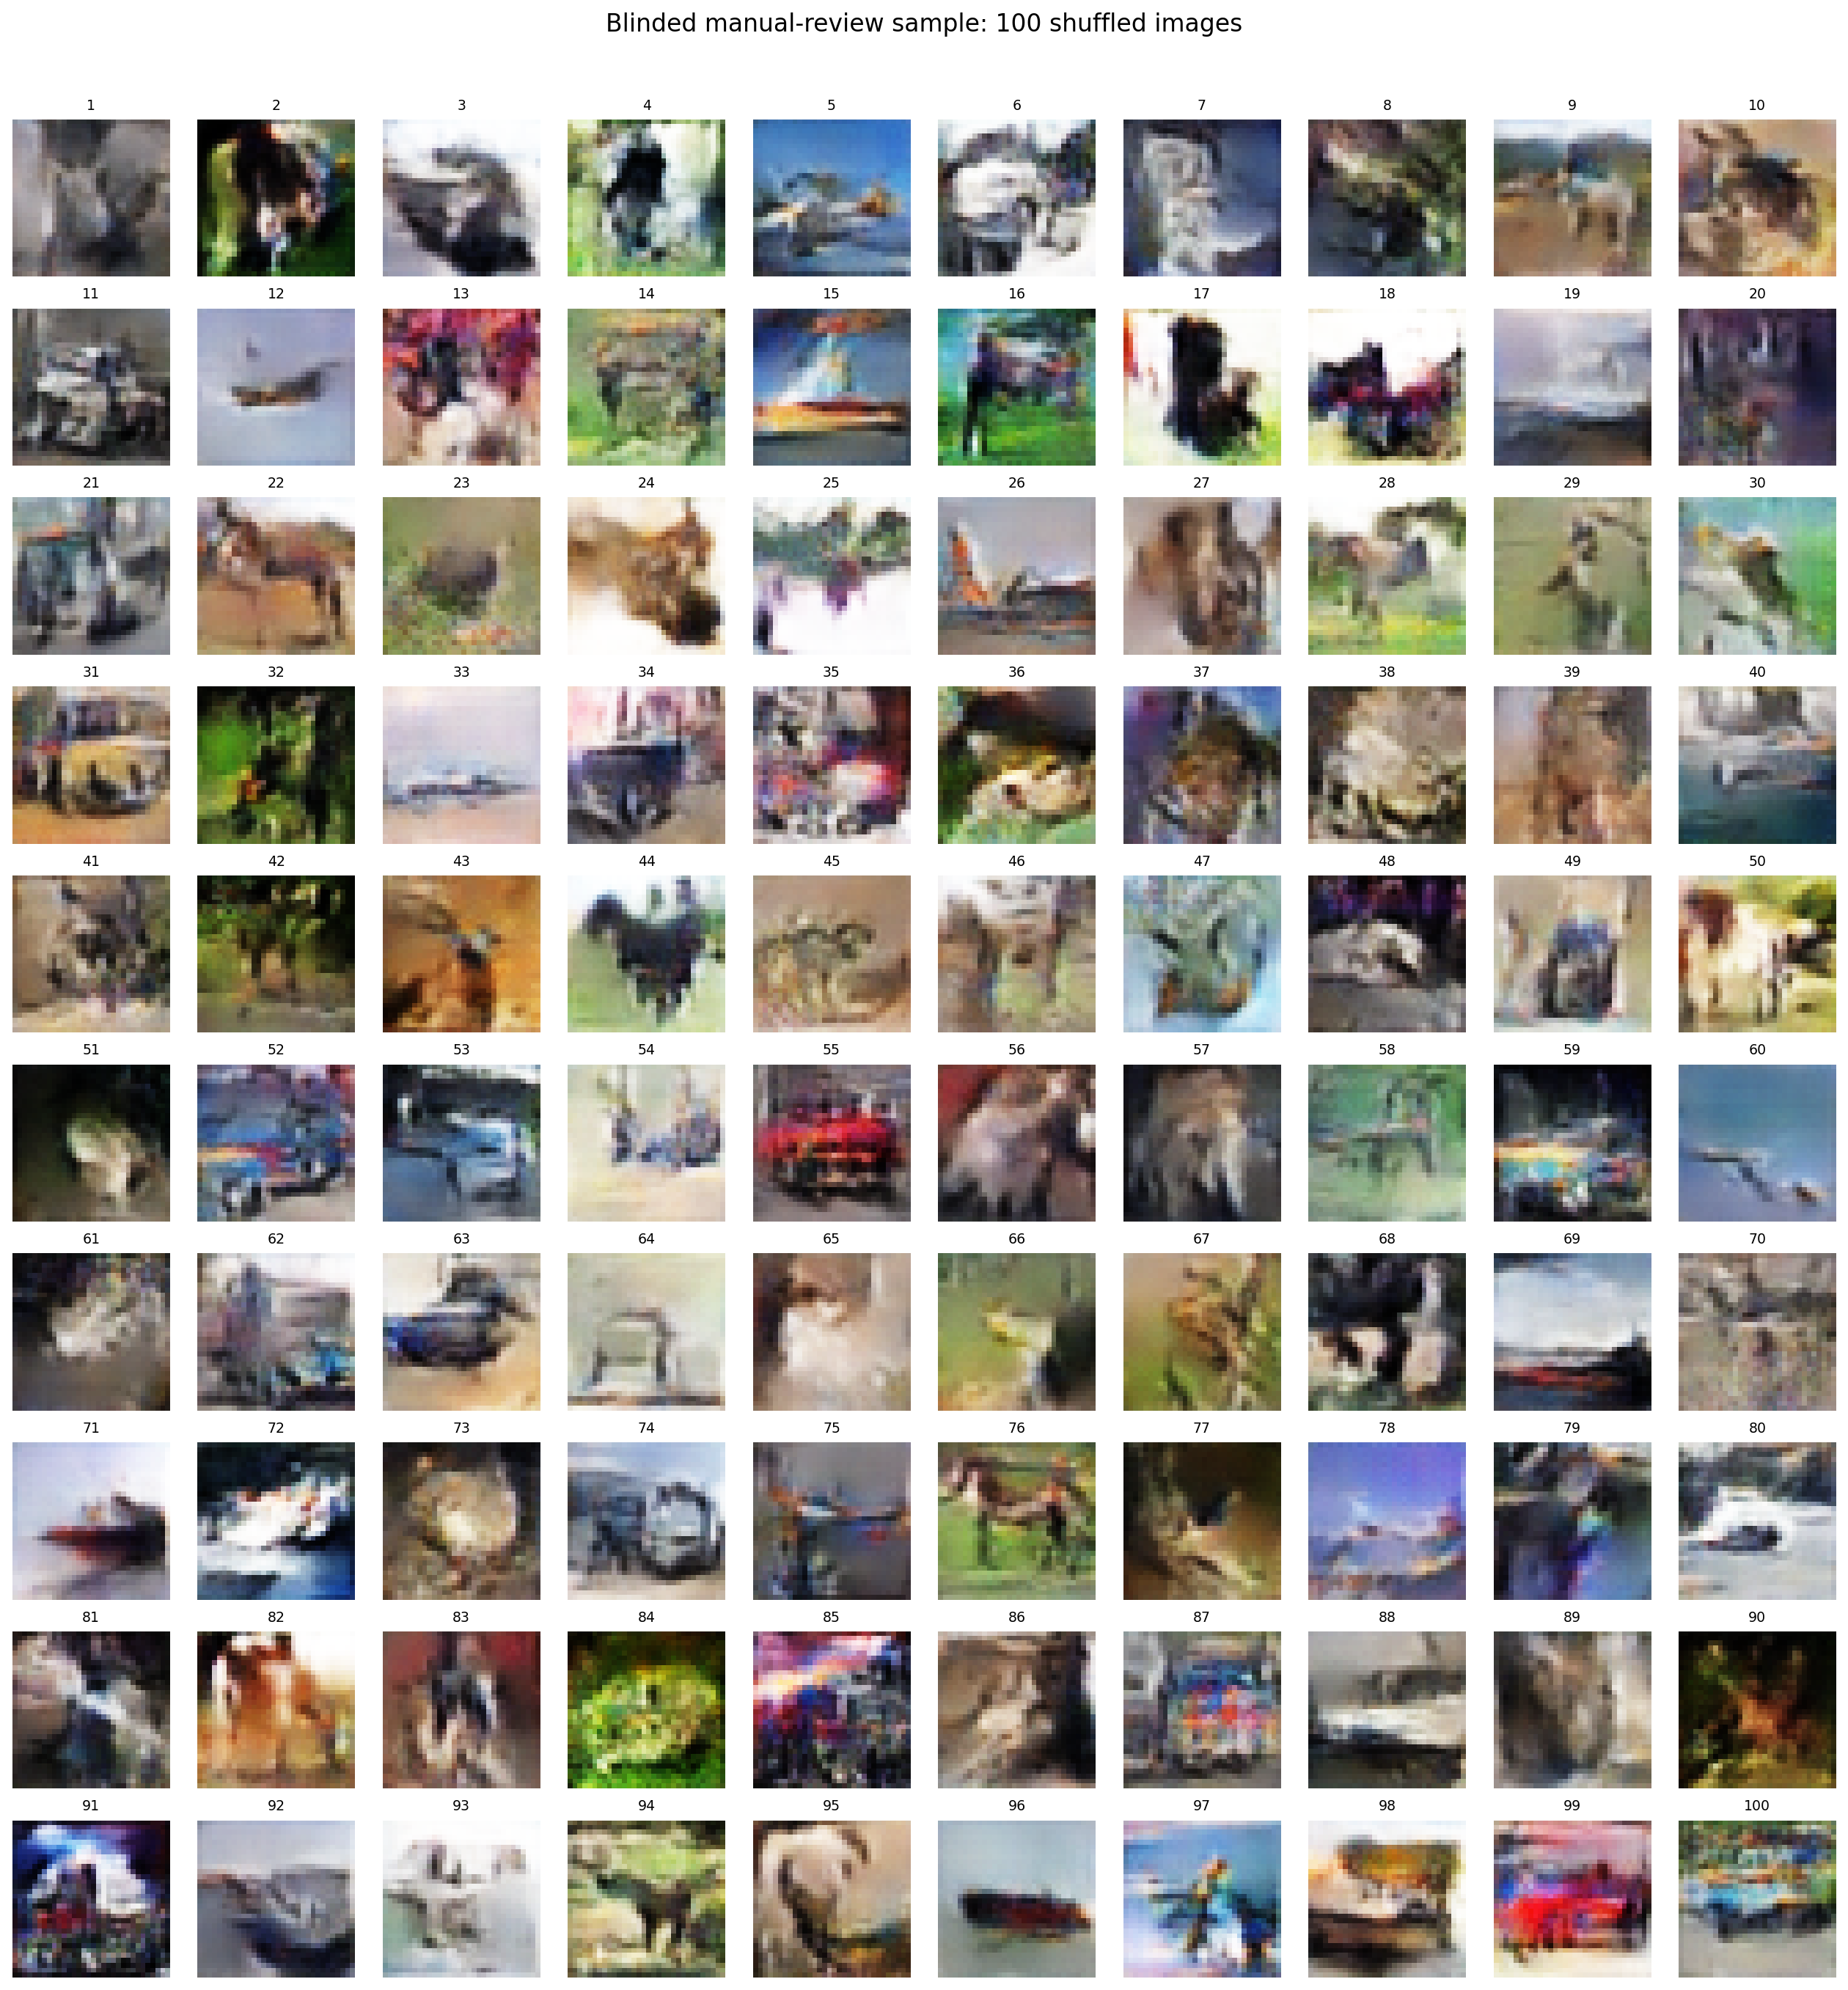

In [58]:
final_probabilities = class_evaluator.predict(
    final_images_01,
    batch_size=128,
    verbose=0,
)
final_predictions = final_probabilities.argmax(axis=1)
final_prediction_confidence = final_probabilities.max(axis=1)
final_class_table = pd.DataFrame([
    {
        "class": class_name,
        "exported_images": int(np.sum(final_label_ids == class_id)),
        "requested_class_match": float(np.mean(
            final_predictions[final_label_ids == class_id] == class_id
        )),
        "mean_prediction_confidence": float(np.mean(
            final_prediction_confidence[final_label_ids == class_id]
        )),
    }
    for class_id, class_name in enumerate(class_names)
])
final_class_table.to_csv(
    FINAL_TABLE_DIR / "final_export_class_evaluation.csv",
    index=False,
)

review_rng = np.random.default_rng(FINAL_EXPORT_SEED + 1)
manual_review_indices = balanced_sample_indices(
    final_label_ids,
    10,
    review_rng,
)
manual_review_key = (
    final_manifest.iloc[manual_review_indices]
    .copy()
    .reset_index(drop=True)
)
manual_review_key.insert(0, "review_position", np.arange(1, 101))
manual_review_key.to_csv(
    FINAL_TABLE_DIR / "manual_review_key.csv",
    index=False,
)

manual_review_form = pd.DataFrame({
    "review_position": np.arange(1, 101),
    "quality_rating": [""] * 100,
})
manual_review_form.to_csv(
    FINAL_TABLE_DIR / "manual_review_form.csv",
    index=False,
)

figure, axes = plt.subplots(10, 10, figsize=(15, 16))
for review_position, (axis, export_index) in enumerate(
    zip(axes.flat, manual_review_indices),
    start=1,
):
    axis.imshow(
        final_images_uint8[export_index],
        interpolation="nearest",
    )
    axis.set_title(str(review_position), fontsize=8)
    axis.axis("off")
figure.suptitle(
    "Blinded manual-review sample: 100 shuffled images",
    fontsize=14,
    y=0.995,
)
figure.tight_layout(rect=[0, 0, 1, 0.98])
MANUAL_REVIEW_GRID_PATH = (
    FINAL_FIGURE_DIR / "manual_review_100_blinded.png"
)
figure.savefig(
    MANUAL_REVIEW_GRID_PATH,
    dpi=170,
    bbox_inches="tight",
)
plt.show()


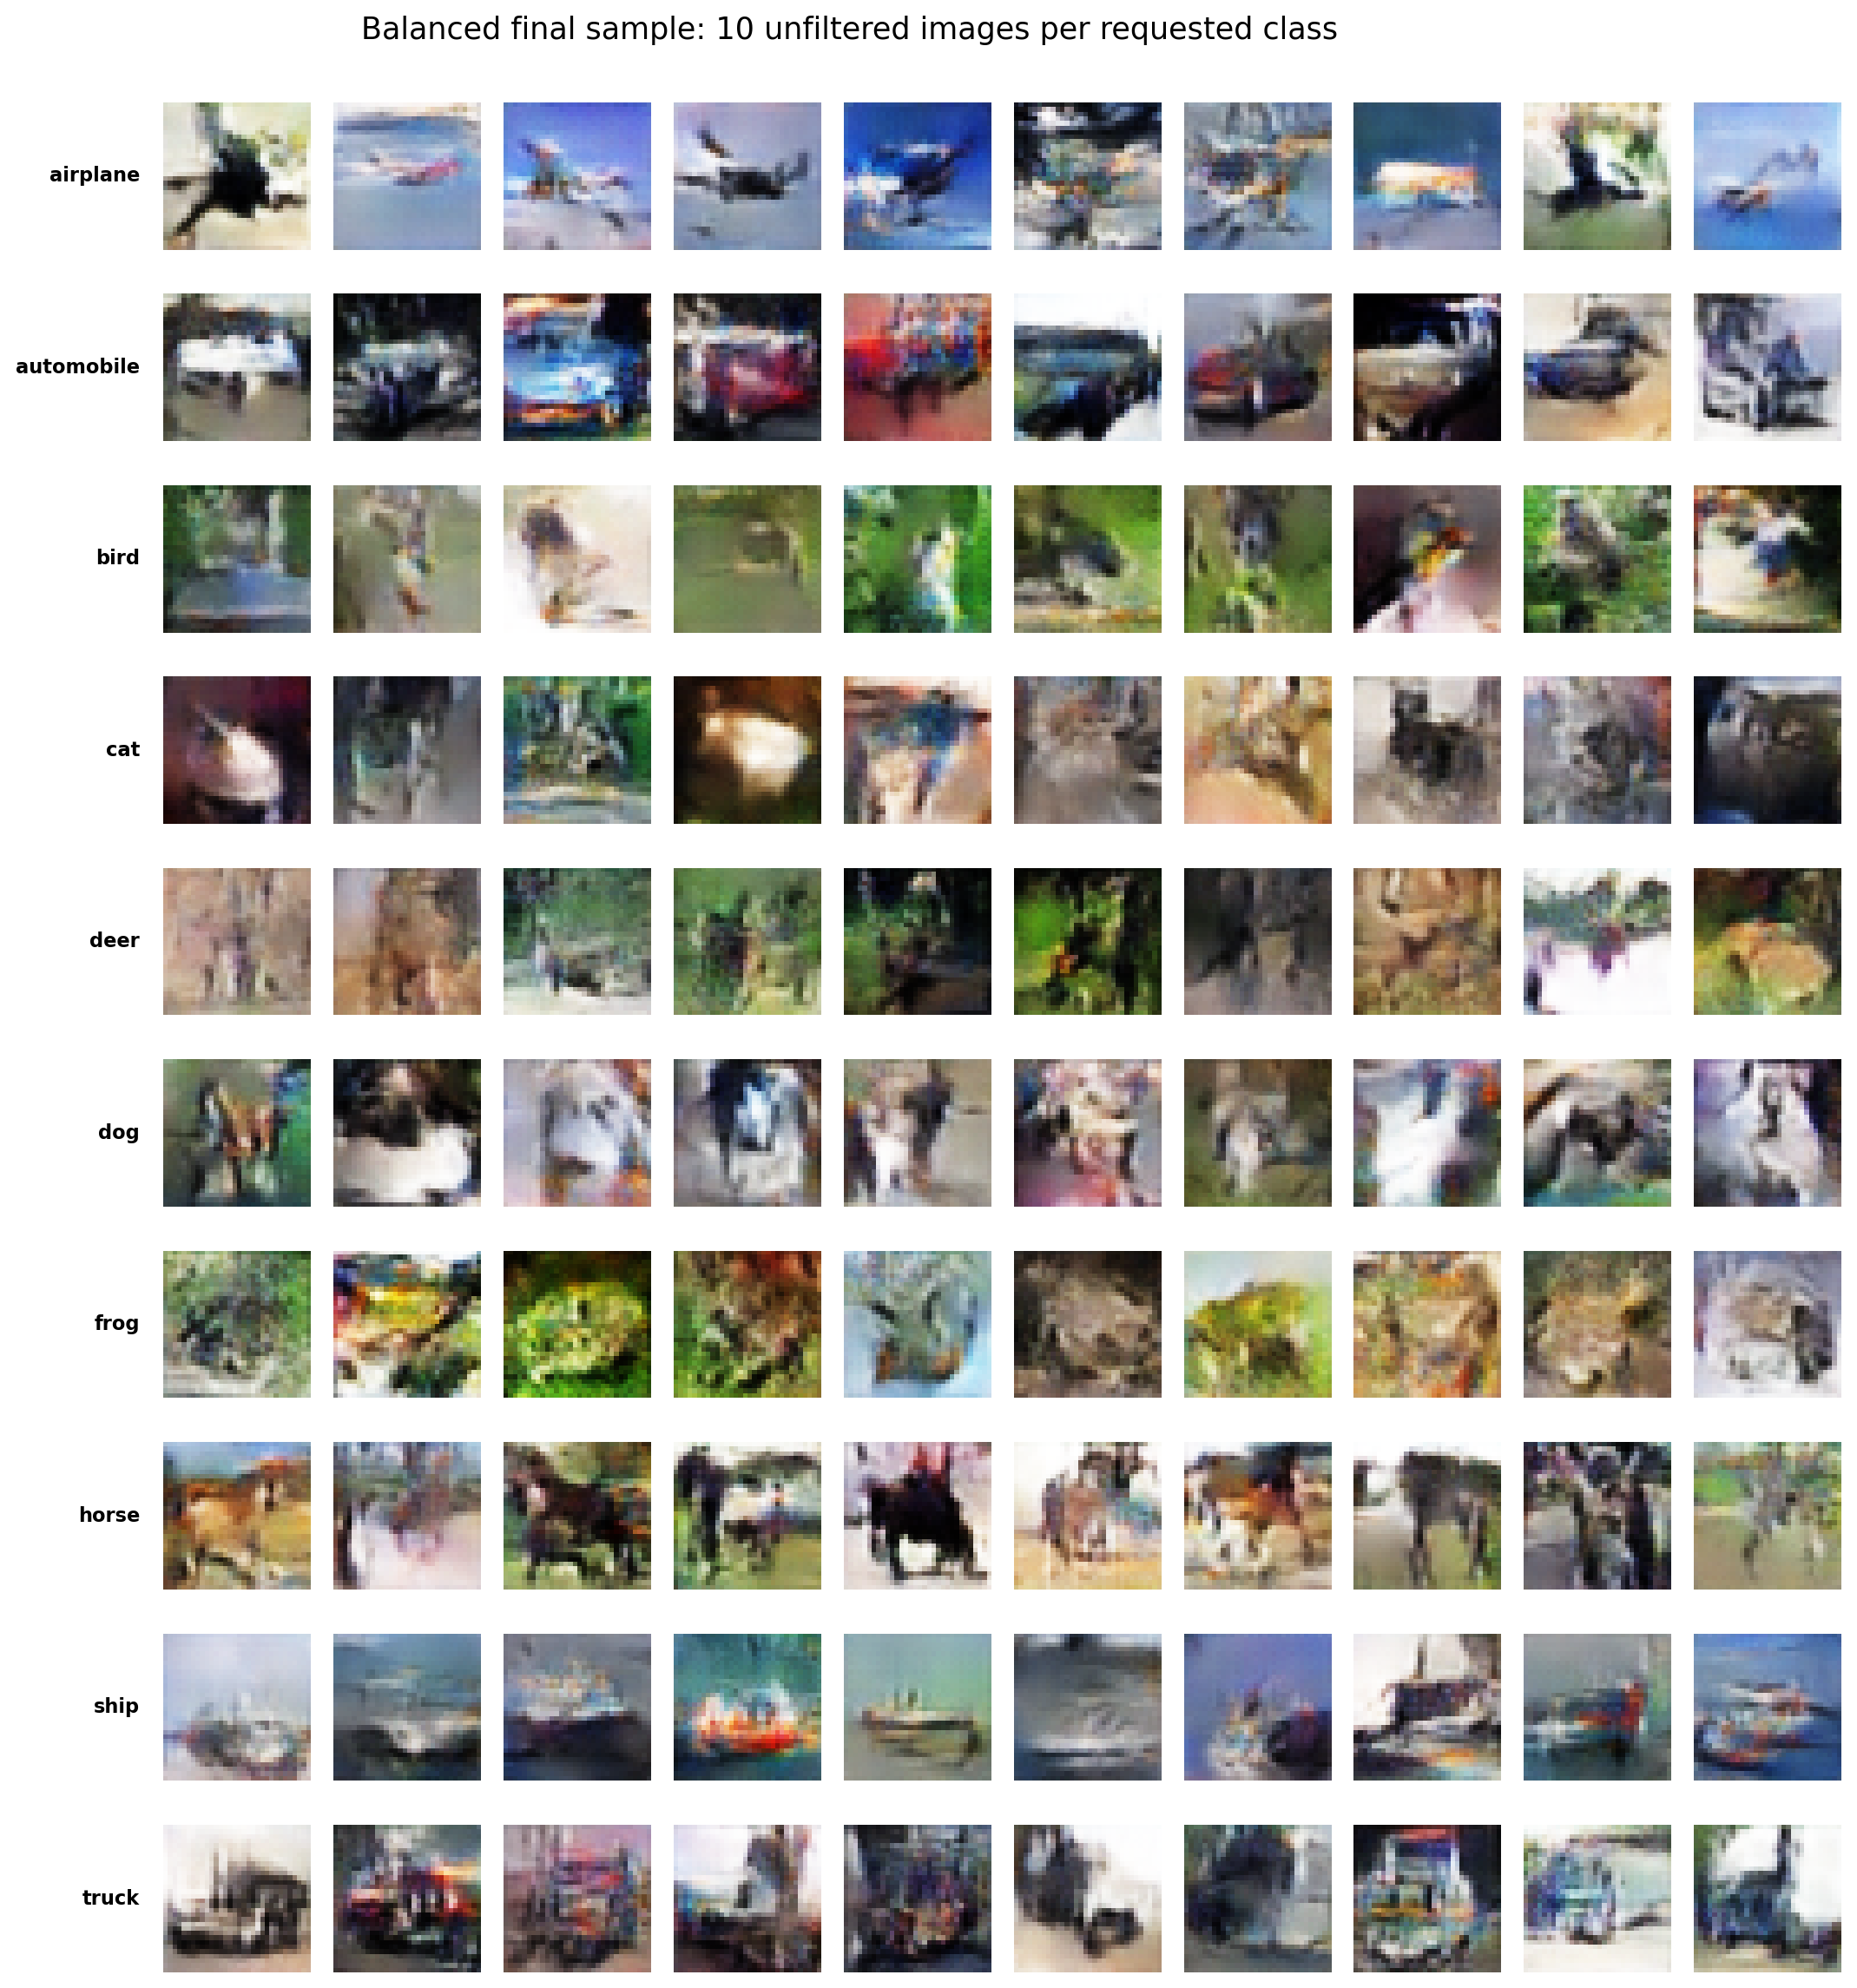

Official test FID: 68.3771
Evaluator official test accuracy: 0.8311
Generated image files: 1000
Blinded review form: part_a_final_outputs\tables\manual_review_form.csv


        class  exported_images  requested_class_match  mean_prediction_confidence
0    airplane              100                   0.94                      0.9256
1  automobile              100                   0.67                      0.7490
2        bird              100                   0.63                      0.6578
3         cat              100                   0.66                      0.6176
4        deer              100                   0.82                      0.6929
5         dog              100                   0.73                      0.6423
6        frog              100                   0.90                      0.8516
7       horse              100                   0.87                      0.8096
8        ship              100                   0.80                      0.8479
9       truck              100                   0.94                      0.8964

In [59]:
balanced_review_indices = np.concatenate([
    np.flatnonzero(final_label_ids == class_id)[:10]
    for class_id in range(NUMBER_OF_CLASSES)
])
figure, axes = plt.subplots(10, 10, figsize=(13, 13))
for class_id, class_name in enumerate(class_names):
    class_indices = balanced_review_indices[
        class_id * 10:(class_id + 1) * 10
    ]
    for column, export_index in enumerate(class_indices):
        axis = axes[class_id, column]
        axis.imshow(
            final_images_uint8[export_index],
            interpolation="nearest",
        )
        axis.axis("off")
    axes[class_id, 0].text(
        -0.16,
        0.5,
        class_name,
        transform=axes[class_id, 0].transAxes,
        ha="right",
        va="center",
        fontsize=9,
        fontweight="bold",
    )
figure.suptitle(
    "Balanced final sample: 10 unfiltered images per requested class",
    fontsize=14,
)
figure.tight_layout(rect=[0.08, 0, 1, 0.98])
BALANCED_FINAL_GRID_PATH = (
    FINAL_FIGURE_DIR / "final_balanced_100_overview.png"
)
figure.savefig(
    BALANCED_FINAL_GRID_PATH,
    dpi=180,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

print(f"Official test FID: {FINAL_TEST_FID:.4f}")
print(
    "Evaluator official test accuracy: "
    f"{final_evaluator_test['accuracy']:.4f}"
)
print("Generated image files:", len(exported_files))
print("Blinded review form:", FINAL_TABLE_DIR / "manual_review_form.csv")
display(final_class_table.round(4))


### Final Export Result

- The selected generator produced exactly `1,000` RGB files, with `100` images for each requested class.
- Official-test FID is `68.38`, compared with `70.07` on the seed-42 validation split. Test-set model performance was calculated only after model and checkpoint selection.
- The class evaluator scores `83.11%` on real official-test images. This is a reliability check on the evaluator, not a generator score.
- Requested-class match across the export is `79.6%`. I examine visual clarity and within-class variation separately because class agreement alone does not establish image quality.

## 12.2 Blinded Visual Inspection

A balanced set of 100 generated images was shuffled before the requested classes were revealed. The same criteria were applied to every image:

| Rating | Criterion |
|---|---|
| `clear` | A coherent object is visible with stable broad structure |
| `marginal` | Object-like structure is present, but it is distorted or ambiguous |
| `nonsense` | No coherent object is visible |

Ten images per class make the class percentages easy to interpret, but they remain a small, subjective sample rather than precise population estimates.


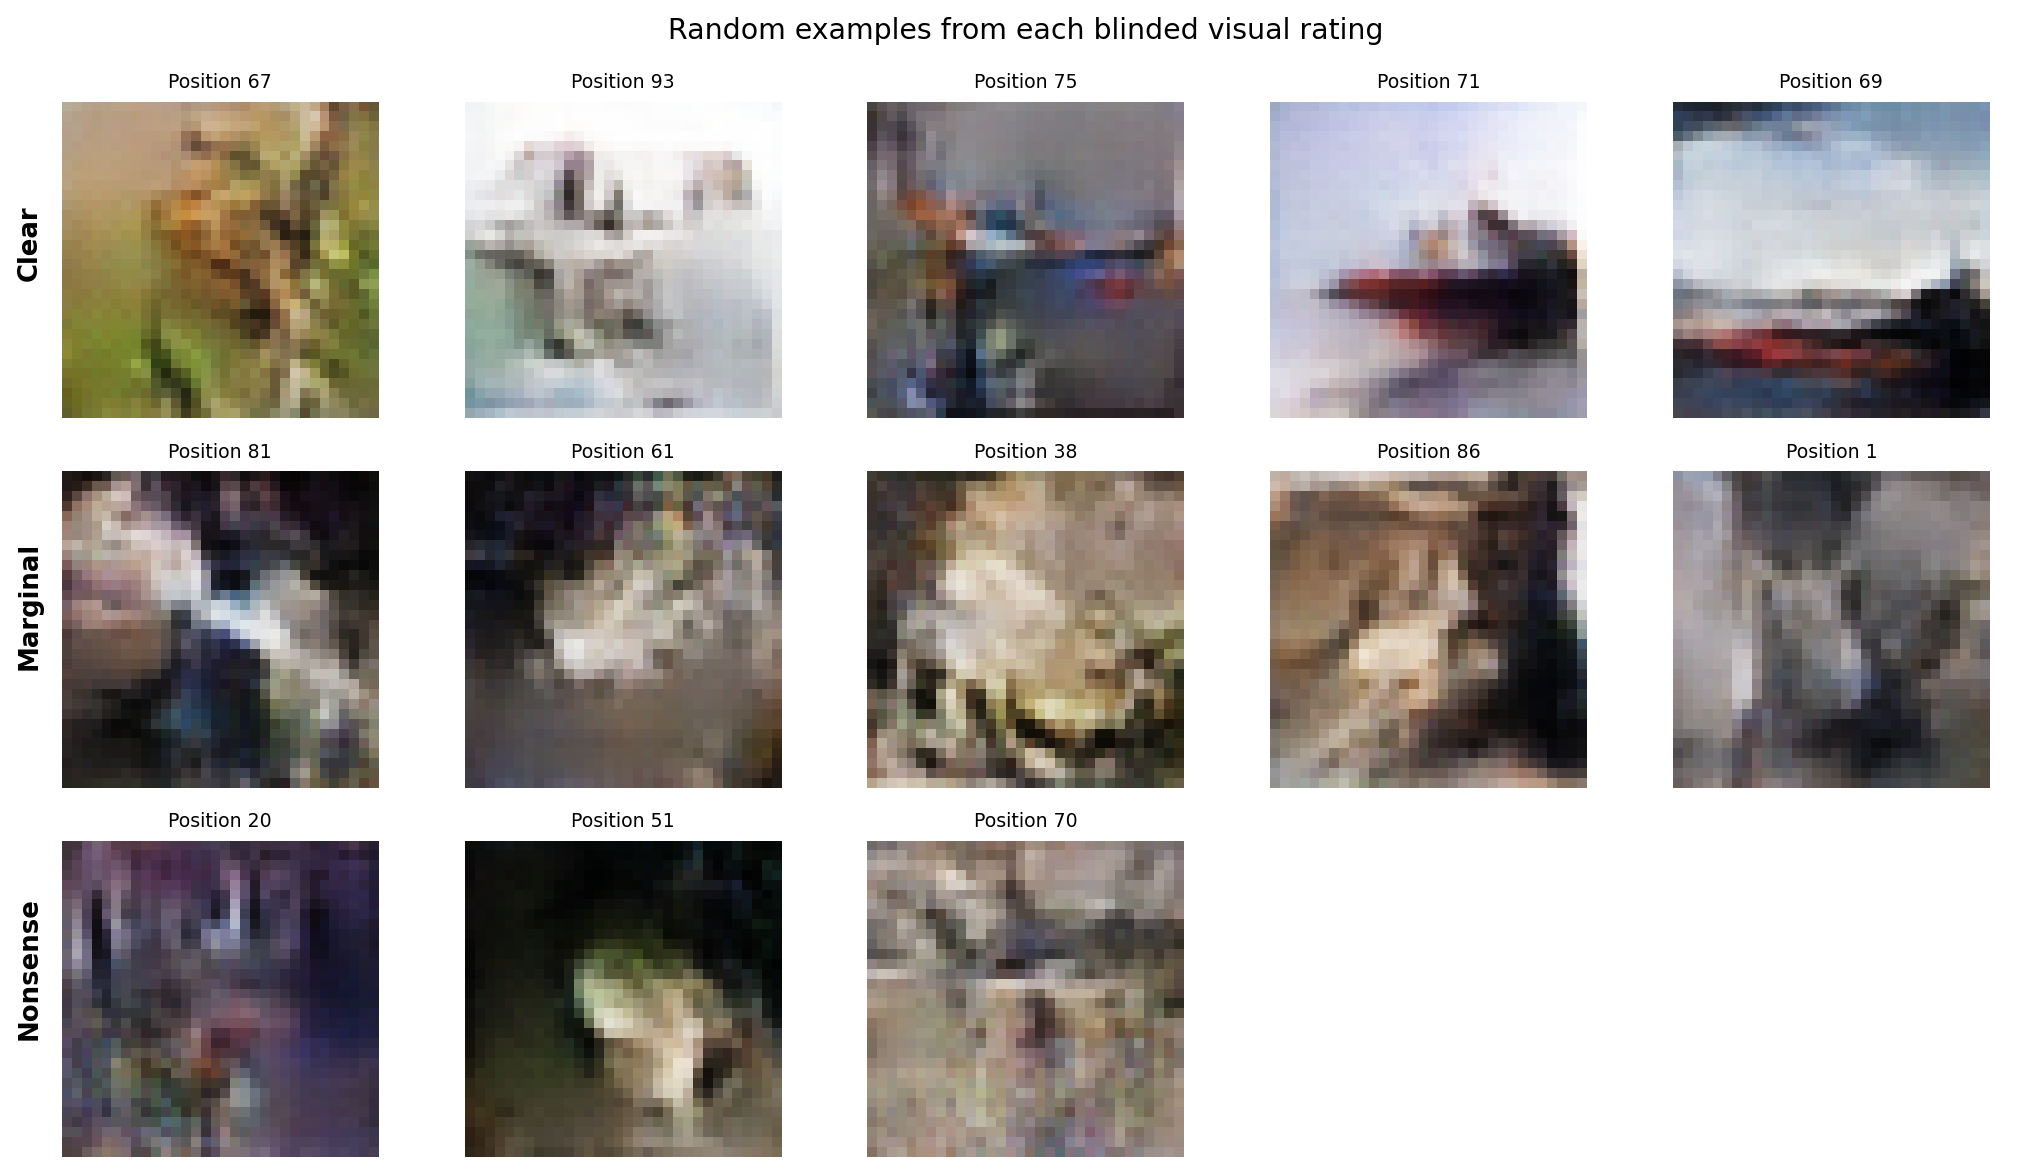

  quality_rating  count  percentage
0          clear     71        71.0
1       marginal     26        26.0
2       nonsense      3         3.0

                 clear  marginal  nonsense  clear_rate  acceptable_rate
requested_class                                                        
airplane             8         2         0         0.8              1.0
automobile          10         0         0         1.0              1.0
bird                 5         5         0         0.5              1.0
cat                  6         4         0         0.6              1.0
deer                 6         2         2         0.6              0.8
dog                  7         3         0         0.7              1.0
frog                 1         8         1         0.1              0.9
horse                8         2         0         0.8              1.0
ship                10         0         0         1.0              1.0
truck               10         0         0         1.0              1.0

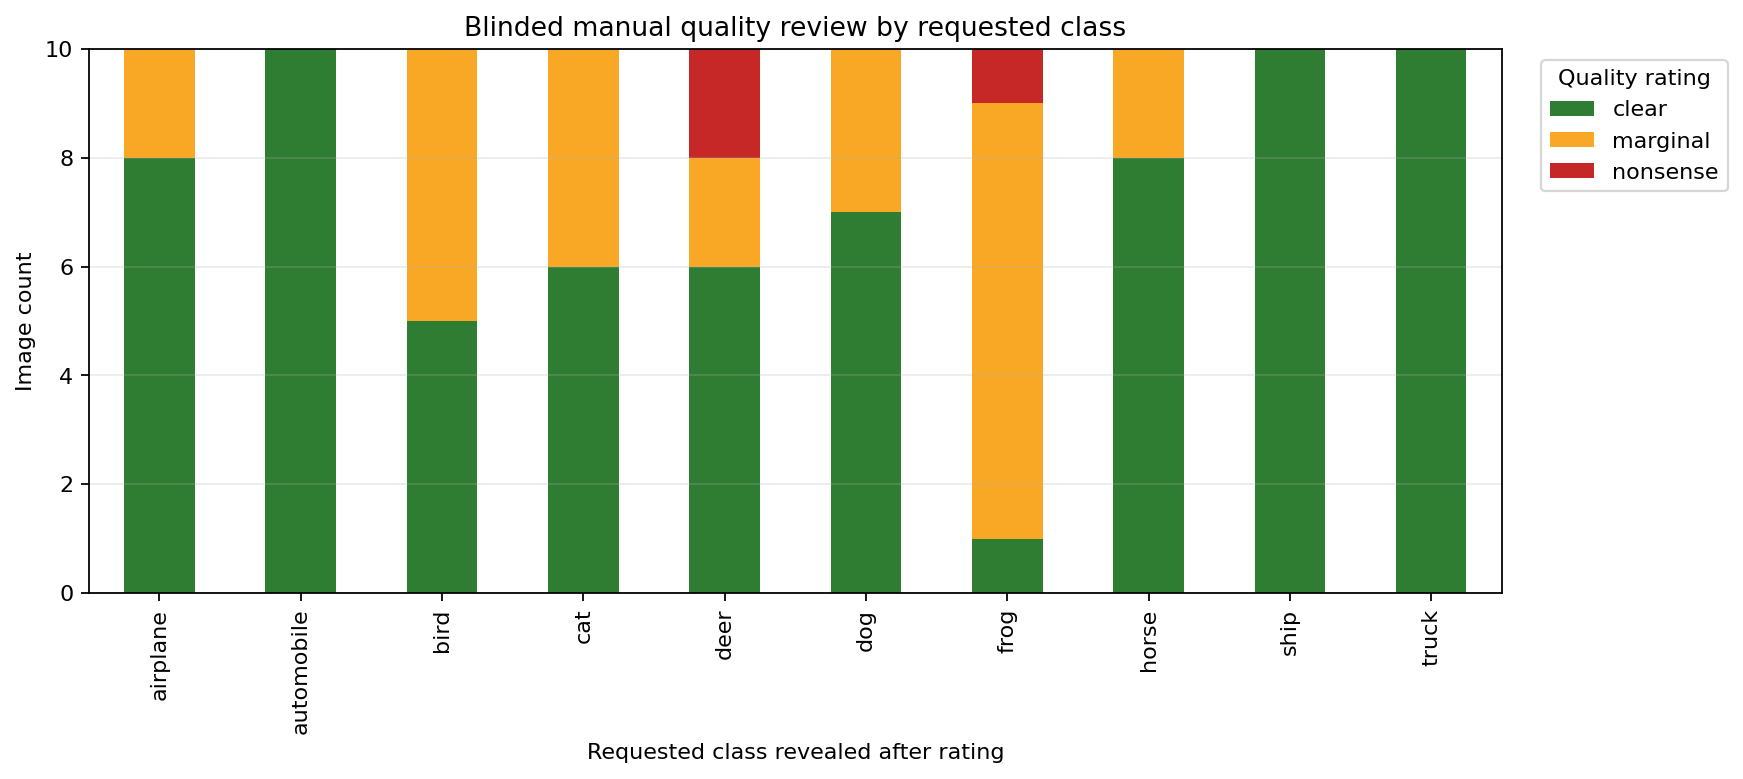

In [60]:
MANUAL_RATINGS_PATH = FINAL_TABLE_DIR / "manual_review_completed.csv"


def load_manual_ratings(path):
    if not path.exists():
        return None

    ratings = pd.read_csv(path)
    required_columns = {"review_position", "quality_rating"}
    if not required_columns.issubset(ratings.columns):
        return None

    assert len(ratings) == 100
    assert ratings["review_position"].tolist() == list(range(1, 101))
    ratings["quality_rating"] = (
        ratings["quality_rating"].str.strip().str.lower()
    )
    valid_quality = {"clear", "marginal", "nonsense"}
    assert set(ratings["quality_rating"]).issubset(valid_quality)
    return ratings[["review_position", "quality_rating"]]


manual_ratings = load_manual_ratings(MANUAL_RATINGS_PATH)
MANUAL_RATINGS_COMPLETE = manual_ratings is not None

if MANUAL_RATINGS_COMPLETE:
    manual_review = manual_review_key.merge(
        manual_ratings,
        on="review_position",
        validate="one_to_one",
    )
    manual_review.to_csv(
        FINAL_TABLE_DIR / "manual_review_100_ratings_with_key.csv",
        index=False,
    )

    rating_order = ["clear", "marginal", "nonsense"]
    manual_overall = (
        manual_review["quality_rating"]
        .value_counts()
        .reindex(rating_order, fill_value=0)
        .rename_axis("quality_rating")
        .reset_index(name="count")
    )
    manual_overall["percentage"] = (
        100 * manual_overall["count"] / len(manual_review)
    )
    manual_overall.to_csv(
        FINAL_TABLE_DIR / "manual_review_overall.csv",
        index=False,
    )

    manual_by_class = pd.crosstab(
        manual_review["requested_class"],
        manual_review["quality_rating"],
    ).reindex(
        index=class_names,
        columns=rating_order,
        fill_value=0,
    )
    manual_by_class["clear_rate"] = manual_by_class["clear"] / 10
    manual_by_class["acceptable_rate"] = (
        manual_by_class["clear"] + manual_by_class["marginal"]
    ) / 10
    manual_by_class.to_csv(
        FINAL_TABLE_DIR / "manual_review_by_class.csv"
    )

    example_rng = np.random.default_rng(FINAL_EXPORT_SEED + 4)
    figure, axes = plt.subplots(3, 5, figsize=(12, 7))
    for row_index, quality_rating in enumerate(rating_order):
        category_rows = manual_review.loc[
            manual_review["quality_rating"] == quality_rating
        ]
        sample_size = min(5, len(category_rows))
        if sample_size:
            selected_indices = example_rng.choice(
                category_rows.index,
                size=sample_size,
                replace=False,
            )
            selected_rows = category_rows.loc[selected_indices]
        else:
            selected_rows = category_rows

        for axis in axes[row_index]:
            axis.axis("off")
        for axis, (_, record) in zip(
            axes[row_index],
            selected_rows.iterrows(),
        ):
            with Image.open(FINAL_IMAGE_DIR / record["filename"]) as image:
                axis.imshow(image, interpolation="nearest")
            axis.set_title(
                f"Position {record['review_position']}",
                fontsize=8,
            )

        figure.text(
            0.012,
            0.79 - row_index * 0.305,
            quality_rating.capitalize(),
            rotation=90,
            va="center",
            ha="center",
            fontsize=11,
            fontweight="bold",
        )

    figure.suptitle("Random examples from each blinded visual rating")
    figure.tight_layout()
    figure.savefig(
        FINAL_FIGURE_DIR / "manual_review_rating_examples.png",
        dpi=170,
        bbox_inches="tight",
    )
    plt.show()

    display(manual_overall)
    display(manual_by_class)

    figure, axis = plt.subplots(figsize=(11, 5))
    manual_by_class[rating_order].plot(
        kind="bar",
        stacked=True,
        color=["#2e7d32", "#f9a825", "#c62828"],
        ax=axis,
    )
    axis.set_title("Blinded manual quality review by requested class")
    axis.set_xlabel("Requested class revealed after rating")
    axis.set_ylabel("Image count")
    axis.set_ylim(0, 10)
    axis.legend(
        title="Quality rating",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )
    axis.grid(axis="y", alpha=0.25)
    figure.tight_layout()
    figure.savefig(
        FINAL_FIGURE_DIR / "manual_review_by_class.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()
else:
    manual_overall = None
    manual_by_class = None
    print(
        "Manual review pending. Complete manual_review_form.csv and save "
        "it as manual_review_completed.csv."
    )


### Visual-inspection result

The 100 ratings were recorded before the requested labels were joined back to the shuffled images. No image was replaced after inspection. These judgements remain subjective and should be read together with the example grid.

- `71` images were clear, `26` marginal and `3` nonsense. Thus, `97%` showed at least some object-like structure, while `71%` were rated clear.
- Automobile, ship and truck had `10/10` clear images; airplane and horse had `8/10`, and dog had `7/10`.
- Frog had only `1/10` clear image. Deer contained two of the three nonsense ratings, while frog contained the other.
- The evaluator and visual review do not always agree. Frog reached `90%` requested-class match but only `10%` clear images, whereas automobile had `67%` class match but `100%` clear images. The evaluator can detect class-related colour or texture even when structure is weak, and it can also confuse a recognisable vehicle with a related class.

The balanced grid below contains ten unfiltered images per requested class from the same frozen export.

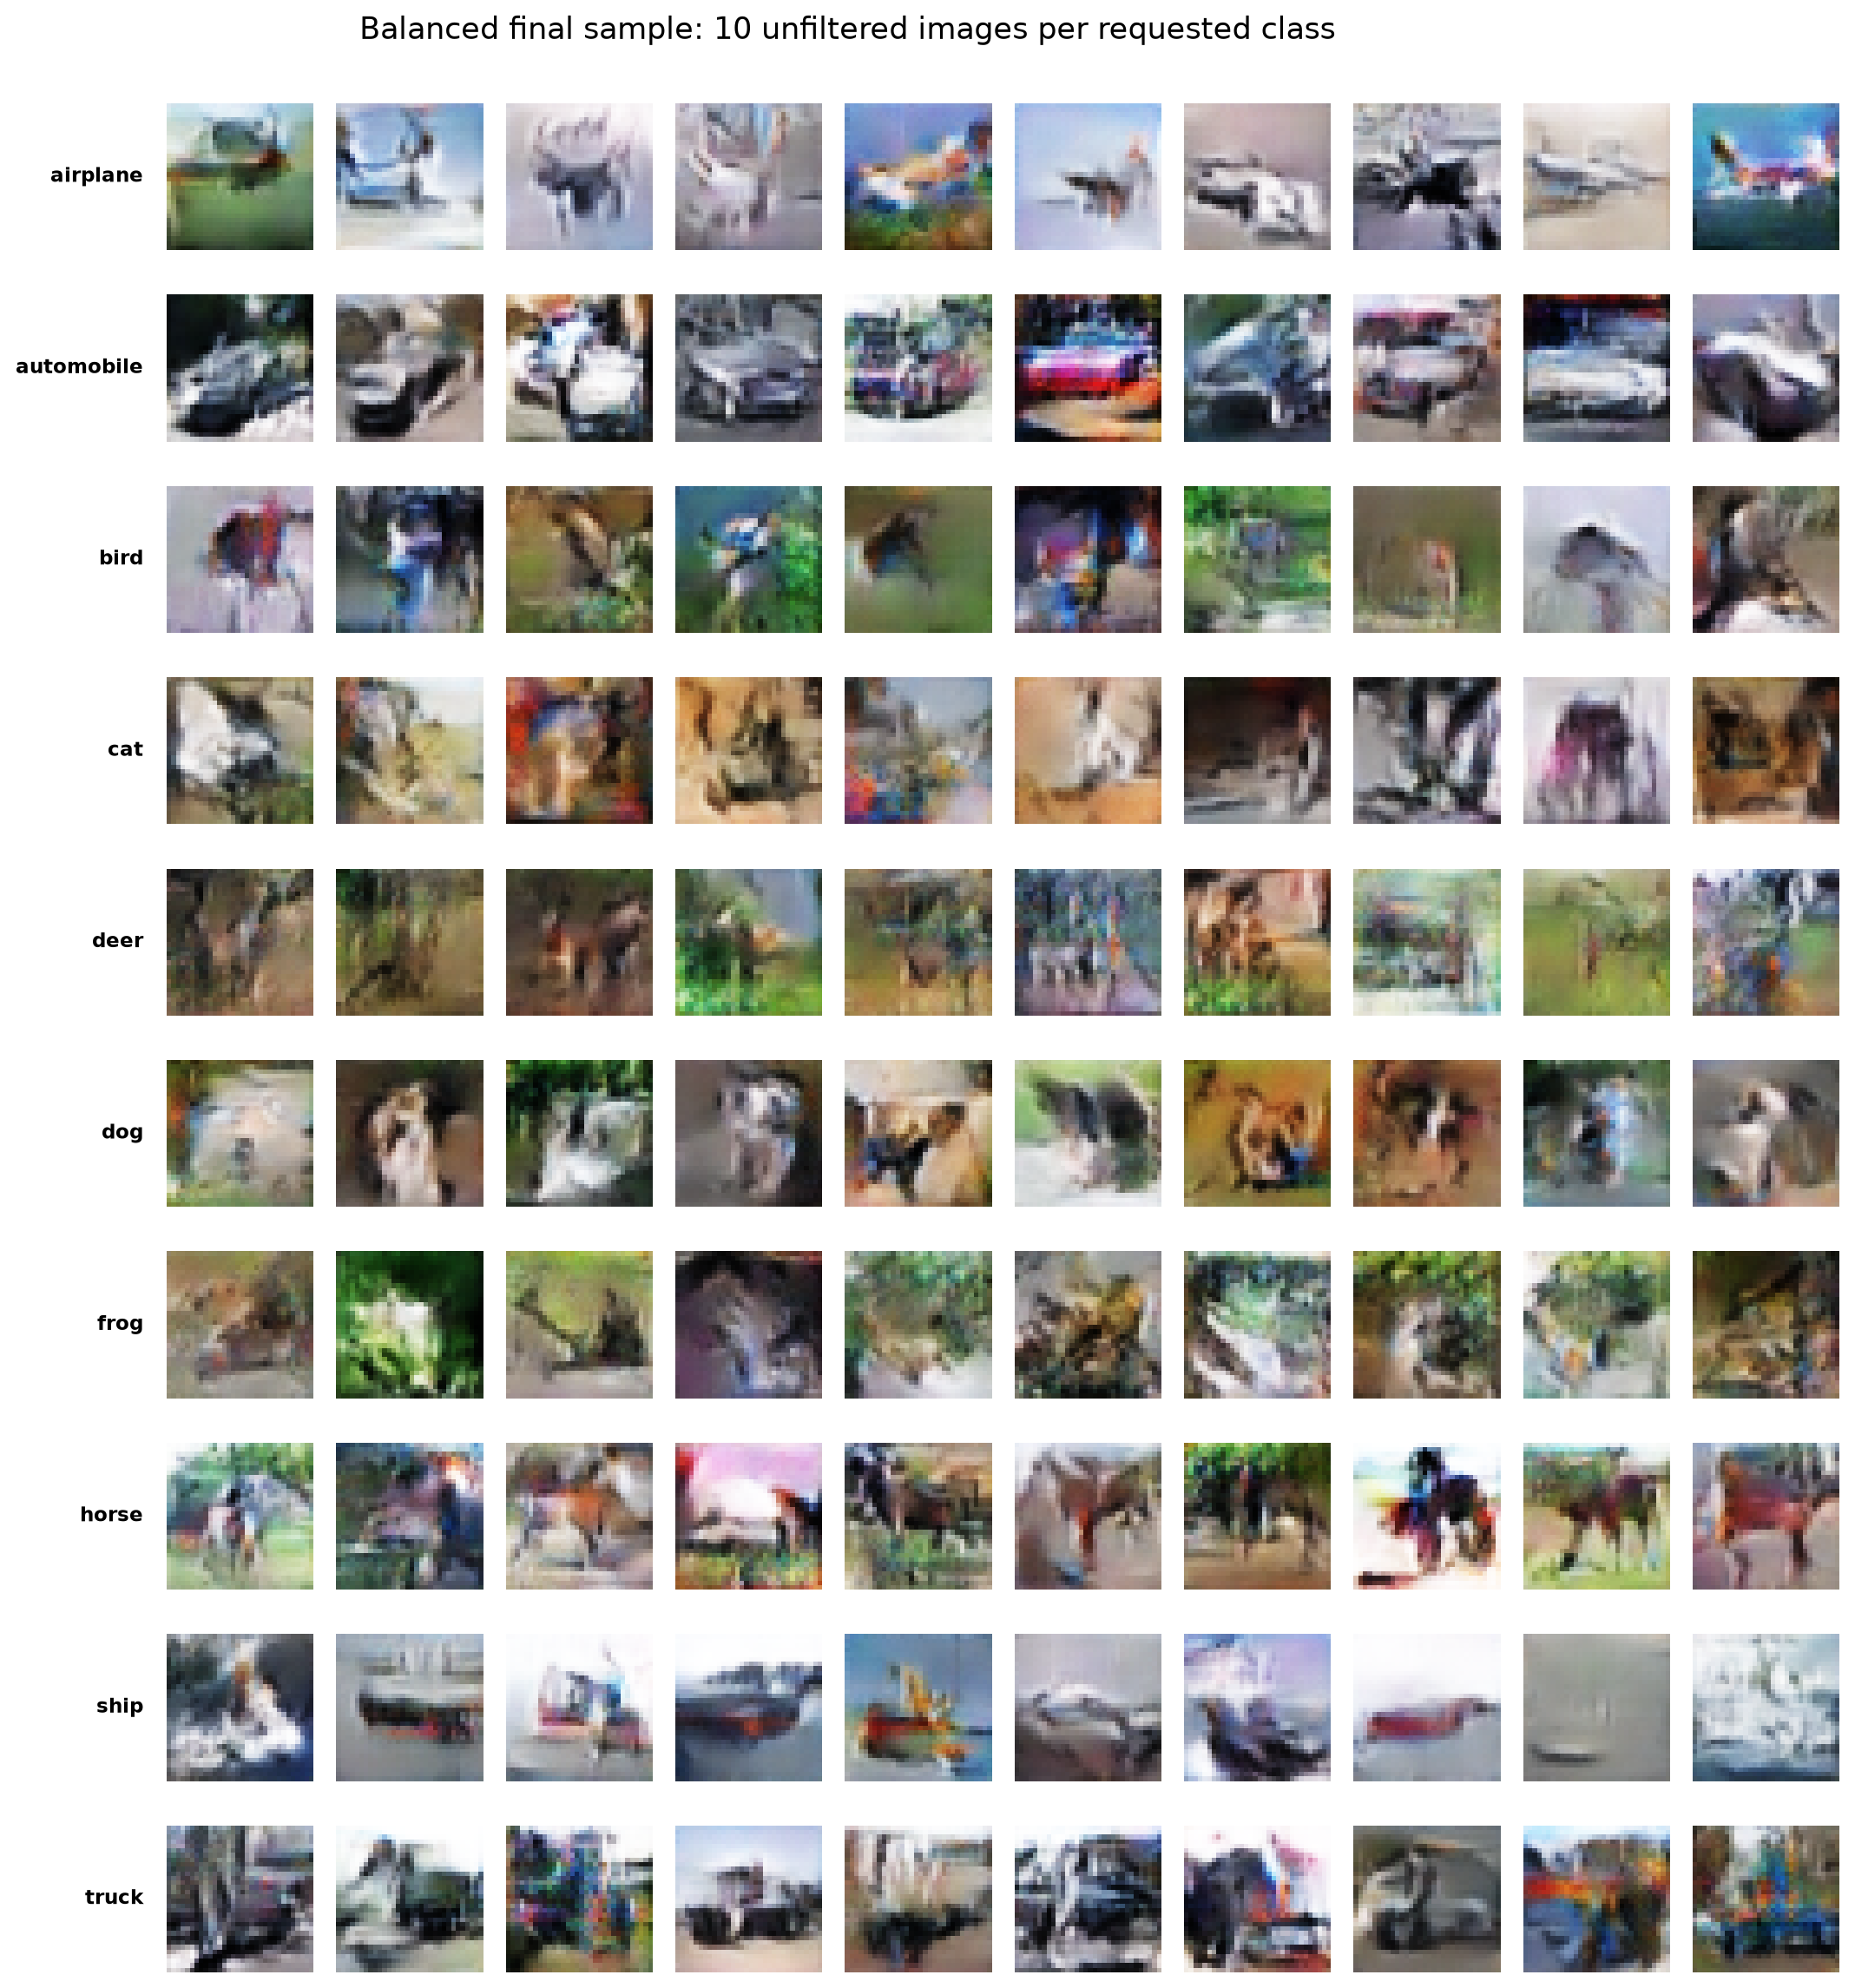

## 12.3 Final Class-Level Evaluation

The class evaluator is applied to all 1,000 exported images. Its results are compared with the label-blind visual ratings after those ratings are complete. Classifier agreement remains supporting evidence because the evaluator has measurable errors on real official-test images.


In [61]:
if MANUAL_RATINGS_COMPLETE:
    final_class_evidence = final_class_table.merge(
        manual_by_class.reset_index(),
        left_on="class",
        right_on="requested_class",
        how="left",
        validate="one_to_one",
    ).drop(columns="requested_class")
else:
    final_class_evidence = final_class_table.copy()

final_class_evidence.to_csv(
    FINAL_TABLE_DIR / "final_class_evidence.csv",
    index=False,
)
display(final_class_evidence.round(4))


        class  exported_images  requested_class_match  mean_prediction_confidence  clear  marginal  nonsense  clear_rate  acceptable_rate
0    airplane              100                   0.94                      0.9256      8         2         0         0.8              1.0
1  automobile              100                   0.67                      0.7490     10         0         0         1.0              1.0
2        bird              100                   0.63                      0.6578      5         5         0         0.5              1.0
3         cat              100                   0.66                      0.6176      6         4         0         0.6              1.0
4        deer              100                   0.82                      0.6929      6         2         2         0.6              0.8
5         dog              100                   0.73                      0.6423      7         3         0         0.7              1.0
6        frog              100    

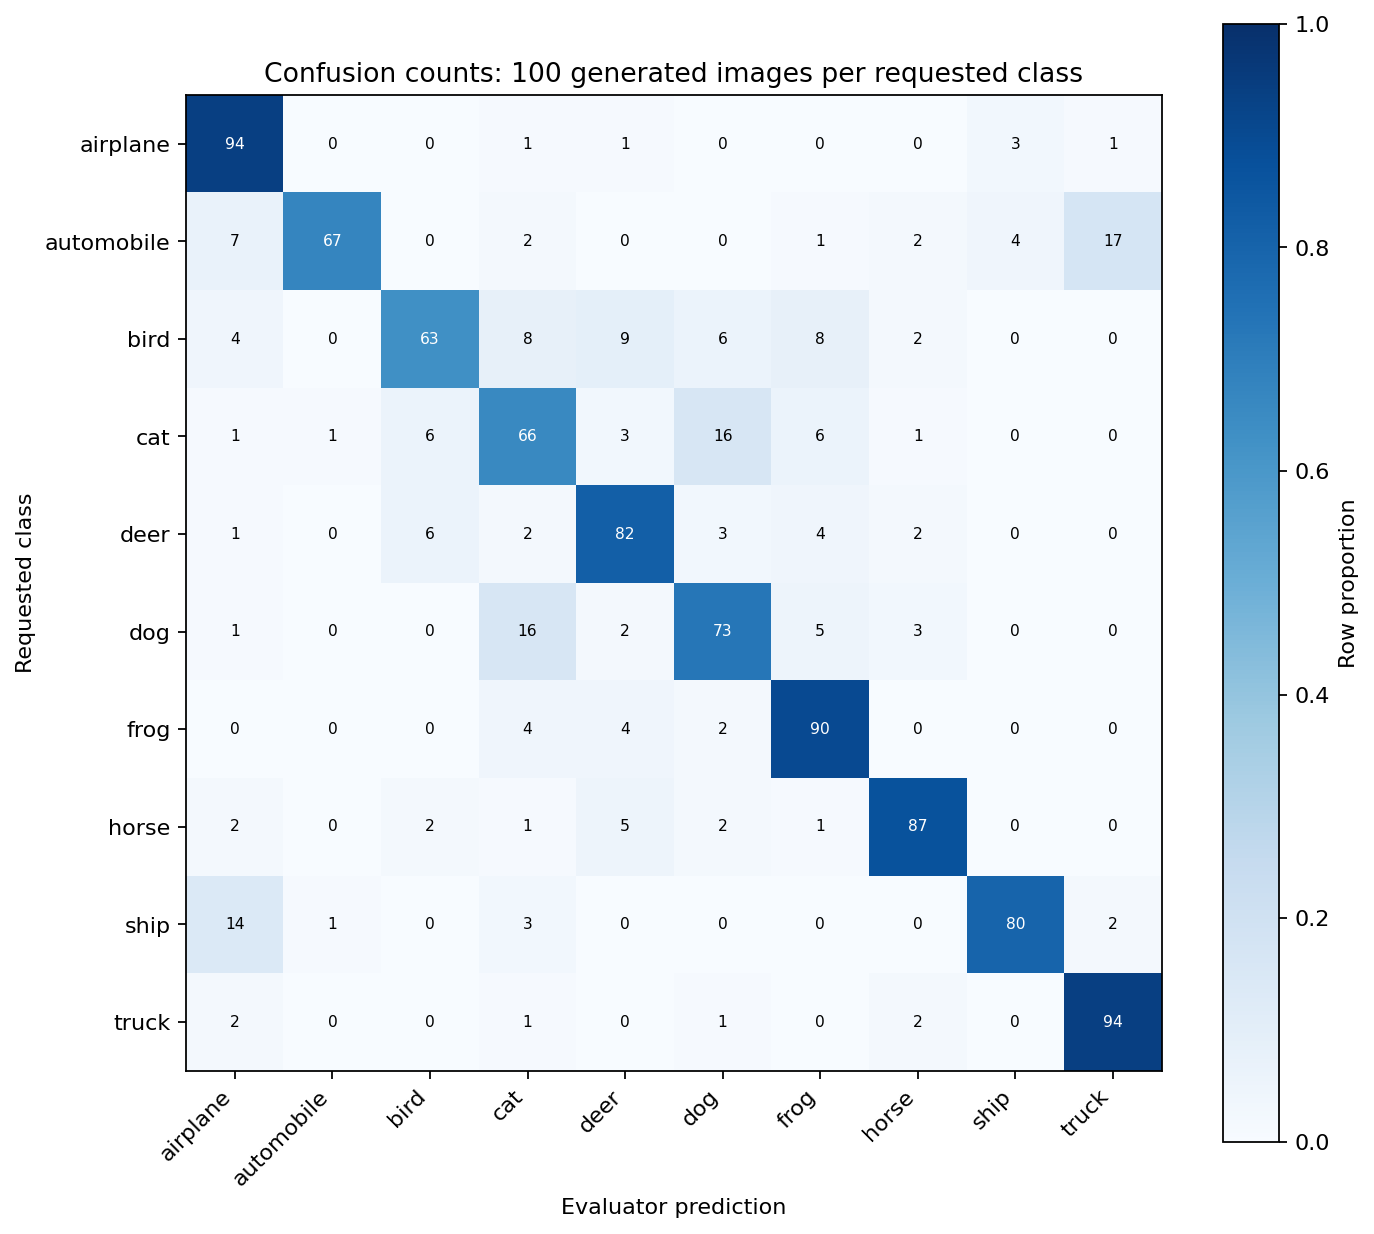

In [62]:
final_confusion = np.zeros(
    (NUMBER_OF_CLASSES, NUMBER_OF_CLASSES),
    dtype="int32",
)
for requested_id, predicted_id in zip(
    final_label_ids,
    final_predictions,
):
    final_confusion[requested_id, predicted_id] += 1

final_confusion_table = pd.DataFrame(
    final_confusion,
    index=class_names,
    columns=class_names,
)
final_confusion_table.to_csv(
    FINAL_TABLE_DIR / "final_export_confusion_matrix.csv"
)

figure, axis = plt.subplots(figsize=(9, 8))
image = axis.imshow(
    final_confusion / FINAL_IMAGES_PER_CLASS,
    cmap="Blues",
    vmin=0,
    vmax=1,
)
axis.set_xticks(
    np.arange(NUMBER_OF_CLASSES),
    class_names,
    rotation=45,
    ha="right",
)
axis.set_yticks(np.arange(NUMBER_OF_CLASSES), class_names)
axis.set_xlabel("Evaluator prediction")
axis.set_ylabel("Requested class")
axis.set_title("Confusion counts: 100 generated images per requested class")
for row in range(NUMBER_OF_CLASSES):
    for column in range(NUMBER_OF_CLASSES):
        value = final_confusion[row, column]
        axis.text(
            column,
            row,
            str(value),
            ha="center",
            va="center",
            fontsize=7,
            color="white" if value >= 55 else "black",
        )
figure.colorbar(image, ax=axis, label="Row proportion")
figure.tight_layout()
figure.savefig(
    FINAL_FIGURE_DIR / "final_export_confusion_matrix.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()


### Class-level findings

Each confusion-matrix row contains 100 generated images. The cell values are counts and the colour scale gives the row proportion.

The evaluator achieved `83.11%` accuracy on real official-test images. Its weakest real-image recall was cat (`64.0%`), followed by dog (`75.8%`), so generated-image class match is interpreted alongside that limitation.

| Finding | Evidence | Interpretation |
|---|---|---|
| Strongest automated match | Airplane and truck `94%`, frog `90%`, horse `87%` | Strong class cues are present, but frog's `10%` clear rate shows that match is not a realism score |
| Weakest automated match | Bird `63%`, cat `66%`, automobile `67%`, dog `73%` | Fine animal structure and separation between related vehicles remain difficult |
| Main vehicle confusion | Automobile `17%` to truck; ship `14%` to airplane | Broad silhouettes and background colour are not separated consistently |
| Main animal confusion | Cat `16%` to dog and dog `16%` to cat; bird splits across deer (`9%`), cat and frog (`8%` each) | Similar low-resolution animal features produce the largest semantic overlap |

Overall requested-class match is `79.6%`, compared with the checkpoint's `76.40%` validation result. The visual review answers a different question: automobile was always recognisable despite lower class match, while frog often carried the right cues without a clear shape. I therefore keep both measures in the final decision.


## 12.4 Duplicate and Diversity Diagnostics

Exact hashing answers whether exported files repeat exactly or match an assigned training image exactly. It cannot exclude near-copying after small pixel changes. Feature-space distance provides a broader within-class variation check, but large distances can also result from unrealistic noise. The two diagnostics are interpreted together with FID and the manual review.

The diversity comparison uses the class evaluator's penultimate feature vector. For every class, I compare the median pairwise cosine distance among 100 generated images with 100 fixed real test images. This is a relative diagnostic, not a new quality score.


In [63]:
from scipy.spatial.distance import pdist

generated_raw_hashes = pd.Series([
    hashlib.sha256(image.tobytes()).hexdigest()
    for image in final_images_uint8
])
generated_hash_counts = generated_raw_hashes.value_counts()
duplicate_groups = int((generated_hash_counts > 1).sum())
additional_duplicates = int(
    (generated_hash_counts[generated_hash_counts > 1] - 1).sum()
)

training_raw_hashes = {
    hashlib.sha256(image.tobytes()).hexdigest()
    for image in x_model_train
}
exact_training_matches = int(
    generated_raw_hashes.isin(training_raw_hashes).sum()
)

feature_layer = next(
    layer
    for layer in class_evaluator.layers
    if isinstance(layer, keras.layers.GlobalAveragePooling2D)
)
semantic_feature_model = keras.Model(
    class_evaluator.input,
    feature_layer.output,
)
generated_semantic_features = semantic_feature_model.predict(
    final_images_01,
    batch_size=128,
    verbose=0,
)


In [64]:
diversity_rng = np.random.default_rng(FINAL_EXPORT_SEED + 2)
real_diversity_indices = balanced_sample_indices(
    y_test,
    100,
    diversity_rng,
)
real_diversity_images = (
    x_test[real_diversity_indices].astype("float32") / 255
)
real_semantic_features = semantic_feature_model.predict(
    real_diversity_images,
    batch_size=128,
    verbose=0,
)

diversity_records = []
for class_id, class_name in enumerate(class_names):
    generated_mask = final_label_ids == class_id
    real_mask = y_test[real_diversity_indices] == class_id
    generated_distances = pdist(
        generated_semantic_features[generated_mask],
        metric="cosine",
    )
    real_distances = pdist(
        real_semantic_features[real_mask],
        metric="cosine",
    )
    generated_median = float(np.median(generated_distances))
    real_median = float(np.median(real_distances))
    diversity_records.append({
        "class": class_name,
        "generated_median_cosine_distance": generated_median,
        "real_median_cosine_distance": real_median,
        "generated_to_real_ratio": generated_median / real_median,
    })

final_diversity_table = pd.DataFrame(diversity_records)
assert np.isfinite(
    final_diversity_table.select_dtypes(include="number").to_numpy()
).all()
final_diversity_table.to_csv(
    FINAL_TABLE_DIR / "final_feature_diversity.csv",
    index=False,
)

duplicate_summary = pd.DataFrame([{
    "generated_images": FINAL_IMAGE_COUNT,
    "exact_duplicate_groups": duplicate_groups,
    "additional_exact_duplicates": additional_duplicates,
    "exact_matches_to_training_images": exact_training_matches,
}])
duplicate_summary.to_csv(
    FINAL_TABLE_DIR / "final_duplicate_summary.csv",
    index=False,
)
display(duplicate_summary)
display(final_diversity_table.round(4))


   generated_images  exact_duplicate_groups  additional_exact_duplicates  exact_matches_to_training_images
0              1000                       0                            0                                 0

        class  generated_median_cosine_distance  real_median_cosine_distance  generated_to_real_ratio
0    airplane                            0.2220                       0.2716                   0.8176
1  automobile                            0.2689                       0.1479                   1.8182
2        bird                            0.2550                       0.2609                   0.9772
3         cat                            0.2413                       0.2818                   0.8563
4        deer                            0.1890                       0.2587                   0.7308
5         dog                            0.1887                       0.2064                   0.9145
6        frog                            0.1683                       0.2289                   0.7353
7       horse                            0.1891                       0.2006                   0.9427
8        ship                            0.2333                       0.2283      

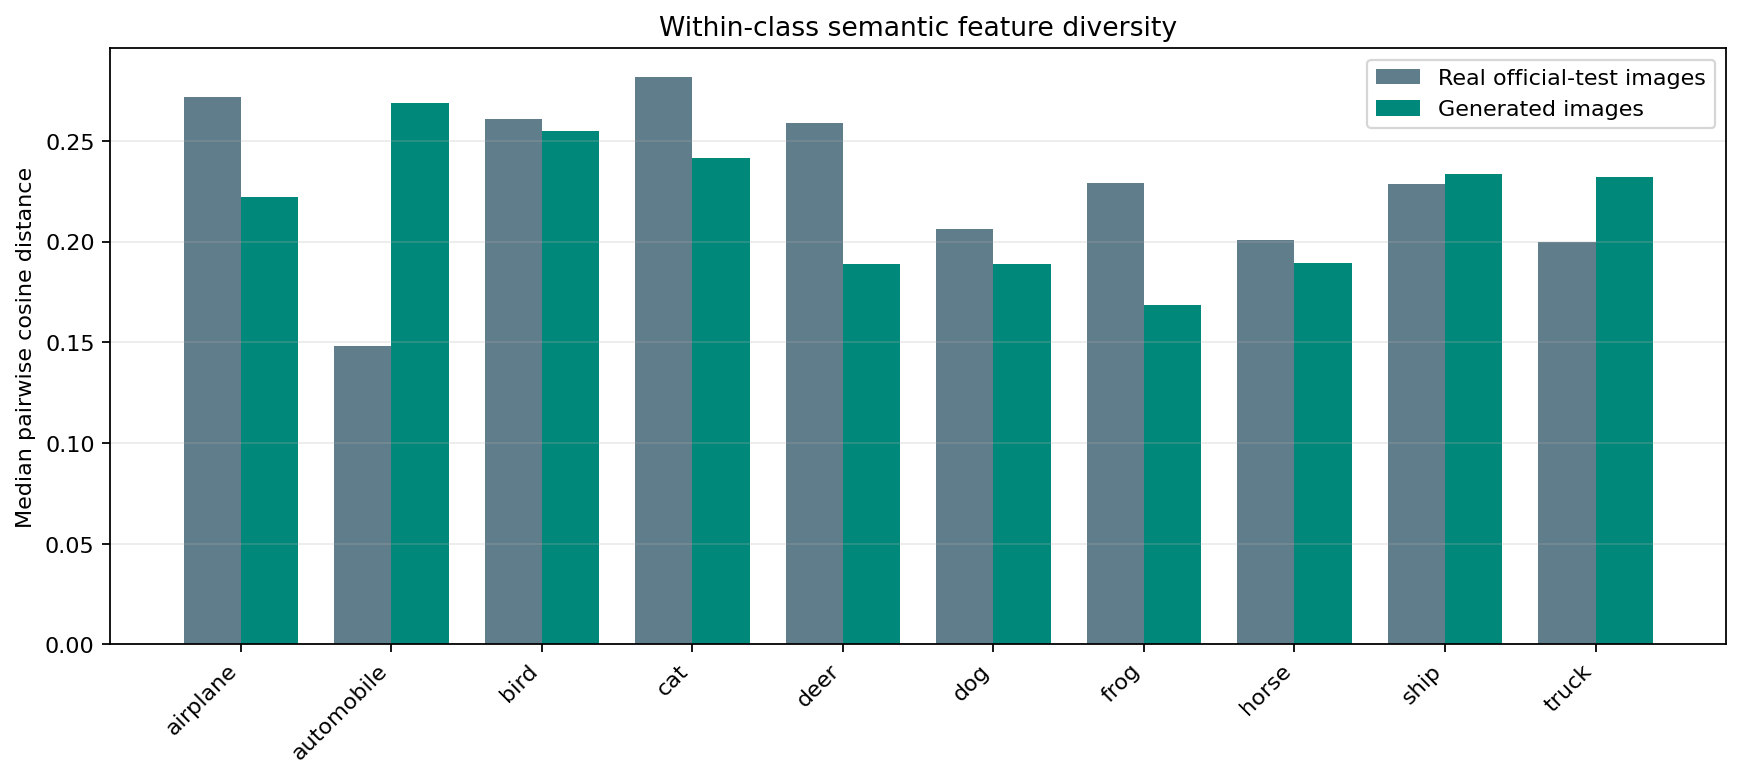

In [65]:
figure, axis = plt.subplots(figsize=(11, 5))
positions = np.arange(NUMBER_OF_CLASSES)
width = 0.38
axis.bar(
    positions - width / 2,
    final_diversity_table["real_median_cosine_distance"],
    width,
    label="Real official-test images",
    color="#607d8b",
)
axis.bar(
    positions + width / 2,
    final_diversity_table["generated_median_cosine_distance"],
    width,
    label="Generated images",
    color="#00897b",
)
axis.set_xticks(positions, class_names, rotation=45, ha="right")
axis.set_ylabel("Median pairwise cosine distance")
axis.set_title("Within-class semantic feature diversity")
axis.legend()
axis.grid(axis="y", alpha=0.25)
figure.tight_layout()
figure.savefig(
    FINAL_FIGURE_DIR / "final_feature_diversity.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()


### Duplicate and diversity findings

- The 1,000-image export contains `0` exact duplicate groups and `0` byte-identical matches to the 45,000 model-training images. This rules out exact copying only; it cannot exclude near-duplicates or memorisation.
- Generated feature diversity was below the real reference in seven classes. Deer (`0.731` of real diversity) and frog (`0.735`) were lowest, followed by airplane (`0.818`) and cat (`0.856`).
- Automobile (`1.818`), truck (`1.162`) and ship (`1.022`) exceeded the real reference. A ratio above one is not automatically better: confusion and imperfect structure show that some spread can come from inconsistent images rather than useful coverage.
- The result explains why requested-class match cannot stand alone. Frog has strong class agreement but restricted feature variation, while automobile is visually recognisable yet spreads into related evaluator classes.

## 12.5 Latent-Space Continuity

The same spherical path between two fixed latent vectors is evaluated under four class labels. Gradual changes support local continuity; abrupt jumps or repeated frames would indicate a less useful latent representation. This remains a diagnostic rather than a realism metric.


In [66]:
def spherical_interpolation(start, end, interpolation_values):
    start_direction = start / np.linalg.norm(start)
    end_direction = end / np.linalg.norm(end)
    cosine_angle = np.clip(
        np.dot(start_direction, end_direction),
        -1,
        1,
    )
    angle = np.arccos(cosine_angle)
    if np.isclose(angle, 0):
        return np.array([
            (1 - value) * start + value * end
            for value in interpolation_values
        ], dtype="float32")

    sine_angle = np.sin(angle)
    return np.array([
        (
            np.sin((1 - value) * angle) / sine_angle * start
            + np.sin(value * angle) / sine_angle * end
        )
        for value in interpolation_values
    ], dtype="float32")


interpolation_rng = np.random.default_rng(FINAL_EXPORT_SEED + 3)
interpolation_start = interpolation_rng.normal(
    size=LATENT_DIM
).astype("float32")
interpolation_end = interpolation_rng.normal(
    size=LATENT_DIM
).astype("float32")
interpolation_values = np.linspace(0, 1, 8)
interpolation_path = spherical_interpolation(
    interpolation_start,
    interpolation_end,
    interpolation_values,
)
interpolation_class_ids = np.array([2, 7, 6, 9], dtype="int32")
interpolation_noise = np.tile(
    interpolation_path,
    (len(interpolation_class_ids), 1),
)
interpolation_label_ids = np.repeat(
    interpolation_class_ids,
    len(interpolation_values),
)
interpolation_labels = keras.utils.to_categorical(
    interpolation_label_ids,
    NUMBER_OF_CLASSES,
).astype("float32")
interpolation_images = final_generator.predict(
    [interpolation_noise, interpolation_labels],
    batch_size=32,
    verbose=0,
)
interpolation_images = images_for_display(interpolation_images, "tanh")


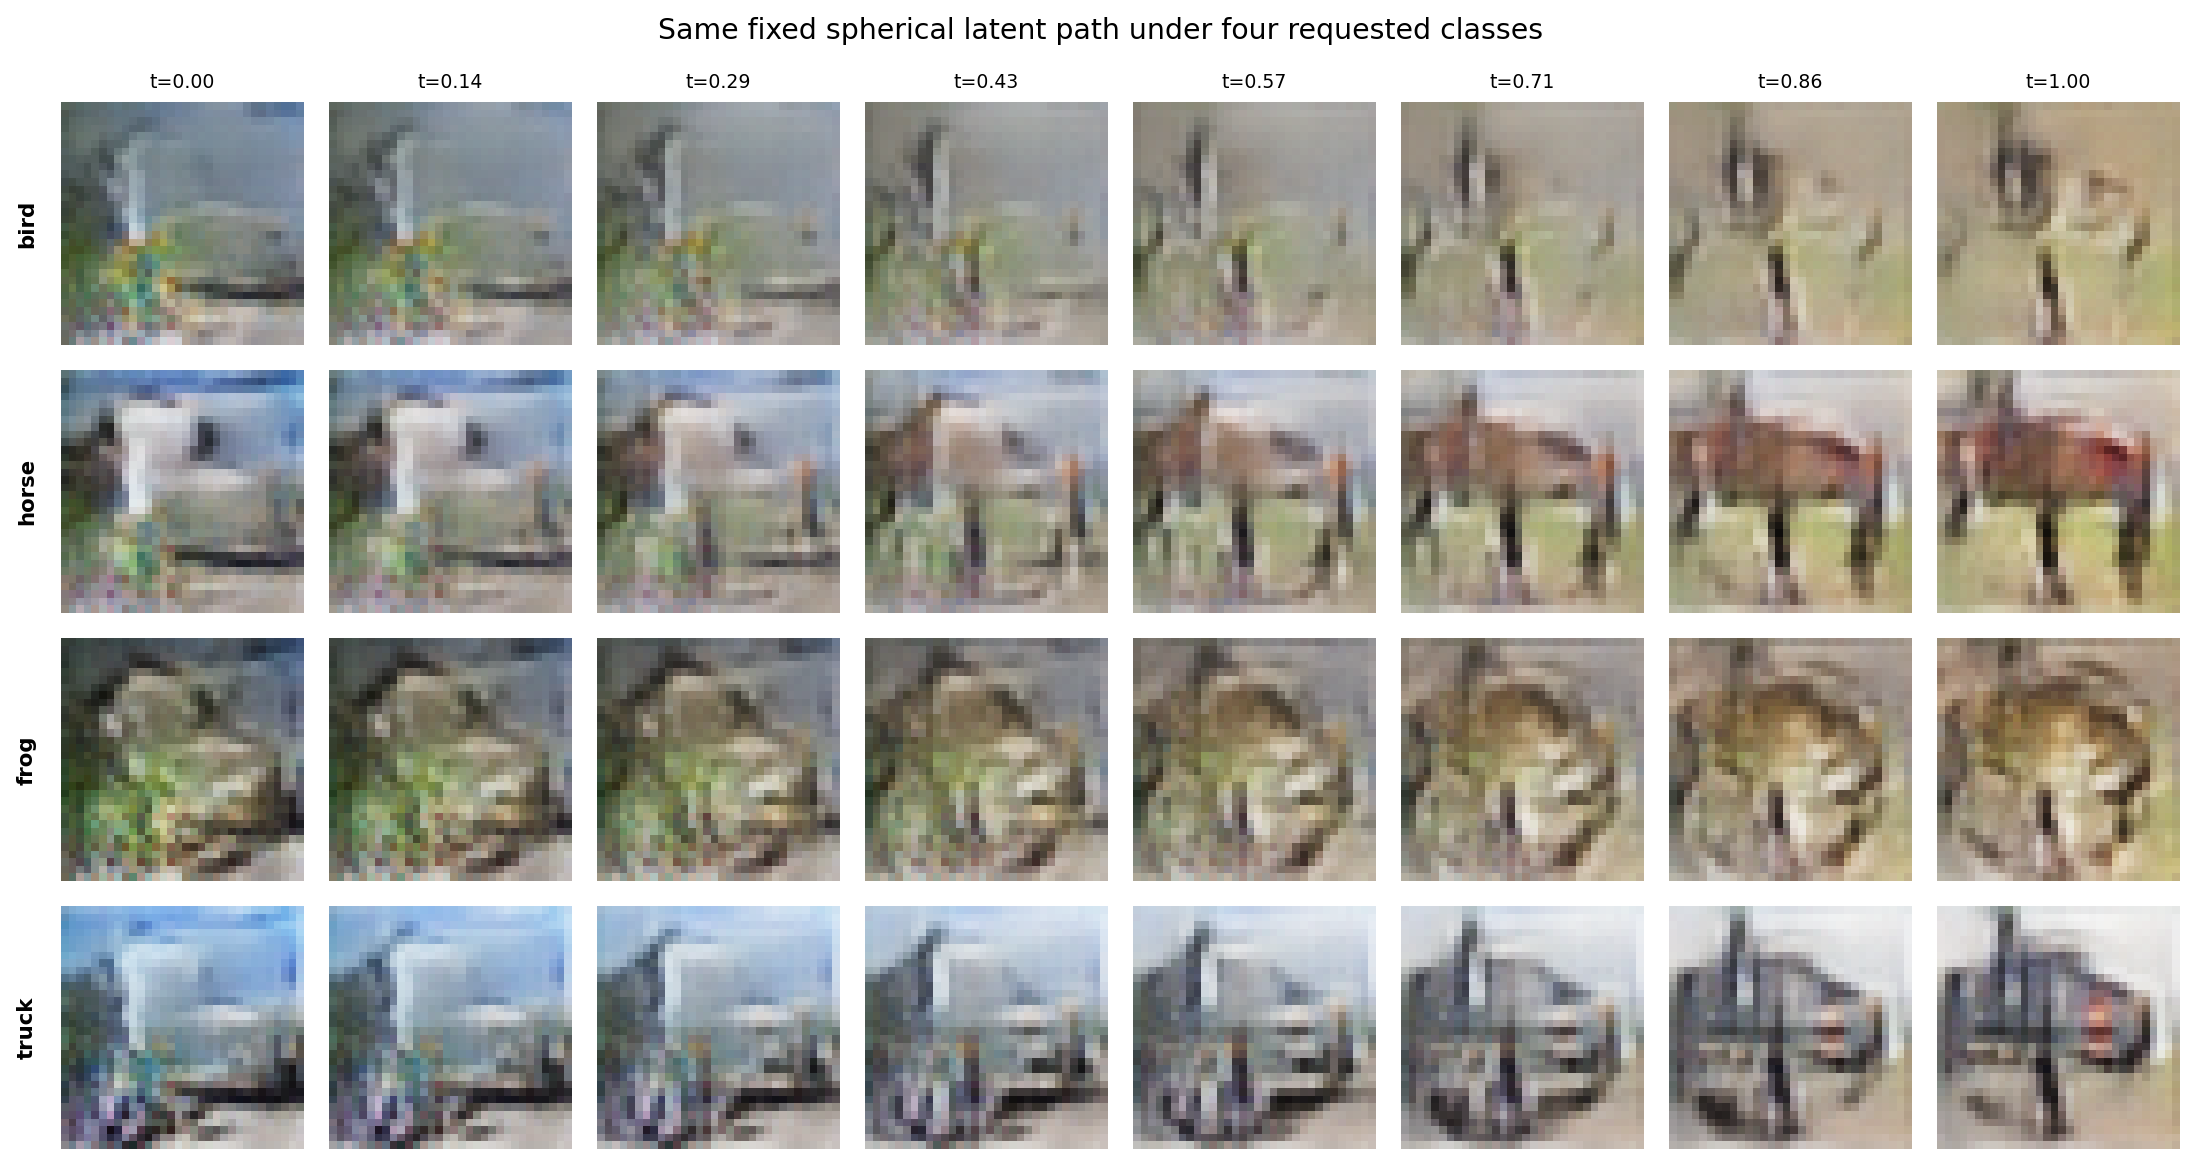

In [67]:
figure, axes = plt.subplots(4, 8, figsize=(13, 7))
for row, class_id in enumerate(interpolation_class_ids):
    for column, value in enumerate(interpolation_values):
        index = row * len(interpolation_values) + column
        axis = axes[row, column]
        axis.imshow(
            interpolation_images[index],
            interpolation="nearest",
        )
        axis.axis("off")
        if row == 0:
            axis.set_title(f"t={value:.2f}", fontsize=8)
        if column == 0:
            axis.text(
                -0.10,
                0.5,
                class_names[class_id],
                transform=axis.transAxes,
                rotation=90,
                va="center",
                ha="right",
                fontsize=9,
                fontweight="bold",
            )

figure.suptitle(
    "Same fixed spherical latent path under four requested classes"
)
figure.tight_layout()
LATENT_INTERPOLATION_PATH = (
    FINAL_FIGURE_DIR / "final_latent_interpolation.png"
)
figure.savefig(
    LATENT_INTERPOLATION_PATH,
    dpi=170,
    bbox_inches="tight",
)
plt.show()


### Latent-space finding

Adjacent images change smoothly along the fixed path without abrupt jumps. The class label changes broad shape and colour while the latent path controls composition within each row. Some endpoints still share similar layouts across classes, so this supports local continuity but not complete class separation.

## 12.6 Final Evaluation Decision

| Question | Result | Decision evidence |
|---|---:|---|
| Did performance transfer to unseen real images? | Official-test FID `68.38`; checkpoint validation FID `70.07` | The close result supports the validation-based selection; FID still does not measure recognisability directly |
| Does the generator respond to the requested class? | Export match `79.6%`; checkpoint validation match `76.40%` | Class behaviour transferred to the frozen export, within the evaluator's `83.11%` real-test accuracy limit |
| Are the objects visually recognisable? | `71` clear, `26` marginal, `3` nonsense | Most images contain plausible structure, but clarity remains uneven across classes |
| Is there obvious repetition or exact copying? | `0` duplicate groups; `0` exact training matches | No exact repetition was found, although near-duplication is outside this check |
| Is within-class variation balanced? | Seven classes fall below their real feature-diversity reference | Coverage remains weaker for several classes |

### Final decision

I retained the unweighted auxiliary cGAN family because extending it from 30 to 60 epochs improved both FID and requested-class match for all three seeds. Weak-class weighting beat its paired parent on FID and overall class match in only one of three seeds, so it did not replace the simpler parent. Within the predeclared seed-42 run, epoch 55 dominated epoch 60 on both validation measures and was frozen before official test performance evaluation.


# 13. H5 Verification and Export


In [68]:
import shutil
import zipfile

FINAL_WEIGHT_PATH = Path(
    "ST1504_CA2_Part_A_Best_Generator.weights.h5"
)
shutil.copy2(SELECTED_GENERATOR_WEIGHT_PATH, FINAL_WEIGHT_PATH)

verified_generator = build_conditional_generator()
verified_generator.load_weights(FINAL_WEIGHT_PATH)
evaluated_fixed_output = final_generator(
    [final_noise[:50], final_labels[:50]],
    training=False,
).numpy()
verified_fixed_output = verified_generator(
    [final_noise[:50], final_labels[:50]],
    training=False,
).numpy()
FINAL_RELOAD_MAX_ERROR = float(np.max(np.abs(
    evaluated_fixed_output - verified_fixed_output
)))
assert FINAL_RELOAD_MAX_ERROR < 1e-6

print("Saved weights:", FINAL_WEIGHT_PATH)
print(f"Reload maximum output difference: {FINAL_RELOAD_MAX_ERROR:.10f}")


Saved weights: ST1504_CA2_Part_A_Best_Generator.weights.h5
Reload maximum output difference: 0.0000000000


In [69]:
FINAL_IMAGE_ARCHIVE_PATH = Path(
    "ST1504_CA2_Part_A_1000_Generated_Images.zip"
)
with zipfile.ZipFile(
    FINAL_IMAGE_ARCHIVE_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:
    for path in sorted(FINAL_IMAGE_DIR.glob("*.png")):
        archive.write(
            path,
            arcname=f"generated_images/{path.name}",
        )

    manifest_path = FINAL_TABLE_DIR / "final_image_manifest.csv"
    archive.write(
        manifest_path,
        arcname="final_image_manifest.csv",
    )

with zipfile.ZipFile(FINAL_IMAGE_ARCHIVE_PATH, mode="r") as archive:
    archive_names = archive.namelist()
    png_entries = [
        name for name in archive_names if name.endswith(".png")
    ]
    assert len(png_entries) == FINAL_IMAGE_COUNT
    assert "final_image_manifest.csv" in archive_names
    assert archive.testzip() is None


In [70]:
print("Saved image archive:", FINAL_IMAGE_ARCHIVE_PATH)
print("Generated PNG files:", len(list(FINAL_IMAGE_DIR.glob("*.png"))))
print("Images per requested class:", FINAL_IMAGES_PER_CLASS)
print("Verified ZIP entries:", len(archive_names))


Saved image archive: ST1504_CA2_Part_A_1000_Generated_Images.zip
Generated PNG files: 1000
Images per requested class: 100
Verified ZIP entries: 1001


# 14. Limitations and Conclusion

## 14.1 Would Black-and-White Generation Be Easier?

A one-channel model would generate fewer values and remove colour variation, but it would also discard cues that help distinguish CIFAR-10 objects from their backgrounds. Converting RGB outputs after training would not test this fairly; the full pipeline would need to be retrained on grayscale data. I retained RGB because it preserves the assigned data and the required coloured output.

## 14.2 Limitations

- FID uses ImageNet Inception features after resizing `32 x 32` images and has finite-sample bias. One fixed in-memory preprocessing path makes the experiments comparable but does not remove those limitations.
- The class evaluator is imperfect. It achieved `83.11%` on real official-test images, with only `64.0%` recall for cat, and may respond to colour or texture without a coherent object.
- Exact matching does not detect near-duplicates, while pairwise feature distance measures variation rather than realism.
- Seven classes had lower generated feature diversity than their real reference. Higher ratios for three vehicle classes may also include inconsistent structure.
- The visual review contains ten images per class and one set of ratings. Its class-level percentages are descriptive supporting evidence, not precise estimates.
- The same validation partition supports several sequential model and checkpoint decisions. The separate official-test result limits this risk, but some selection optimism may remain.
- Three paired training seeds support the main comparisons, but they do not represent every possible initialisation or software environment.
- Reloading the saved H5 into a rebuilt generator reproduced the checked outputs exactly. Reproducibility across different TensorFlow or hardware versions was not tested.

## 14.3 Conclusion

- Across three seeds, the VAE had FID `217.96 +/- 1.79`, while the unconditional GAN improved this to `90.88 +/- 6.01`.
- Projection conditioning improved mean FID further to `71.26 +/- 2.60` and achieved `54.64%` requested-class match.
- The 30-epoch auxiliary objective improved class match to `61.49%` but worsened FID to `95.64`, exposing a fidelity-versus-control trade-off.
- Continuing that same model to 60 epochs improved every paired seed, reaching mean FID `64.13 +/- 5.73` and class match `76.90% +/- 1.23%`.
- Weak-class weighting reached mean FID `61.86 +/- 0.84` and class match `76.93% +/- 0.55%`, but beat the unweighted parent on both main measures in only one of three paired runs. I rejected it as an inconsistent replacement.
- The frozen epoch-55 generator achieved official-test FID `68.38`, `79.6%` requested-class match, `71%` clear images, and no exact duplicate or training-image matches in the 1,000-image export.

The auxiliary cGAN is the strongest repeatable model family in this investigation, and epoch 55 is its best seed-42 validation checkpoint. It improves substantially over both baselines without adding inference parameters, but frog clarity and reduced diversity in several classes remain unresolved.


# 15. References

1. Krizhevsky, A. (2009). [Learning Multiple Layers of Features from Tiny Images](https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf).
2. Barz, B., and Denzler, J. (2020). [Do We Train on Test Data? Purging CIFAR of Near-Duplicates](https://arxiv.org/abs/1902.00423).
3. Northcutt, C. G., Athalye, A., and Mueller, J. (2021). [Pervasive Label Errors in Test Sets Destabilize Machine Learning Benchmarks](https://datasets-benchmarks-proceedings.neurips.cc/paper/2021/hash/f2217062e9a397a1dca429e7d70bc6ca-Abstract-round1.html).
4. Kingma, D. P., and Welling, M. (2014). [Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114).
5. Goodfellow, I. et al. (2014). [Generative Adversarial Nets](https://papers.neurips.cc/paper_files/paper/2014/hash/f033ed80deb0234979a61f95710dbe25-Abstract.html).
6. Radford, A., Metz, L., and Chintala, S. (2016). [Unsupervised Representation Learning with Deep Convolutional Generative Adversarial Networks](https://arxiv.org/abs/1511.06434).
7. Odena, A., Dumoulin, V., and Olah, C. (2016). [Deconvolution and Checkerboard Artifacts](https://distill.pub/2016/deconv-checkerboard/).
8. Heusel, M. et al. (2017). [GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium](https://proceedings.neurips.cc/paper/2017/hash/8a1d694707eb0fefe65871369074926d-Abstract.html).
9. Salimans, T. et al. (2016). [Improved Techniques for Training GANs](https://papers.nips.cc/paper_files/paper/2016/hash/8a3363abe792db2d8761d6403605aeb7-Abstract.html).
10. Chong, M. J., and Forsyth, D. (2020). [Effectively Unbiased FID and Inception Score and Where to Find Them](https://arxiv.org/abs/1911.07023).
11. Parmar, G., Zhang, R., and Zhu, J.-Y. (2022). [On Aliased Resizing and Surprising Subtleties in GAN Evaluation](https://arxiv.org/abs/2104.11222).
12. Binkowski, M. et al. (2018). [Demystifying MMD GANs](https://arxiv.org/abs/1801.01401).
13. Barratt, S., and Sharma, R. (2018). [A Note on the Inception Score](https://arxiv.org/abs/1801.01973).
14. Sajjadi, M. S. M. et al. (2018). [Assessing Generative Models via Precision and Recall](https://proceedings.neurips.cc/paper/2018/hash/f7696a9b362ac5a51c3dc8f098b73923-Abstract.html).
15. Kynkaanniemi, T. et al. (2019). [Improved Precision and Recall Metric for Assessing Generative Models](https://proceedings.neurips.cc/paper/2019/hash/0234c510bc6d908b28c70ff313743079-Abstract.html).
16. Zhao, S. et al. (2020). [Differentiable Augmentation for Data-Efficient GAN Training](https://proceedings.neurips.cc/paper/2020/hash/55479c55ebd1efd3ff125f1337100388-Abstract.html).
17. Mirza, M., and Osindero, S. (2014). [Conditional Generative Adversarial Nets](https://arxiv.org/abs/1411.1784).
18. Odena, A., Olah, C., and Shlens, J. (2017). [Conditional Image Synthesis with Auxiliary Classifier GANs](https://proceedings.mlr.press/v70/odena17a.html).
19. Keras. [Weights-Only Saving and Loading](https://keras.io/guides/serialization_and_saving/#apis-for-saving-weights-to-disk-loading-them-back).
20. Singapore Polytechnic. *ST1504 Topic 5: Generative Adversarial Networks*, module notes.
21. Singapore Polytechnic. *ST1504 Lab 5*, practical materials.
22. Miyato, T., and Koyama, M. (2018). [cGANs with Projection Discriminator](https://openreview.net/forum?id=ByS1VpgRZ).
